# Trabalho 2 — Metodologias para Extração de Conhecimento (KDD)

**Disciplina:** Mineração de Dados e Aprendizado de Máquina

**Conjuntos de dados:** *Breast Cancer Wisconsin (Diagnóstico)* e *Wine (UCI)*

Este notebook percorre as sete etapas do processo de descoberta de conhecimento (KDD) descritas na proposta do trabalho, aplicadas a dois conjuntos de dados com **atributos contínuos e rótulos discretos**:

| Etapa KDD | Seção do notebook |
|---|---|
| 1. Compreensão do problema e hipóteses | Seção 1 |
| 2. Seleção dos dados | Seção 2 |
| 3. Pré-processamento (limpeza, outliers, padronização) | Seção 3 |
| 4. Transformação (redução de dimensionalidade) | Seção 4 |
| 5. Mineração — agrupamento (0% rotulado) e classificação semi-supervisionada (5% a 70% rotulado) | Seção 5 |
| 6. Avaliação e interpretação (etapa central do trabalho) | Seção 6 |
| 7. Pós-processamento (opcional) | Seção 7 |

Requisitos da proposta atendidos:

- **Classificação semi-supervisionada** variando a taxa de pontos rotulados de **0.05 a 0.70**, com **KNN** e **Regressão Logística** como *baselines*.
- **Agrupamento** com **K-Médias** e **DBSCAN**, tratados como o caso-limite em que **0 pontos são rotulados**.

Todas as figuras são exibidas no notebook e salvas em `results_notebook/figures/`. As tabelas de métricas são salvas em `results_notebook/metrics/`.

## 0. Configuração do ambiente

Bibliotecas, sementes aleatórias (reprodutibilidade), pastas de saída e funções auxiliares de visualização.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from matplotlib.ticker import MaxNLocator
import sklearn
from IPython.display import display
from scipy import stats
from scipy.optimize import linear_sum_assignment

from sklearn.base import clone
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.manifold import SpectralEmbedding
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans, DBSCAN
from sklearn.semi_supervised import LabelPropagation, LabelSpreading, SelfTrainingClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    adjusted_rand_score,
    adjusted_mutual_info_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    silhouette_score,
    silhouette_samples,
)
from sklearn.exceptions import ConvergenceWarning

# Os algoritmos iterativos (Label Propagation, Regressão Logística sem padronização) podem emitir
# avisos de convergência; eles são silenciados para manter a saída legível.
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
TAXAS_ROTULADOS = [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
N_REPETICOES = 10

PASTA_RESULTADOS = Path("results_notebook")
PASTA_FIGURAS = PASTA_RESULTADOS / "figures"
PASTA_METRICAS = PASTA_RESULTADOS / "metrics"
for pasta in (PASTA_FIGURAS, PASTA_METRICAS):
    pasta.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 90,
    "savefig.dpi": 200,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "figure.titlesize": 14,
    "figure.titleweight": "bold",
})

FIGURAS_GERADAS = []


def salvar_figura(fig, nome):
    """Salva a figura em PNG (200 DPI) na pasta de resultados e a exibe no notebook."""
    caminho = PASTA_FIGURAS / f"{nome}.png"
    fig.savefig(caminho, bbox_inches="tight")
    if caminho.name not in FIGURAS_GERADAS:
        FIGURAS_GERADAS.append(caminho.name)
    plt.show()


print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 1. Compreensão do problema e hipóteses (Etapa 1)

**Breast Cancer Wisconsin (Diagnóstico).** Cada amostra corresponde a uma imagem digitalizada de uma punção aspirativa por agulha fina (PAAF) de um nódulo mamário. São 30 atributos reais que descrevem os núcleos celulares: 10 medidas (raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal), cada uma resumida por *média*, *erro padrão* e *pior valor* (média dos três maiores). O rótulo é o diagnóstico (maligno/benigno). Na prática, rotular exige um patologista, por isso é um cenário natural para aprendizado com poucos rótulos.

**Wine.** Resultado da análise química de vinhos produzidos na mesma região da Itália a partir de três cultivares diferentes. São 13 atributos contínuos (álcool, ácido málico, cinzas, alcalinidade das cinzas, magnésio, fenóis totais, flavonoides, fenóis não flavonoides, proantocianidinas, intensidade de cor, matiz, OD280/OD315 e prolina). O rótulo é a cultivar.

**Objetivo.** Medir quanto conhecimento sobre as classes pode ser extraído com supervisão parcial: de **nenhum rótulo** (agrupamento) até **70% de rótulos** (semi-supervisionado), comparando com *baselines* supervisionados que usam apenas os pontos rotulados.

**Hipóteses (com critério objetivo, verificadas na Seção 6):**

| # | Hipótese | Critério de verificação |
|---|---|---|
| H1 | As classes do Breast Cancer são (quase) linearmente separáveis. A documentação original (`wdbc.names`) afirma separabilidade linear com os 30 atributos. | Regressão Logística com 100% dos rótulos atinge F1-macro ≥ 0,95 no teste. |
| H2 | Com poucos rótulos (5% e 10%), o melhor método semi-supervisionado supera o melhor *baseline*. | Em cada taxa, ΔF1 = F1(melhor semi da taxa) − F1(melhor *baseline* da taxa). A taxa é "confirmada" se ΔF1 > 0 e o Wilcoxon pareado dá p < 0,05; "inconclusiva" se ΔF1 > 0 mas p ≥ 0,05; "refutada" se ΔF1 ≤ 0. |
| H3 | A vantagem do semi-supervisionado diminui conforme aumenta a taxa de rótulos. | ΔF1 (mesma definição de H2) a 70% < ΔF1 a 5%. |
| H4 | O K-Médias recupera melhor as cultivares do Wine do que os diagnósticos do Breast Cancer. | ARI(Wine) > ARI(Breast Cancer) com k = número de classes. |
| H5 | O DBSCAN (parâmetros dos scripts) recupera as classes pior que o K-Médias. | ARI(DBSCAN) < ARI(K-Médias). |
| H6 | Duas componentes principais preservam a maior parte da separabilidade das classes. | F1 (KNN, validação cruzada) no PCA-2D ≥ 90% do F1 no espaço padronizado completo. |

## 2. Seleção dos dados (Etapa 2)

Os dois conjuntos são carregados diretamente do `scikit-learn` (cópias dos arquivos da UCI). Ambos atendem à proposta: **atributos contínuos** e **rótulo discreto**, ou seja, problemas de classificação, e não de regressão. Como os conjuntos são pequenos (569 e 178 amostras), usamos os dados completos, sem amostragem.

In [2]:
def carregar_datasets():
    bc = load_breast_cancer()
    wine = load_wine()
    dados = {
        "breast_cancer": {
            "titulo": "Breast Cancer Wisconsin",
            "X": pd.DataFrame(bc.data, columns=bc.feature_names),
            "y": bc.target.copy(),           # 0 = maligno, 1 = benigno
            "classes": ["Maligno", "Benigno"],
        },
        "wine": {
            "titulo": "Wine",
            "X": pd.DataFrame(wine.data, columns=wine.feature_names),
            "y": wine.target.copy(),         # 0, 1, 2 = cultivares
            "classes": ["Cultivar 0", "Cultivar 1", "Cultivar 2"],
        },
    }
    # Conferência da codificação dos rótulos com a documentação dos datasets
    assert list(bc.target_names) == ["malignant", "benign"]
    assert list(np.bincount(bc.target)) == [212, 357]
    assert list(np.bincount(wine.target)) == [59, 71, 48]
    return dados


DADOS = carregar_datasets()
PALETA_CLASSES = sns.color_palette("Set2", 3)

resumo = []
for nome, d in DADOS.items():
    X, y = d["X"], d["y"]
    contagem = np.bincount(y)
    resumo.append({
        "Dataset": d["titulo"],
        "Amostras": X.shape[0],
        "Atributos": X.shape[1],
        "Tipo dos atributos": ", ".join(sorted({str(t) for t in X.dtypes})),
        "Valores distintos por atributo (mediana)": int(X.nunique().median()),
        "Classes": len(contagem),
        "Distribuição": " | ".join(f"{c}: {n} ({n / len(y):.1%})" for c, n in zip(d["classes"], contagem)),
        "Razão maior/menor classe": round(contagem.max() / contagem.min(), 2),
    })
display(pd.DataFrame(resumo).set_index("Dataset").T)

Dataset,Breast Cancer Wisconsin,Wine
Amostras,569,178
Atributos,30,13
Tipo dos atributos,float64,float64
Valores distintos por atributo (mediana),525,101
Classes,2,3
Distribuição,Maligno: 212 (37.3%) | Benigno: 357 (62.7%),Cultivar 0: 59 (33.1%) | Cultivar 1: 71 (39.9%...
Razão maior/menor classe,1.68,1.48


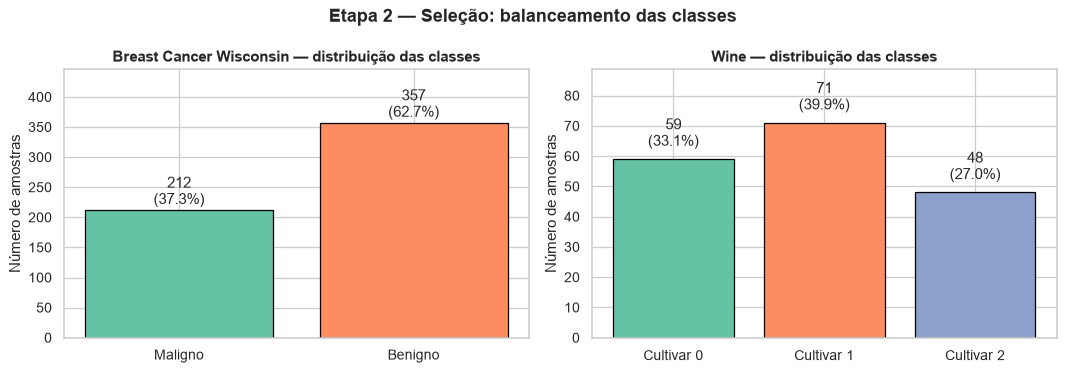

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (nome, d) in zip(axes, DADOS.items()):
    contagem = np.bincount(d["y"])
    barras = ax.bar(d["classes"], contagem, color=PALETA_CLASSES[: len(contagem)], edgecolor="black")
    for b, n in zip(barras, contagem):
        ax.text(b.get_x() + b.get_width() / 2, n + 3, f"{n}\n({n / contagem.sum():.1%})", ha="center", va="bottom")
    ax.set_title(f"{d['titulo']} — distribuição das classes")
    ax.set_ylabel("Número de amostras")
    ax.set_ylim(0, contagem.max() * 1.25)
fig.suptitle("Etapa 2 — Seleção: balanceamento das classes")
plt.tight_layout()
salvar_figura(fig, "E2_distribuicao_classes")

In [4]:
for nome, d in DADOS.items():
    print(f"Estatísticas descritivas — {d['titulo']}")
    display(d["X"].describe().T.round(3))

Estatísticas descritivas — Breast Cancer Wisconsin


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


Estatísticas descritivas — Wine


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


## 3. Pré-processamento (Etapa 3)

Nesta etapa verificamos a qualidade dos dados (valores ausentes, duplicatas, atributos constantes), investigamos *outliers*, identificamos os atributos mais discriminativos e escolhemos a padronização. A análise exploratória usa o conjunto completo. Toda decisão que alimenta os modelos (padronização, PCA, hiperparâmetros) é ajustada **apenas no conjunto de treino**.

### 3.1 Qualidade dos dados

In [5]:
qualidade = []
for nome, d in DADOS.items():
    X = d["X"]
    qualidade.append({
        "Dataset": d["titulo"],
        "Valores ausentes": int(X.isna().sum().sum()),
        "Linhas duplicadas": int(X.duplicated().sum()),
        "Atributos constantes": int((X.nunique() <= 1).sum()),
        "Valores negativos": int((X < 0).sum().sum()),
        "Faixa de escalas (máx/mín do desvio padrão)": round(X.std().max() / X.std().min(), 1),
    })
display(pd.DataFrame(qualidade).set_index("Dataset"))

,Valores ausentes,Linhas duplicadas,Atributos constantes,Valores negativos,Faixa de escalas (máx/mín do desvio padrão)
Dataset,,,,,
Breast Cancer Wisconsin,0,0,0,0,215170.7
Wine,0,0,0,0,2530.3


Não há valores ausentes, duplicatas nem atributos constantes, então nenhuma limpeza de registros é necessária. Por outro lado, a razão entre o maior e o menor desvio padrão mostra atributos em **escalas muito diferentes** (por exemplo, `area` contra `smoothness` no Breast Cancer e `proline` contra `hue` no Wine). Por isso a padronização é obrigatória para métodos baseados em distância (KNN, grafos de vizinhança, K-Médias e DBSCAN).

### 3.2 *Outliers* (critério de Tukey: 1,5 × IQR)

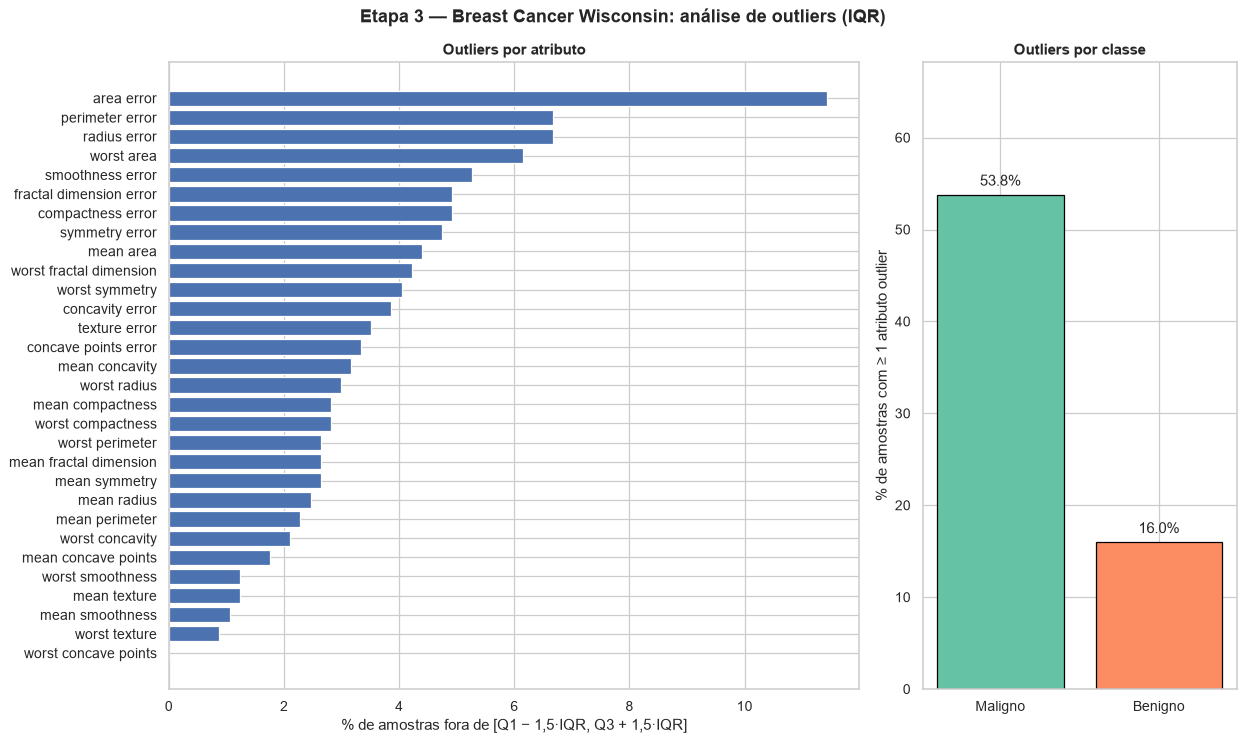

Breast Cancer Wisconsin: 30.1% das amostras têm pelo menos um atributo outlier.
Percentual por classe: {'Maligno': '53.8%', 'Benigno': '16.0%'} 



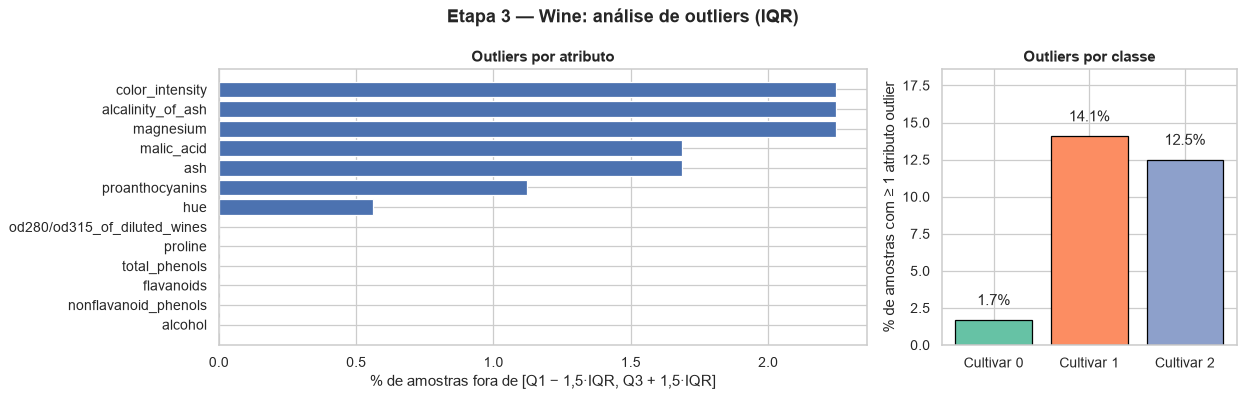

Wine: 9.6% das amostras têm pelo menos um atributo outlier.
Percentual por classe: {'Cultivar 0': '1.7%', 'Cultivar 1': '14.1%', 'Cultivar 2': '12.5%'} 



In [6]:
def mascara_outliers_iqr(X):
    q1, q3 = X.quantile(0.25), X.quantile(0.75)
    iqr = q3 - q1
    return (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)


for nome, d in DADOS.items():
    X, y = d["X"], d["y"]
    mascara = mascara_outliers_iqr(X)
    pct_atributo = (mascara.mean() * 100).sort_values(ascending=True)
    amostra_tem_outlier = mascara.any(axis=1)
    pct_classe = pd.Series(amostra_tem_outlier.groupby(y).mean().values * 100, index=d["classes"])
    d["pct_outliers_classe"] = pct_classe

    fig, axes = plt.subplots(1, 2, figsize=(14, max(4.5, 0.28 * X.shape[1])),
                             gridspec_kw={"width_ratios": [2.2, 1]})
    axes[0].barh(pct_atributo.index, pct_atributo.values, color="#4c72b0")
    axes[0].set_xlabel("% de amostras fora de [Q1 − 1,5·IQR, Q3 + 1,5·IQR]")
    axes[0].set_title("Outliers por atributo")
    axes[1].bar(pct_classe.index, pct_classe.values, color=PALETA_CLASSES[: len(pct_classe)], edgecolor="black")
    for i, v in enumerate(pct_classe.values):
        axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
    axes[1].set_ylabel("% de amostras com ≥ 1 atributo outlier")
    axes[1].set_title("Outliers por classe")
    axes[1].set_ylim(0, max(pct_classe.values) * 1.25 + 1)
    fig.suptitle(f"Etapa 3 — {d['titulo']}: análise de outliers (IQR)")
    plt.tight_layout()
    salvar_figura(fig, f"E3_{nome}_outliers_iqr")
    print(f"{d['titulo']}: {amostra_tem_outlier.mean():.1%} das amostras têm pelo menos um atributo outlier.")
    print("Percentual por classe:", {k: f"{v:.1f}%" for k, v in pct_classe.items()}, "\n")

No Breast Cancer, os *outliers* concentram-se fortemente na classe **maligna**: tumores malignos têm núcleos maiores e mais irregulares, então valores extremos de área, raio e concavidade são **informação diagnóstica, não ruído**. Removê-los apagaria justamente os casos mais típicos de malignidade. **Decisão: os *outliers* são mantidos.** O DBSCAN, que marca pontos de baixa densidade como ruído, é avaliado na Seção 5 justamente por lidar explicitamente com essa característica.

### 3.3 Distribuição padronizada dos atributos por classe

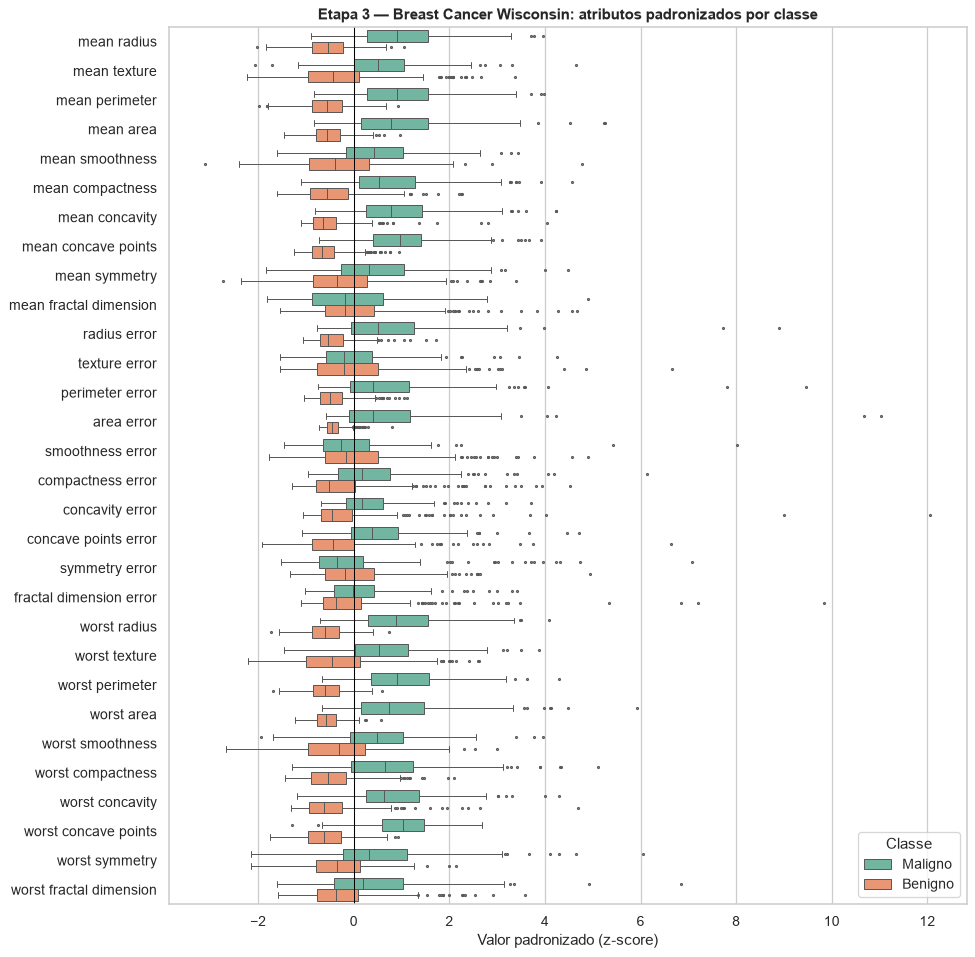

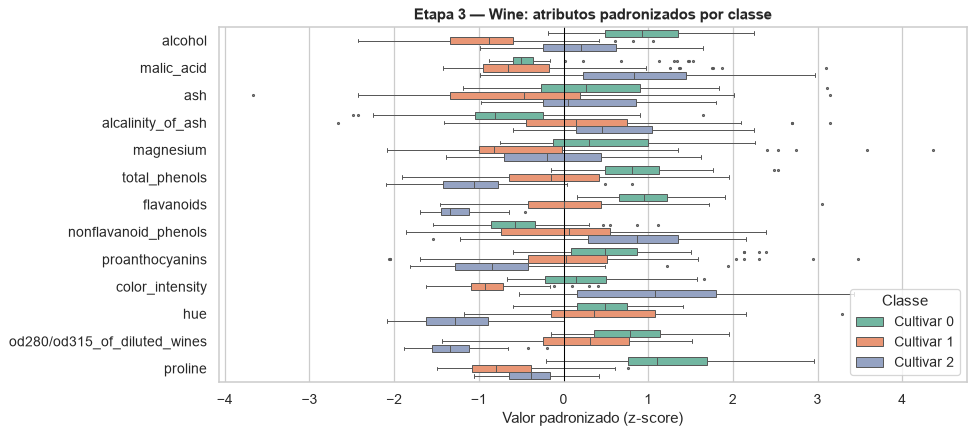

In [7]:
for nome, d in DADOS.items():
    X, y = d["X"], d["y"]
    # Padronização apenas para visualização (média 0, desvio 1 no conjunto completo)
    Z = (X - X.mean()) / X.std()
    longo = Z.assign(Classe=[d["classes"][i] for i in y]).melt(id_vars="Classe", var_name="Atributo", value_name="z")
    fig, ax = plt.subplots(figsize=(11, max(5, 0.36 * X.shape[1])))
    sns.boxplot(data=longo, y="Atributo", x="z", hue="Classe", palette=PALETA_CLASSES[: len(d["classes"])],
                fliersize=1.5, linewidth=0.8, ax=ax)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Valor padronizado (z-score)")
    ax.set_ylabel("")
    ax.set_title(f"Etapa 3 — {d['titulo']}: atributos padronizados por classe")
    ax.legend(title="Classe", loc="lower right")
    plt.tight_layout()
    salvar_figura(fig, f"E3_{nome}_boxplot_padronizado")

### 3.4 Relevância dos atributos (ANOVA F e Informação Mútua)

Duas medidas univariadas de relevância: a estatística **F da ANOVA** (separação linear das médias entre classes) e a **informação mútua** (dependência que também captura relações não lineares). Os 4 atributos com maior F são usados nas visualizações seguintes.

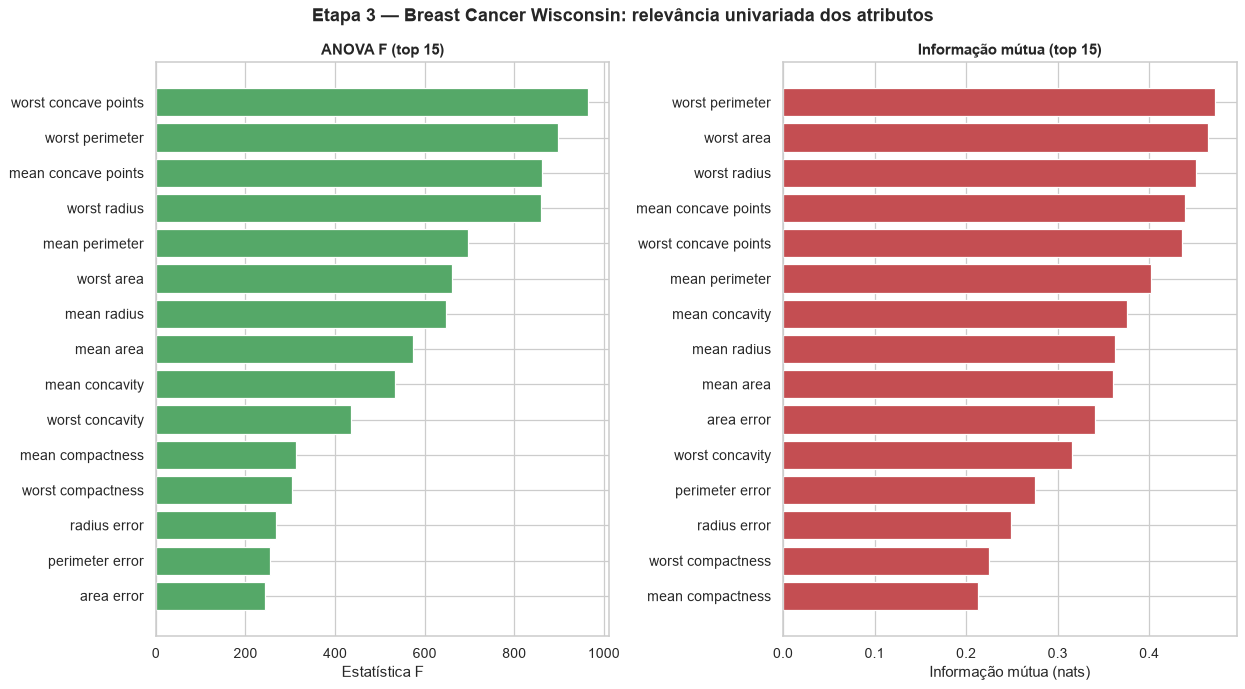

Breast Cancer Wisconsin — top 4 (ANOVA F): ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius'] | correlação de Spearman entre os rankings F e IM: 0.957



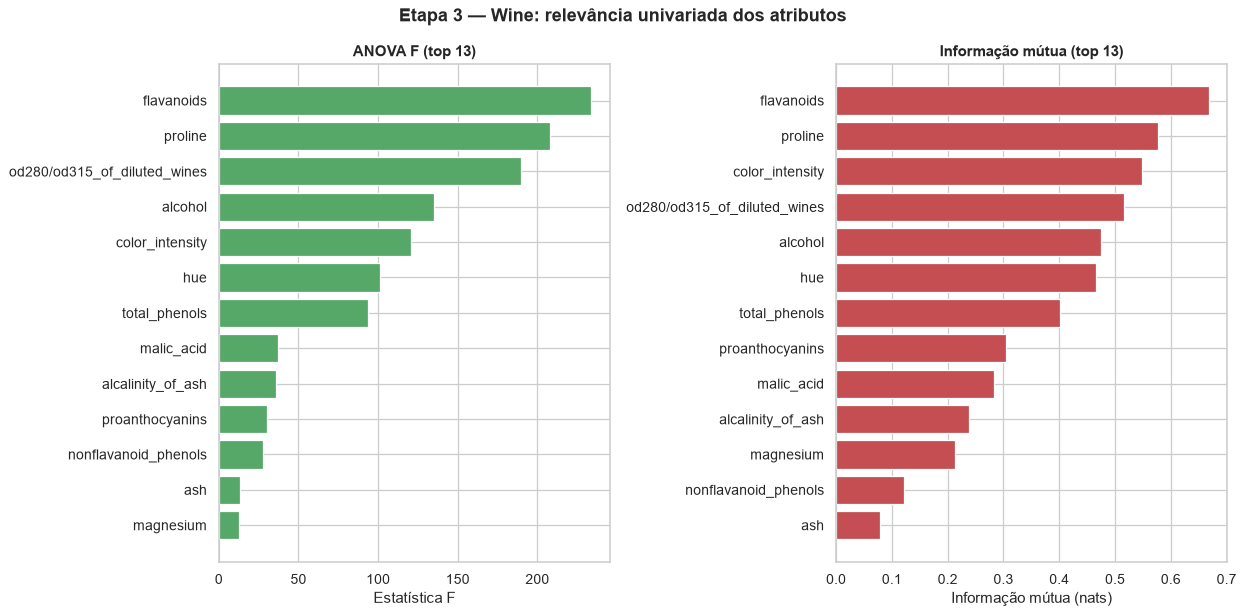

Wine — top 4 (ANOVA F): ['flavanoids', 'proline', 'od280/od315_of_diluted_wines', 'alcohol'] | correlação de Spearman entre os rankings F e IM: 0.951



In [8]:
for nome, d in DADOS.items():
    X, y = d["X"], d["y"]
    F, p = f_classif(X, y)
    mi = mutual_info_classif(X, y, random_state=SEED)
    relevancia = pd.DataFrame({"F_ANOVA": F, "p_valor": p, "Informacao_Mutua": mi}, index=X.columns)
    relevancia = relevancia.sort_values("F_ANOVA", ascending=False)
    d["relevancia"] = relevancia
    d["top_atributos"] = list(relevancia.index[:4])
    relevancia.to_csv(PASTA_METRICAS / f"E3_{nome}_relevancia_atributos.csv")

    n_mostrar = min(15, X.shape[1])
    fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * n_mostrar + 1.5))
    top_f = relevancia["F_ANOVA"].iloc[:n_mostrar][::-1]
    axes[0].barh(top_f.index, top_f.values, color="#55a868")
    axes[0].set_title(f"ANOVA F (top {n_mostrar})")
    axes[0].set_xlabel("Estatística F")
    top_mi = relevancia["Informacao_Mutua"].sort_values(ascending=False).iloc[:n_mostrar][::-1]
    axes[1].barh(top_mi.index, top_mi.values, color="#c44e52")
    axes[1].set_title(f"Informação mútua (top {n_mostrar})")
    axes[1].set_xlabel("Informação mútua (nats)")
    fig.suptitle(f"Etapa 3 — {d['titulo']}: relevância univariada dos atributos")
    plt.tight_layout()
    salvar_figura(fig, f"E3_{nome}_relevancia_atributos")
    rho = stats.spearmanr(relevancia["F_ANOVA"], relevancia["Informacao_Mutua"]).statistic
    print(f"{d['titulo']} — top 4 (ANOVA F): {d['top_atributos']} | "
          f"correlação de Spearman entre os rankings F e IM: {rho:.3f}\n")

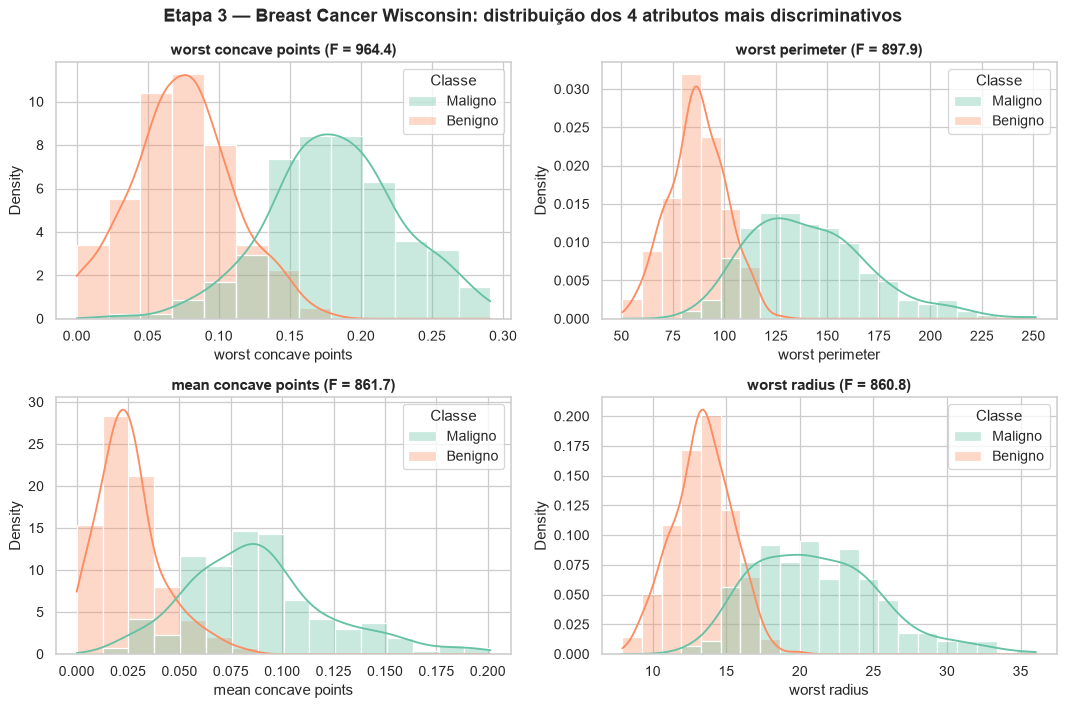

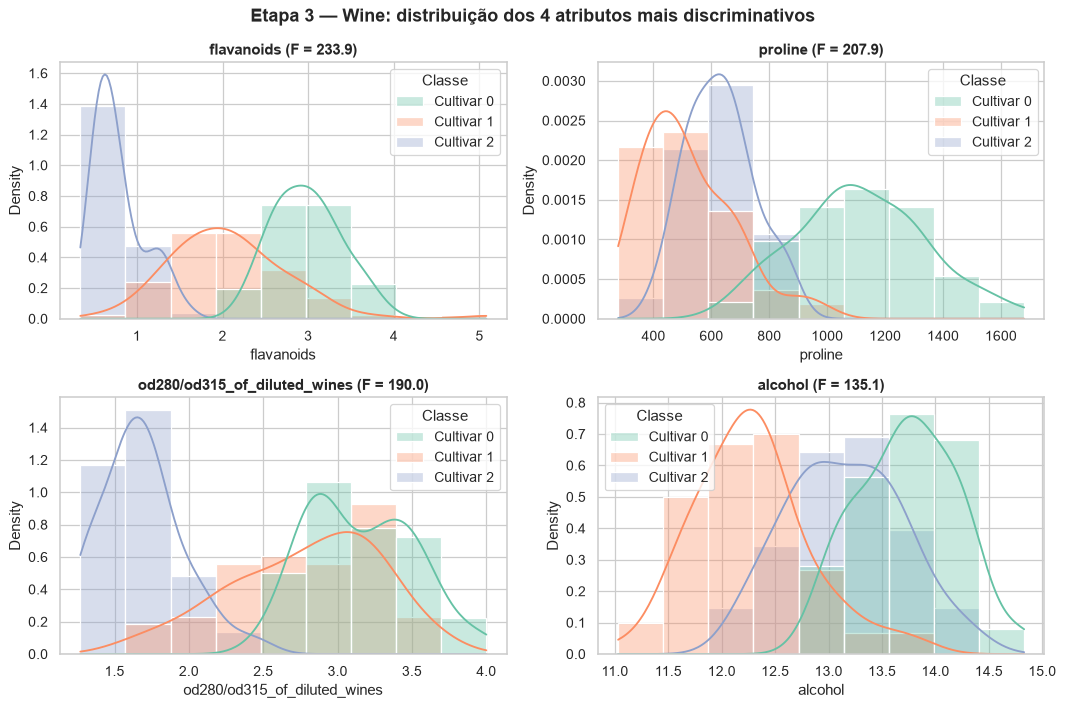

In [9]:
for nome, d in DADOS.items():
    X, y = d["X"], d["y"]
    df_plot = X[d["top_atributos"]].assign(Classe=[d["classes"][i] for i in y])
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for ax, atributo in zip(axes.ravel(), d["top_atributos"]):
        sns.histplot(data=df_plot, x=atributo, hue="Classe", kde=True, stat="density", common_norm=False,
                     palette=PALETA_CLASSES[: len(d["classes"])], alpha=0.35, ax=ax)
        ax.set_title(f"{atributo} (F = {d['relevancia'].loc[atributo, 'F_ANOVA']:.1f})")
    fig.suptitle(f"Etapa 3 — {d['titulo']}: distribuição dos 4 atributos mais discriminativos")
    plt.tight_layout()
    salvar_figura(fig, f"E3_{nome}_distribuicao_top_atributos")

**Atributos usados nos boxplots dos scripts (e da apresentação).** Os scripts mostram três atributos escolhidos manualmente. Todos são fortemente discriminativos, mas **não são exatamente os três primeiros** do ranking ANOVA: o título indica a posição real de cada um. As faixas "entre as caixas" usadas na apresentação são o intervalo entre o 3º quartil de uma classe e o 1º quartil da outra, calculados abaixo.

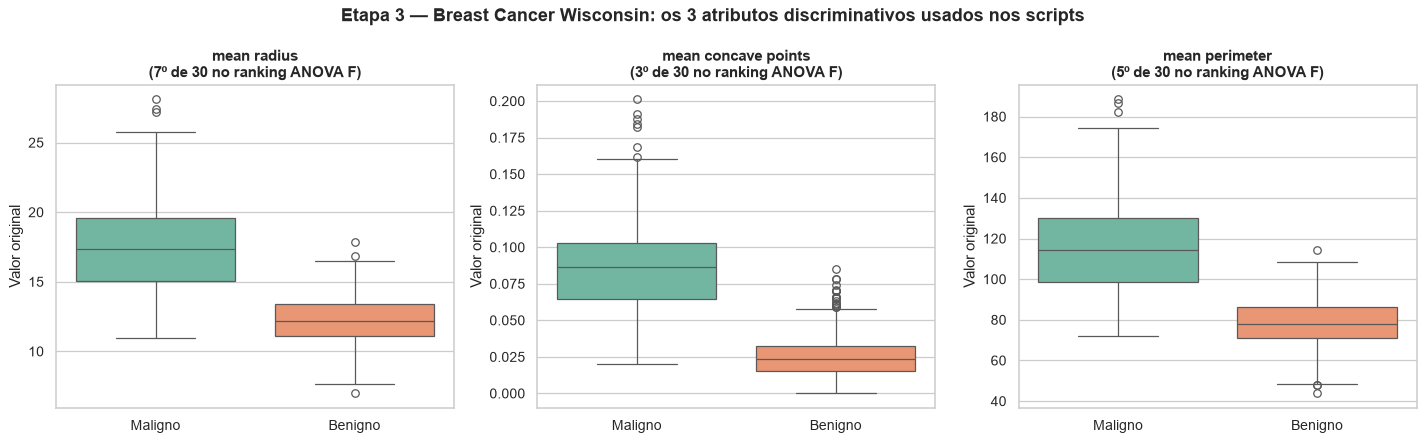

Breast Cancer Wisconsin: 1º e 3º quartis por classe (conjunto completo)


mean radius        mean concave points         mean perimeter         
               0.25   0.75                0.25    0.75           0.25     0.75
Classe                                                                        
Maligno      15.075  19.59              0.0646  0.1032         98.745  129.925
Benigno      11.080  13.37              0.0150  0.0325         70.870   86.100

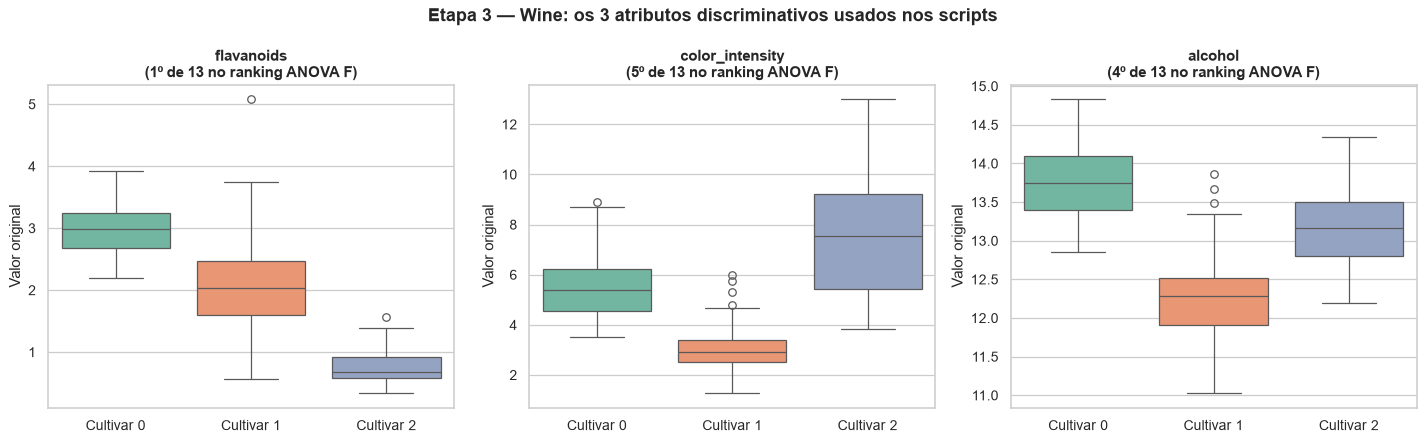

Wine: 1º e 3º quartis por classe (conjunto completo)


flavanoids        color_intensity        alcohol        
                 0.25   0.75            0.25   0.75    0.25    0.75
Classe                                                             
Cultivar 0      2.680  3.245          4.5500  6.225  13.400  14.100
Cultivar 1      1.605  2.475          2.5350  3.400  11.915  12.515
Cultivar 2      0.580  0.920          5.4375  9.225  12.805  13.505

In [10]:
ATRIBUTOS_SCRIPTS = {"breast_cancer": ["mean radius", "mean concave points", "mean perimeter"],
                     "wine": ["flavanoids", "color_intensity", "alcohol"]}
for nome, d in DADOS.items():
    ranking = {a: i + 1 for i, a in enumerate(d["relevancia"].index)}
    df_plot = d["X"][ATRIBUTOS_SCRIPTS[nome]].assign(Classe=[d["classes"][i] for i in d["y"]])
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, atributo in zip(axes, ATRIBUTOS_SCRIPTS[nome]):
        sns.boxplot(data=df_plot, x="Classe", y=atributo, hue="Classe", palette=PALETA_CLASSES[: len(d["classes"])],
                    legend=False, ax=ax)
        ax.set_title(f"{atributo}\n({ranking[atributo]}º de {len(ranking)} no ranking ANOVA F)")
        ax.set_xlabel("")
        ax.set_ylabel("Valor original")
    fig.suptitle(f"Etapa 3 — {d['titulo']}: os 3 atributos discriminativos usados nos scripts")
    plt.tight_layout()
    salvar_figura(fig, f"E3_{nome}_atributos_scripts")

    quartis = df_plot.groupby("Classe", sort=False).quantile([0.25, 0.75]).unstack()
    print(f"{d['titulo']}: 1º e 3º quartis por classe (conjunto completo)")
    display(quartis.round(4))

### 3.5 Correlação entre atributos

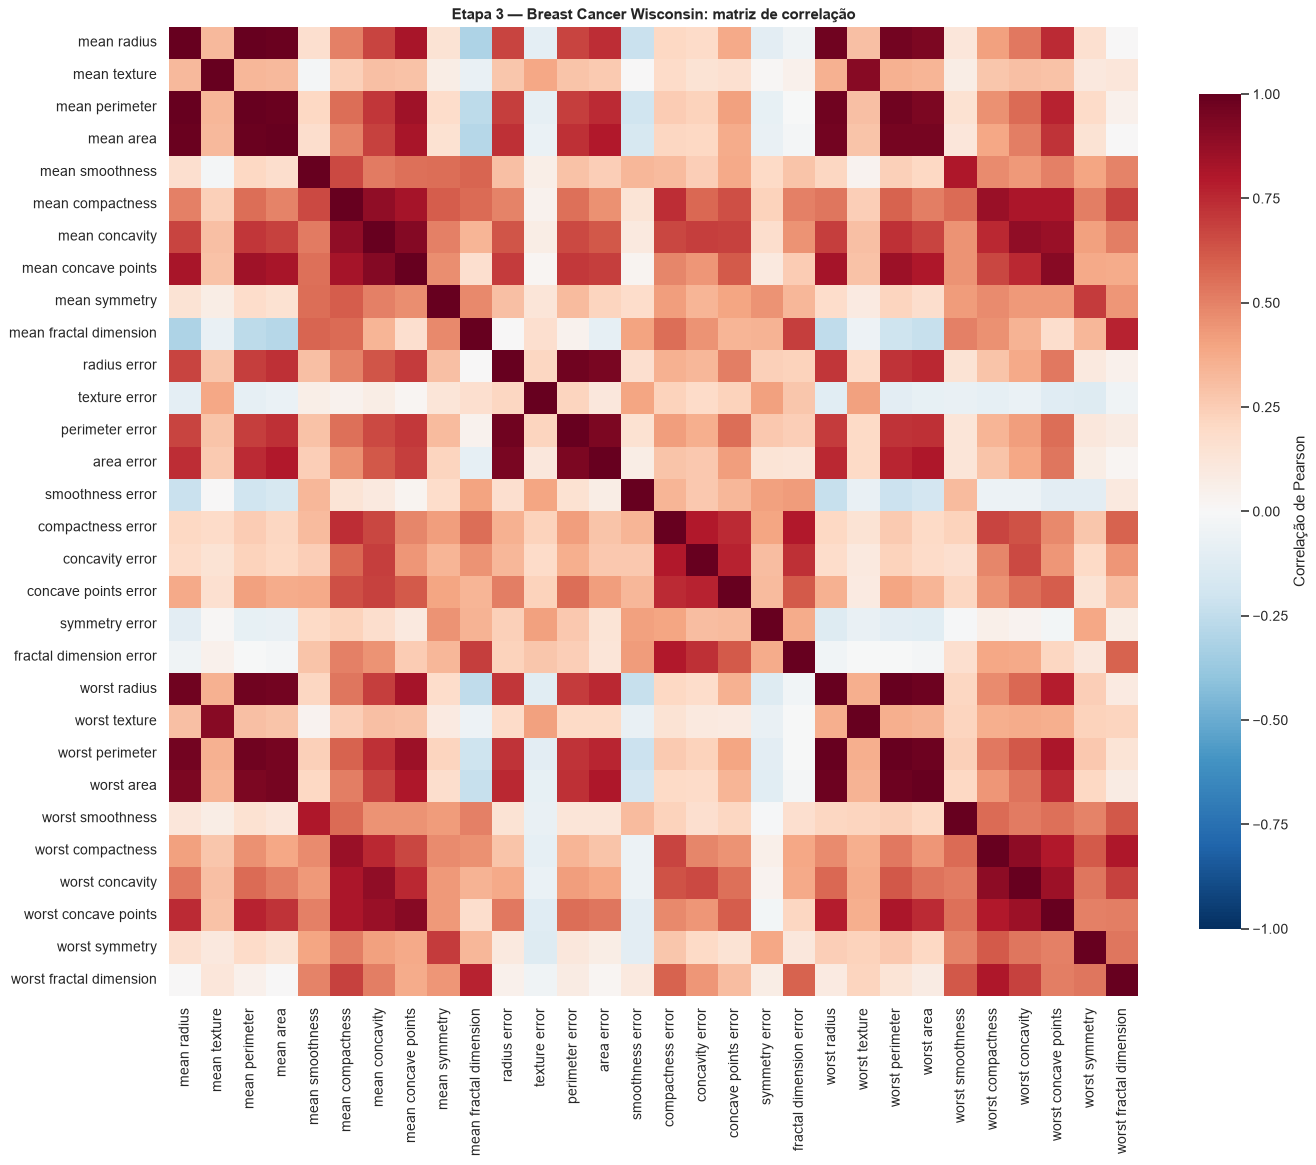

Breast Cancer Wisconsin: 21 de 900 pares de atributos com |r| > 0,9


,,r
mean radius,mean perimeter,0.997855
worst radius,worst perimeter,0.993708
mean radius,mean area,0.987357
mean perimeter,mean area,0.986507
worst radius,worst area,0.984015
worst perimeter,worst area,0.977578
radius error,perimeter error,0.972794
mean perimeter,worst perimeter,0.970387


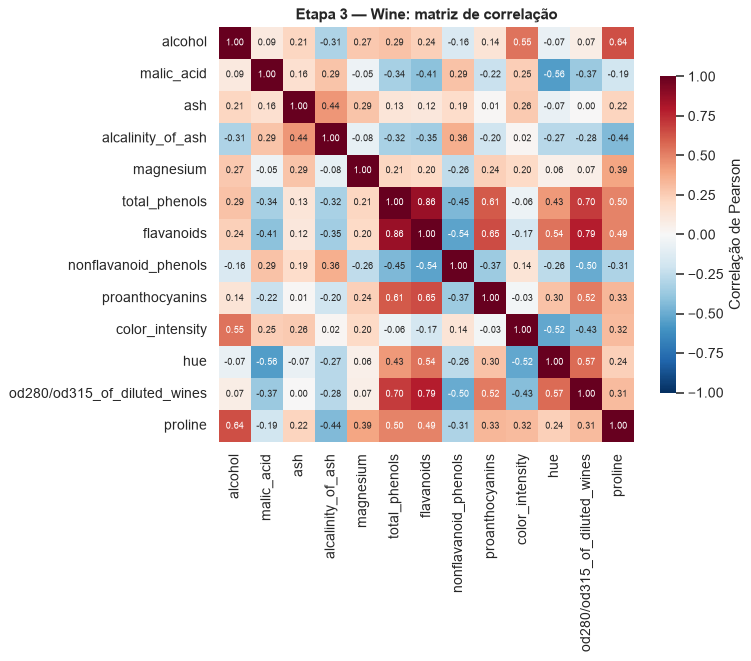

Wine: 0 de 169 pares de atributos com |r| > 0,9


In [11]:
for nome, d in DADOS.items():
    X = d["X"]
    corr = X.corr()
    p = X.shape[1]
    fig, ax = plt.subplots(figsize=(0.42 * p + 3, 0.42 * p + 2))
    sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True, annot=p <= 13, fmt=".2f",
                annot_kws={"size": 7}, cbar_kws={"shrink": 0.7, "label": "Correlação de Pearson"}, ax=ax)
    ax.set_title(f"Etapa 3 — {d['titulo']}: matriz de correlação")
    plt.tight_layout()
    salvar_figura(fig, f"E3_{nome}_correlacao")

    triu = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    fortes = triu[triu.abs() > 0.9].sort_values(key=np.abs, ascending=False)
    d["n_pares_corr_09"] = len(fortes)
    print(f"{d['titulo']}: {len(fortes)} de {len(triu)} pares de atributos com |r| > 0,9")
    if len(fortes):
        display(fortes.head(8).rename("r").to_frame())

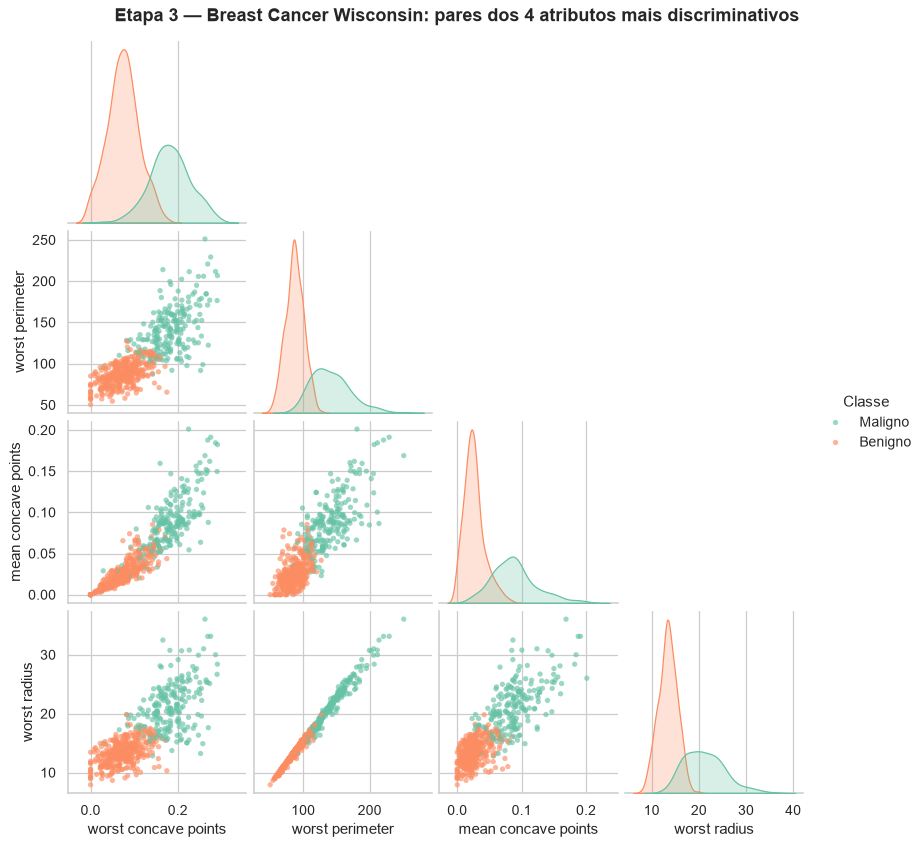

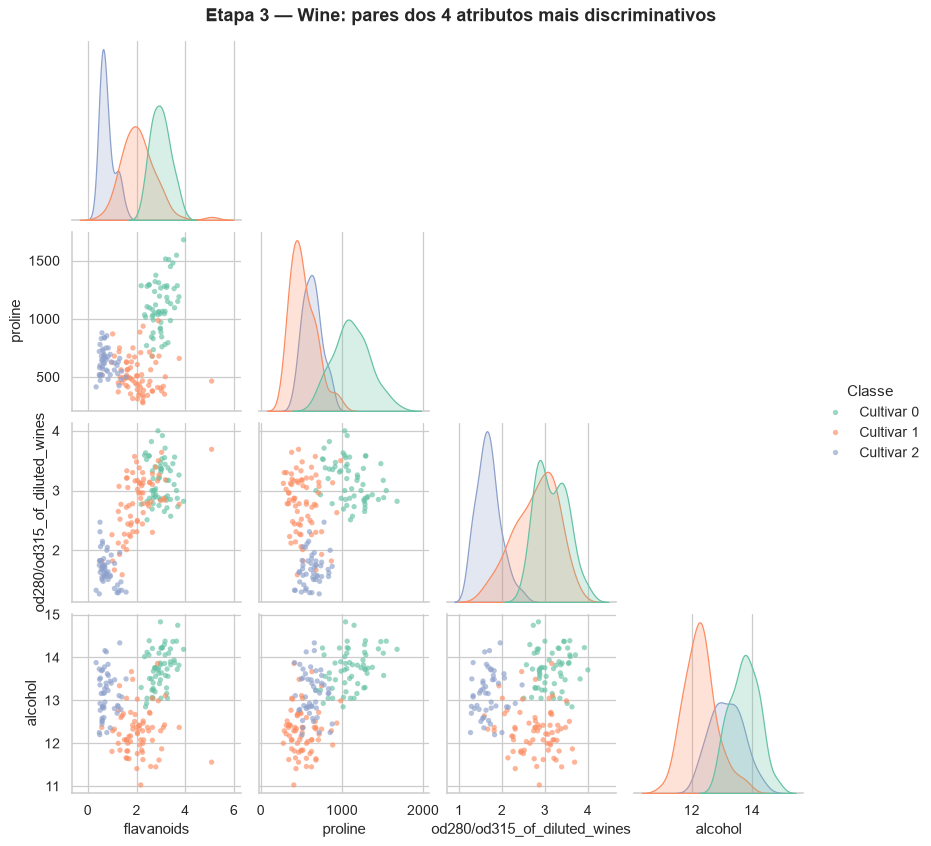

In [12]:
for nome, d in DADOS.items():
    df_plot = d["X"][d["top_atributos"]].assign(Classe=[d["classes"][i] for i in d["y"]])
    g = sns.pairplot(df_plot, hue="Classe", palette=PALETA_CLASSES[: len(d["classes"])], corner=True,
                     diag_kind="kde", plot_kws={"s": 18, "alpha": 0.65, "edgecolor": "none"}, height=2.3)
    g.figure.suptitle(f"Etapa 3 — {d['titulo']}: pares dos 4 atributos mais discriminativos", y=1.02)
    salvar_figura(g.figure, f"E3_{nome}_pairplot")

### 3.6 Partição treino/teste e escolha da padronização

Separamos **25% para teste** de forma estratificada **antes** de qualquer ajuste estatístico. O conjunto de teste fica isolado e serve apenas para medir o desempenho final. Os rótulos de parte do treino serão "escondidos" para simular o cenário semi-supervisionado.

Para justificar a padronização, comparamos via validação cruzada estratificada (5 *folds*, somente no treino) o efeito de diferentes escalonamentos no KNN e na Regressão Logística. Cada escalonador é ajustado dentro do *pipeline* a cada *fold*, sem vazamento de informação.

Breast Cancer Wisconsin: treino = 426 (classes [159, 267]) | teste = 143 (classes [53, 90])
Wine: treino = 133 (classes [44, 53, 36]) | teste = 45 (classes [15, 18, 12])


Escalonamento                                Sem padronização  StandardScaler  \
Dataset                 Modelo                                                  
Breast Cancer Wisconsin KNN (k=5)                      0.9341          0.9642   
                        Regressão Logística            0.9416          0.9773   
Wine                    KNN (k=5)                      0.6317          0.9563   
                        Regressão Logística            0.9713          0.9777   

Escalonamento                                MinMaxScaler  RobustScaler  
Dataset                 Modelo                                           
Breast Cancer Wisconsin KNN (k=5)                  0.9669        0.9590  
                        Regressão Logística        0.9692        0.9748  
Wine                    KNN (k=5)                  0.9704        0.9422  
                        Regressão Logística        0.9854        0.9854

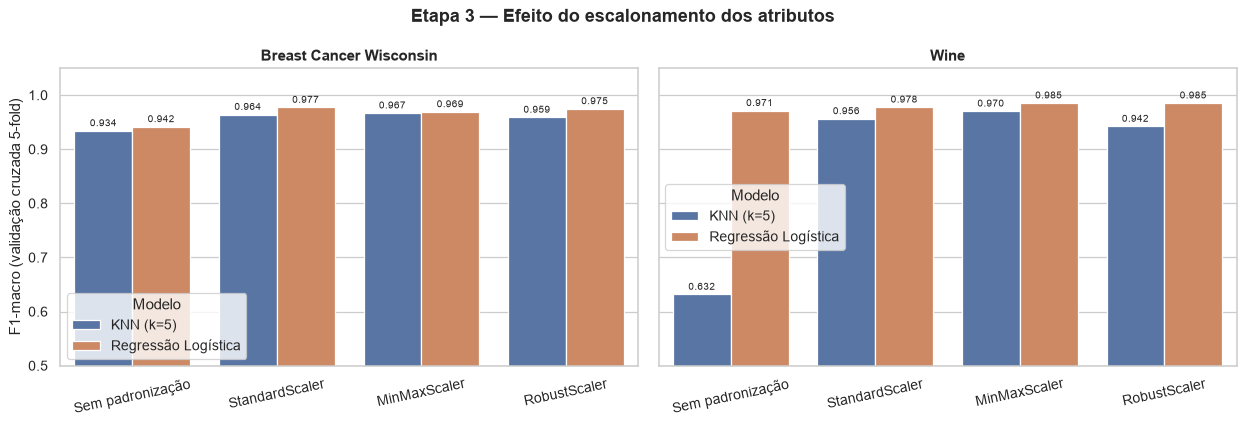

In [13]:
for nome, d in DADOS.items():
    X_tr, X_te, y_tr, y_te = train_test_split(d["X"].values, d["y"], test_size=0.25, stratify=d["y"],
                                              random_state=SEED)
    scaler = StandardScaler().fit(X_tr)
    d.update(X_tr=X_tr, X_te=X_te, y_tr=y_tr, y_te=y_te, scaler=scaler,
             X_tr_sc=scaler.transform(X_tr), X_te_sc=scaler.transform(X_te))
    print(f"{d['titulo']}: treino = {len(y_tr)} (classes {np.bincount(y_tr).tolist()}) | "
          f"teste = {len(y_te)} (classes {np.bincount(y_te).tolist()})")

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
escalonadores = {"Sem padronização": None, "StandardScaler": StandardScaler(),
                 "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
classificadores = {"KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
                   "Regressão Logística": LogisticRegression(max_iter=5000)}
registros_escala = []
for nome, d in DADOS.items():
    for nome_esc, esc in escalonadores.items():
        for nome_clf, clf in classificadores.items():
            pipe = make_pipeline(clone(clf)) if esc is None else make_pipeline(clone(esc), clone(clf))
            notas = cross_val_score(pipe, d["X_tr"], d["y_tr"], cv=cv5, scoring="f1_macro")
            registros_escala.append({"Dataset": d["titulo"], "Escalonamento": nome_esc, "Modelo": nome_clf,
                                     "F1_medio": notas.mean(), "F1_dp": notas.std()})
df_escala = pd.DataFrame(registros_escala)
df_escala.to_csv(PASTA_METRICAS / "E3_efeito_padronizacao.csv", index=False)
display(df_escala.pivot_table(index=["Dataset", "Modelo"], columns="Escalonamento", values="F1_medio",
                              sort=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (titulo, sub) in zip(axes, df_escala.groupby("Dataset", sort=False)):
    sns.barplot(data=sub, x="Escalonamento", y="F1_medio", hue="Modelo", palette="deep", ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("F1-macro (validação cruzada 5-fold)")
    ax.set_ylim(0.5, 1.05)
    ax.tick_params(axis="x", rotation=12)
fig.suptitle("Etapa 3 — Efeito do escalonamento dos atributos")
plt.tight_layout()
salvar_figura(fig, "E3_efeito_padronizacao")

**Interpretação.** O escalonamento é decisivo para o KNN no Wine: o F1 sobe de 0,632 (sem padronização) para 0,956 (StandardScaler). Sem escalonamento, a distância euclidiana é dominada por `proline` (desvio padrão ≈ 315) e `magnesium` (≈ 14). Na Regressão Logística o efeito é menor (Breast Cancer: 0,942 → 0,977; Wine: 0,971 → 0,978). Entre os escalonadores, as diferenças são pequenas e ficam dentro de um desvio padrão da validação cruzada. Por exemplo, no Wine o MinMaxScaler leva o KNN a 0,970 ± 0,028, contra 0,956 ± 0,042 do StandardScaler.

**Decisão: StandardScaler**, porque (i) ele não perde de forma consistente para os demais, (ii) é o padrão dos códigos da disciplina e (iii) deixa todos os atributos com variância unitária. Com isso, o PCA da Etapa 4 equivale ao PCA da matriz de correlação, sem que a unidade de medida de um atributo domine as componentes.

## 4. Transformação (Etapa 4)

Investigamos representações de menor dimensão: o **PCA** (linear) e os **Laplacian Eigenmaps** (*Spectral Embedding*, não linear, baseado em grafo de vizinhança, como na Aula 6). Os dois métodos são **não supervisionados**: não usam os rótulos e são ajustados apenas no treino padronizado.

### 4.1 Variância explicada pelo PCA

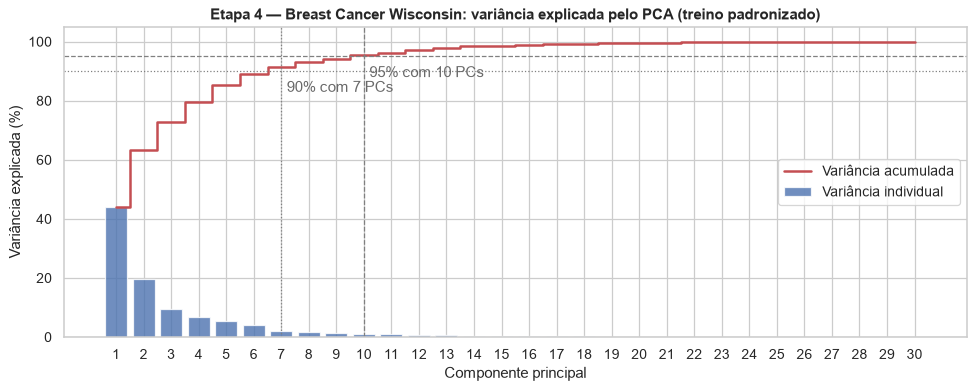

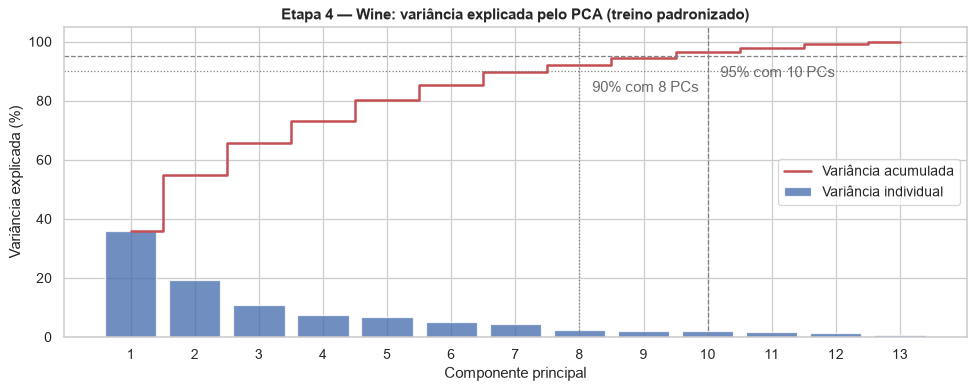

,PC1 (%),PC2 (%),PC1+PC2 (%),Componentes p/ 80%,Componentes p/ 90%,Componentes p/ 95%,Componentes p/ 99%,Dimensão original
Dataset,,,,,,,,
Breast Cancer Wisconsin,43.90,19.52,63.41,5,7,10,17,30
Wine,35.75,19.21,54.96,5,8,10,12,13


In [14]:
registros_pca = []
for nome, d in DADOS.items():
    pca_total = PCA(random_state=SEED).fit(d["X_tr_sc"])
    var = pca_total.explained_variance_ratio_
    acum = np.cumsum(var)
    d["pca_total"] = pca_total
    d["n_comp_95"] = int(np.searchsorted(acum, 0.95) + 1)
    d["pca2"] = PCA(n_components=2, random_state=SEED).fit(d["X_tr_sc"])
    d["Z_tr"] = d["pca2"].transform(d["X_tr_sc"])
    d["Z_te"] = d["pca2"].transform(d["X_te_sc"])
    registros_pca.append({"Dataset": d["titulo"], "PC1 (%)": var[0] * 100, "PC2 (%)": var[1] * 100,
                          "PC1+PC2 (%)": acum[1] * 100,
                          **{f"Componentes p/ {int(l * 100)}%": int(np.searchsorted(acum, l) + 1)
                             for l in (0.80, 0.90, 0.95, 0.99)},
                          "Dimensão original": len(var)})

    fig, ax = plt.subplots(figsize=(11, 4.5))
    idx = np.arange(1, len(var) + 1)
    ax.bar(idx, var * 100, color="#4c72b0", alpha=0.8, label="Variância individual")
    ax.step(idx, acum * 100, where="mid", color="#c44e52", lw=2, label="Variância acumulada")
    for limiar, estilo in [(0.90, ":"), (0.95, "--")]:
        k = int(np.searchsorted(acum, limiar) + 1)
        ax.axhline(limiar * 100, color="gray", ls=estilo, lw=1)
        ax.axvline(k, color="gray", ls=estilo, lw=1)
        ax.text(k + 0.2, limiar * 100 - 7, f"{int(limiar * 100)}% com {k} PCs", color="dimgray")
    ax.set_xticks(idx)
    ax.set_xlabel("Componente principal")
    ax.set_ylabel("Variância explicada (%)")
    ax.set_title(f"Etapa 4 — {d['titulo']}: variância explicada pelo PCA (treino padronizado)")
    ax.legend(loc="center right")
    plt.tight_layout()
    salvar_figura(fig, f"E4_{nome}_pca_variancia")

df_pca = pd.DataFrame(registros_pca).set_index("Dataset")
df_pca.to_csv(PASTA_METRICAS / "E4_pca_variancia.csv")
display(df_pca.round(2))

### 4.2 Projeção PCA 2D e cargas (*loadings*)

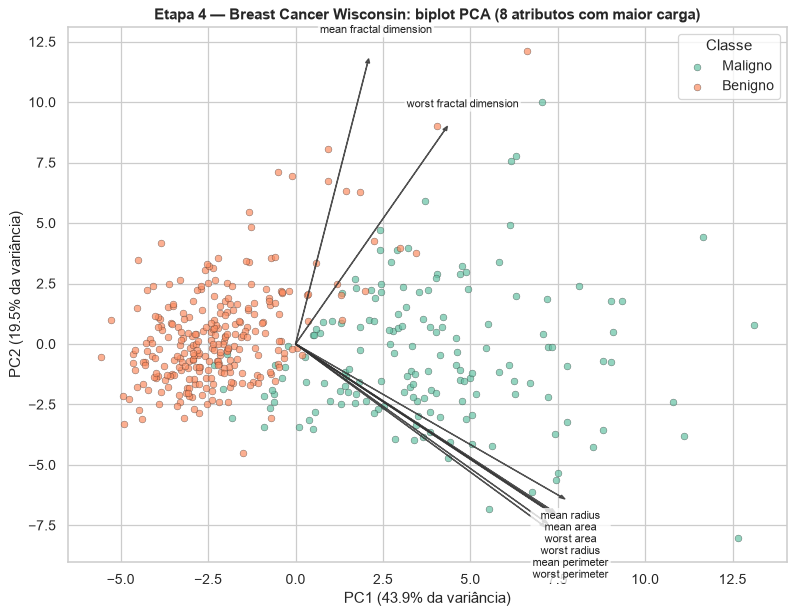

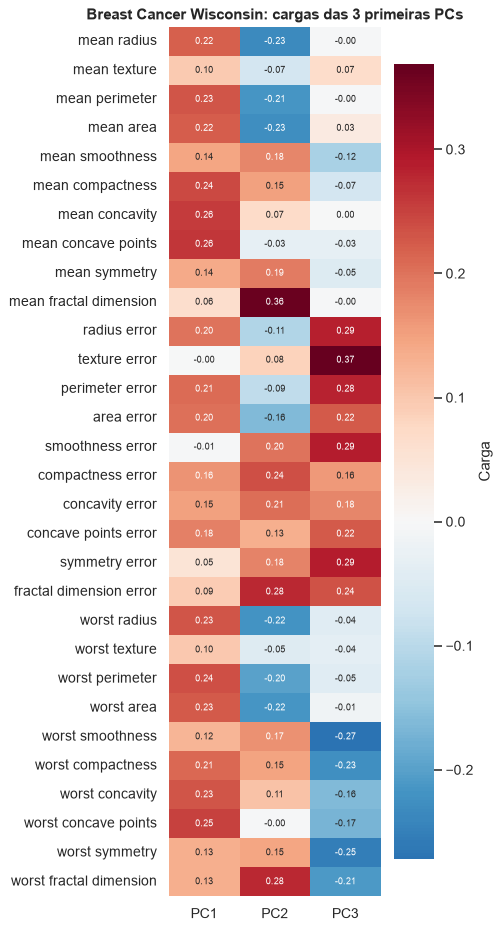

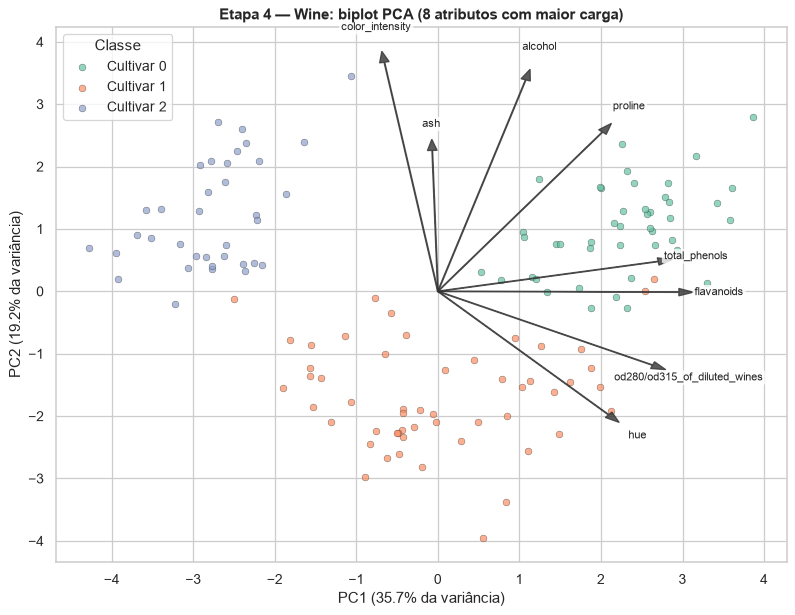

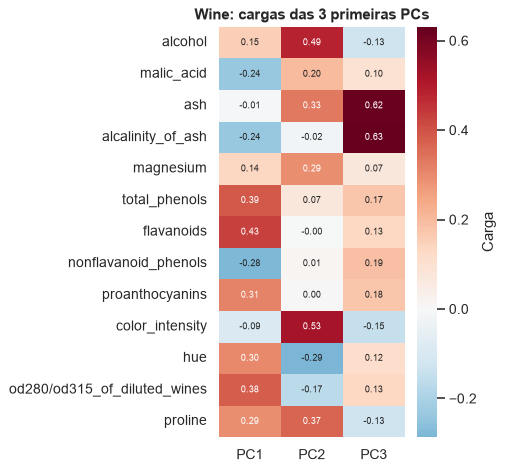

In [15]:
for nome, d in DADOS.items():
    pca2, Z, y = d["pca2"], d["Z_tr"], d["y_tr"]
    var = pca2.explained_variance_ratio_ * 100
    cargas = pd.DataFrame(pca2.components_.T, index=d["X"].columns, columns=["PC1", "PC2"])
    principais = cargas.pow(2).sum(axis=1).sort_values(ascending=False).index[:8]

    fig, ax = plt.subplots(figsize=(9, 7))
    for c, nome_c in enumerate(d["classes"]):
        m = y == c
        ax.scatter(Z[m, 0], Z[m, 1], s=30, alpha=0.7, color=PALETA_CLASSES[c], edgecolor="k", lw=0.3, label=nome_c)
    escala = np.abs(Z).max() * 0.9 / np.abs(cargas.loc[principais].values).max()
    # Setas quase colineares (diferença < 8°) compartilham um único rótulo para evitar sobreposição de texto
    grupos = []
    for atributo in sorted(principais, key=lambda a: np.arctan2(cargas.loc[a, "PC2"], cargas.loc[a, "PC1"])):
        angulo = np.degrees(np.arctan2(cargas.loc[atributo, "PC2"], cargas.loc[atributo, "PC1"]))
        if grupos and abs(angulo - grupos[-1][0]) < 8:
            grupos[-1][1].append(atributo)
        else:
            grupos.append([angulo, [atributo]])
    for _, membros in grupos:
        for atributo in membros:
            vx, vy = cargas.loc[atributo] * escala
            ax.arrow(0, 0, vx, vy, color="#333333", width=0.01, head_width=0.12, alpha=0.8,
                     length_includes_head=True)
        maior = max(membros, key=lambda a: np.hypot(cargas.loc[a, "PC1"], cargas.loc[a, "PC2"]))
        vx, vy = cargas.loc[maior] * escala
        ax.text(vx * 1.1, vy * 1.1, "\n".join(membros), fontsize=8.5, color="#222222", ha="center", va="center",
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "alpha": 0.8, "linewidth": 0})
    ax.set_xlabel(f"PC1 ({var[0]:.1f}% da variância)")
    ax.set_ylabel(f"PC2 ({var[1]:.1f}% da variância)")
    ax.set_title(f"Etapa 4 — {d['titulo']}: biplot PCA (8 atributos com maior carga)")
    ax.legend(title="Classe")
    plt.tight_layout()
    salvar_figura(fig, f"E4_{nome}_pca_biplot")

    n_pc = 3
    cargas3 = pd.DataFrame(d["pca_total"].components_[:n_pc].T, index=d["X"].columns,
                           columns=[f"PC{i + 1}" for i in range(n_pc)])
    fig, ax = plt.subplots(figsize=(5.5, 0.3 * len(cargas3) + 1.5))
    sns.heatmap(cargas3, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7.5},
                cbar_kws={"label": "Carga"}, ax=ax)
    ax.set_title(f"{d['titulo']}: cargas das 3 primeiras PCs")
    plt.tight_layout()
    salvar_figura(fig, f"E4_{nome}_pca_cargas")

### 4.3 PCA × Laplacian Eigenmaps

Como na Aula 6, comparamos o PCA com os Laplacian Eigenmaps para diferentes tamanhos de vizinhança (`n_neighbors` = 5, 15, 50). Os Laplacian Eigenmaps preservam a vizinhança local (estrutura de grafo), que é a mesma hipótese usada pelos métodos semi-supervisionados baseados em grafo (Label Propagation e Label Spreading).

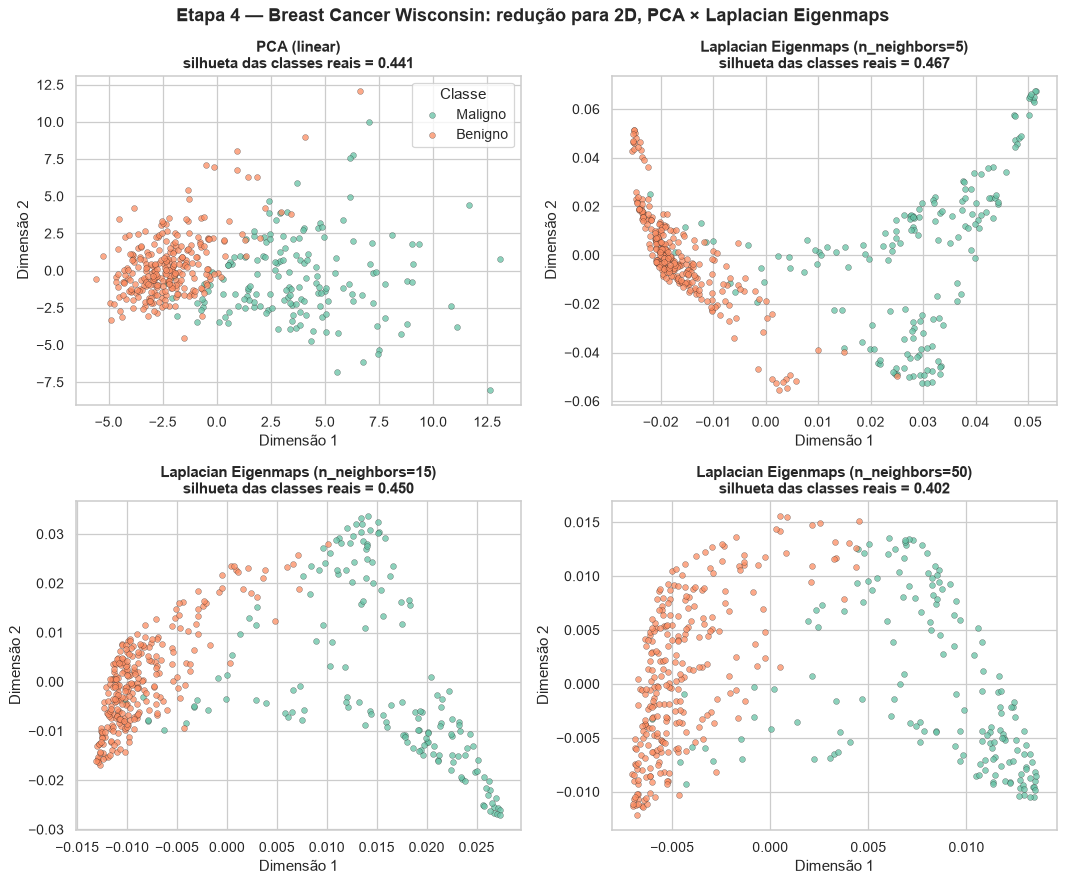

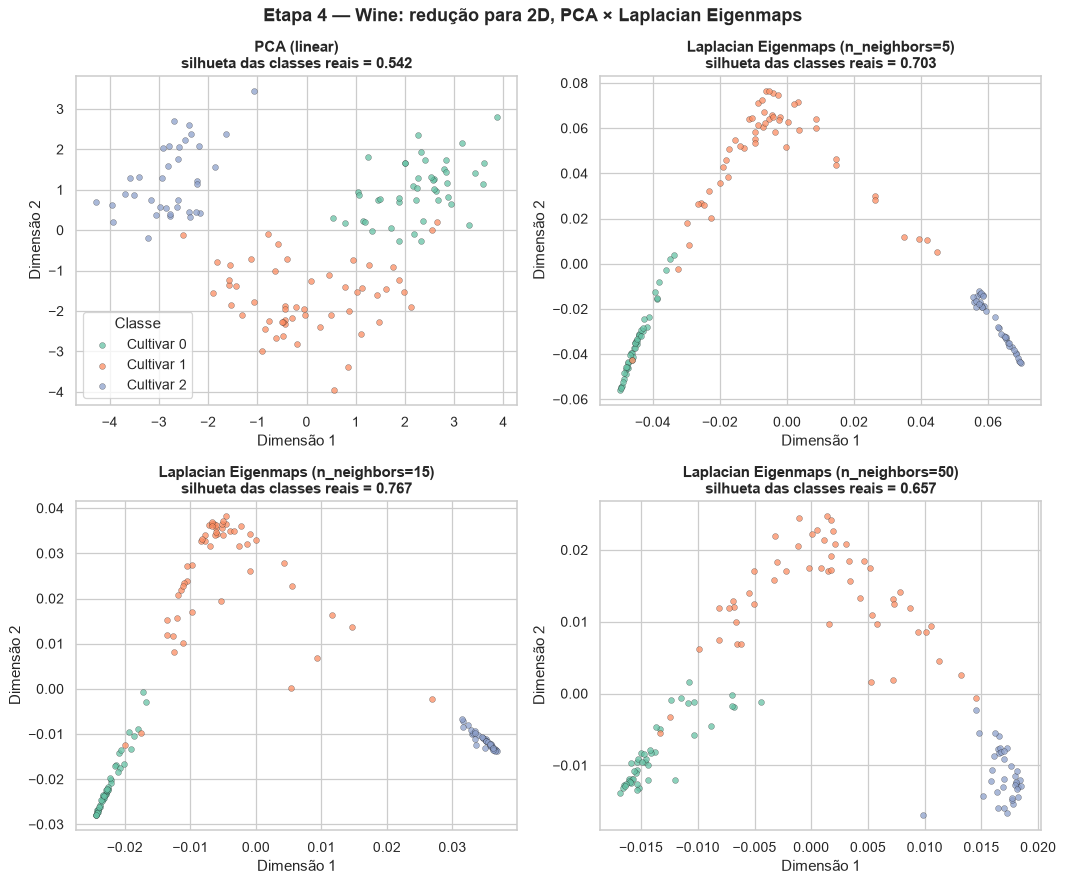

In [16]:
VIZINHOS_LE = [5, 15, 50]
for nome, d in DADOS.items():
    X, y = d["X_tr_sc"], d["y_tr"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.ravel()
    projecoes = [("PCA (linear)", d["Z_tr"])]
    for k in VIZINHOS_LE:
        Z_le = SpectralEmbedding(n_components=2, affinity="nearest_neighbors", n_neighbors=k,
                                 random_state=SEED).fit_transform(X)
        projecoes.append((f"Laplacian Eigenmaps (n_neighbors={k})", Z_le))
        if k == 15:
            d["Z_le15"] = Z_le
    for ax, (titulo, Z) in zip(axes, projecoes):
        for c, nome_c in enumerate(d["classes"]):
            m = y == c
            ax.scatter(Z[m, 0], Z[m, 1], s=22, alpha=0.75, color=PALETA_CLASSES[c], edgecolor="k", lw=0.25,
                       label=nome_c)
        sil = silhouette_score(Z, y)
        ax.set_title(f"{titulo}\nsilhueta das classes reais = {sil:.3f}")
        ax.set_xlabel("Dimensão 1")
        ax.set_ylabel("Dimensão 2")
    axes[0].legend(title="Classe")
    fig.suptitle(f"Etapa 4 — {d['titulo']}: redução para 2D, PCA × Laplacian Eigenmaps")
    plt.tight_layout()
    salvar_figura(fig, f"E4_{nome}_pca_vs_laplacian")

### 4.4 Quanto da separabilidade cada representação preserva?

Duas medidas para cada representação do treino:

- **Silhueta das classes reais**: quão compactas e separadas as classes estão naquele espaço (de −1 a 1).
- **F1-macro de um KNN (k = 5)** em validação cruzada estratificada de 5 *folds*.

As projeções não usam rótulos, então não há vazamento de rótulos nessa comparação.

,Dataset,Representação,Dimensões,Silhueta (classes reais),F1 KNN (CV),F1 KNN (CV) dp
0,Breast Cancer Wisconsin,Padronizado completo,30,0.2984,0.9617,0.0145
1,Breast Cancer Wisconsin,PCA 95% da variância,10,0.3108,0.9567,0.0174
2,Breast Cancer Wisconsin,PCA 2D,2,0.4412,0.9319,0.0125
3,Breast Cancer Wisconsin,Laplacian Eigenmaps 2D (k=15),2,0.4500,0.9490,0.0220
4,Wine,Padronizado completo,13,0.2808,0.9634,0.0321
5,Wine,PCA 95% da variância,10,0.2942,0.9634,0.0321
6,Wine,PCA 2D,2,0.5424,0.9784,0.0291
7,Wine,Laplacian Eigenmaps 2D (k=15),2,0.7667,0.9784,0.0291


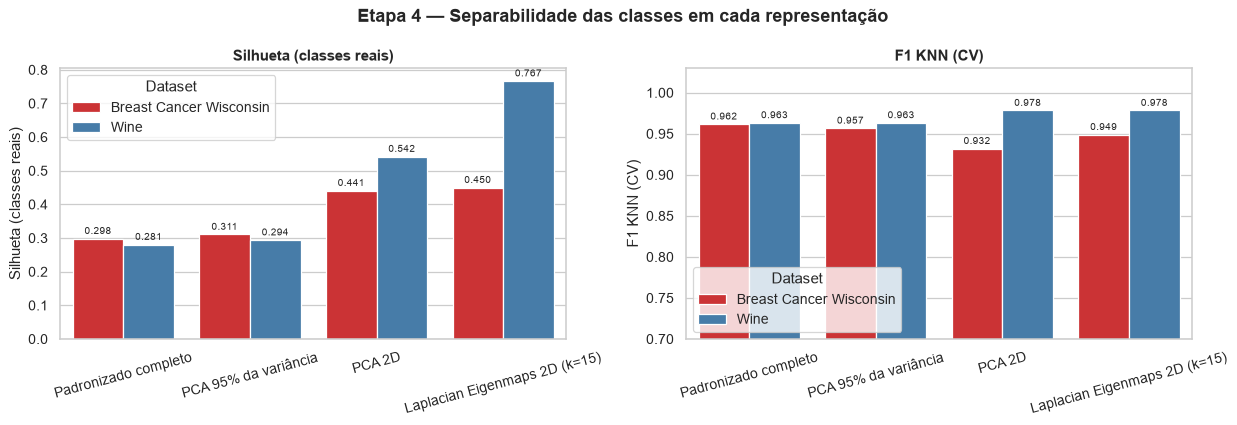

In [17]:
registros_rep = []
for nome, d in DADOS.items():
    X, y = d["X_tr_sc"], d["y_tr"]
    representacoes = {
        f"Padronizado completo": X,
        f"PCA 95% da variância": PCA(n_components=d["n_comp_95"], random_state=SEED).fit_transform(X),
        "PCA 2D": d["Z_tr"],
        "Laplacian Eigenmaps 2D (k=15)": d["Z_le15"],
    }
    for nome_rep, Z in representacoes.items():
        f1_cv = cross_val_score(KNeighborsClassifier(n_neighbors=5), Z, y, cv=cv5, scoring="f1_macro")
        registros_rep.append({"Dataset": d["titulo"], "Representação": nome_rep, "Dimensões": Z.shape[1],
                              "Silhueta (classes reais)": silhouette_score(Z, y),
                              "F1 KNN (CV)": f1_cv.mean(), "F1 KNN (CV) dp": f1_cv.std()})
df_rep = pd.DataFrame(registros_rep)
df_rep.to_csv(PASTA_METRICAS / "E4_separabilidade_representacoes.csv", index=False)
display(df_rep.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, metrica in zip(axes, ["Silhueta (classes reais)", "F1 KNN (CV)"]):
    sns.barplot(data=df_rep, x="Representação", y=metrica, hue="Dataset", palette="Set1", ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=8, padding=2)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
    ax.set_title(metrica)
axes[1].set_ylim(0.7, 1.03)
fig.suptitle("Etapa 4 — Separabilidade das classes em cada representação")
plt.tight_layout()
salvar_figura(fig, "E4_separabilidade_representacoes")

**Interpretação da Etapa 4.**

- **Redundância no Breast Cancer.** 21 pares de atributos têm |r| > 0,9. Raio, perímetro e área são praticamente a mesma informação (r ≈ 0,99), e por isso a PC1 sozinha concentra 43,9% da variância. No biplot, a PC1 aponta na direção dos atributos de **tamanho** (raio, perímetro, área), e os tumores malignos ocupam a região de PC1 alto. A PC2 é dominada pela dimensão fractal, quase ortogonal ao diagnóstico. No Wine não há nenhum par com |r| > 0,9, e a variância é mais distribuída (PC1 + PC2 = 55,0%).
- **Duas dimensões bastam para enxergar as classes.** No Wine, o KNN no PCA 2D (F1 = 0,978) é até melhor que no espaço completo (0,963): as dimensões descartadas carregam mais ruído do que sinal. No Breast Cancer a perda é pequena (0,962 → 0,932). A silhueta das classes reais **aumenta** nas projeções 2D (Wine: 0,281 → 0,542 no PCA e 0,767 nos Laplacian Eigenmaps). Isso mostra que, no espaço completo, as distâncias são "diluídas" por atributos pouco discriminativos, efeito que prejudica os métodos baseados em densidade (Seção 5.1).
- **Laplacian Eigenmaps** separam as três cultivares em grupos muito compactos. É um indício de que a *hipótese de cluster* (pontos próximos no grafo de vizinhança compartilham a classe), base dos métodos semi-supervisionados de grafo, vale bem para o Wine.

**Decisão (a mesma dos scripts):** os classificadores e os agrupamentos trabalham no **espaço padronizado completo**, sem perda de informação. As projeções 2D são usadas apenas para visualização.

## 5. Mineração de dados (Etapa 5)

A mineração segue **exatamente o protocolo dos scripts** `kdd_breast_cancer_wisconsin.py` e `kdd_wine.py`, cujos resultados (pastas `results_breast_cancer/` e `results_wine/`) alimentam a apresentação. Os dois scripts têm protocolos diferentes entre si, e o notebook reproduz cada um no seu dataset:

| Item | Breast Cancer (`kdd_breast_cancer_wisconsin.py`) | Wine (`kdd_wine.py`) |
|---|---|---|
| Taxas de rótulos | 0,05; 0,10; 0,20; 0,30; 0,40; 0,50; 0,60; 0,70 | 0,05; 0,10; 0,20; 0,30; 0,50; 0,70 |
| Repetições | 5 (sementes 10, 20, 30, 40, 50) | 10 (geradores com sementes 100 a 109) |
| Sorteio dos rotulados | `train_test_split` estratificado | `mascarar_rotulos_estratificado` (mínimo de 2 por classe), importada do próprio script |
| *Baselines* | KNN (k = 5); Regressão Logística | KNN (k = mín(5, nº rotulados ÷ 2)); Regressão Logística |
| Semi-supervisionados | Label Spreading (grafo kNN, k = 7); Self-Training com RL (limiar 0,75) | Label Spreading e Label Propagation (kernel RBF, γ = 1/13); Self-Training com RL (limiar 0,80) |
| K-Médias | k = 2, `n_init` = 10 | k = 3, `n_init` = 20 |
| DBSCAN | eps = 4,5; min_samples = 5 | eps = 2,3; min_samples = 4 |

Além de reproduzir os scripts, o notebook acrescenta análises complementares (escolha de k, gráficos de k-distâncias, grades de hiperparâmetros, sensibilidade, testes estatísticos e análise de erros). **Os números principais são conferidos automaticamente contra os CSVs gerados pelos scripts.**

In [18]:
PROTOCOLO = {
    "breast_cancer": {
        "script": "kdd_breast_cancer_wisconsin.py",
        "taxas": [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70],
        "repeticoes": 5,
        "sementes": [10, 20, 30, 40, 50],
        "kmeans_n_init": 10,
        "dbscan_eps": 4.5,
        "dbscan_min_samples": 5,
        "modelos": ["Label Spreading (Semi)", "Self-Training LR (Semi)", "KNN (Baseline)",
                    "Regressão Logística (Baseline)"],
        "csv_semi": "results_breast_cancer/metrics/Breast_Cancer_semi_supervisionado.csv",
        "csv_cluster": "results_breast_cancer/metrics/Breast_Cancer_clustering.csv",
    },
    "wine": {
        "script": "kdd_wine.py",
        "taxas": [0.05, 0.10, 0.20, 0.30, 0.50, 0.70],
        "repeticoes": 10,
        "sementes": [100 + rep for rep in range(10)],
        "kmeans_n_init": 20,
        "dbscan_eps": 2.3,
        "dbscan_min_samples": 4,
        "modelos": ["KNN (Baseline)", "Reg. Logistica (Baseline)", "Label Spreading", "Label Propagation",
                    "Self-Training (LogReg)"],
        "csv_semi": "results_wine/metrics/Wine_semi_supervisionado.csv",
        "csv_cluster": "results_wine/metrics/Wine_clustering.csv",
    },
}
BASELINES = {n: [m for m in p["modelos"] if "Baseline" in m] for n, p in PROTOCOLO.items()}
SEMI = {n: [m for m in p["modelos"] if "Baseline" not in m] for n, p in PROTOCOLO.items()}

# Cores por família de método (os nomes seguem os scripts de cada dataset)
ESTILO = {
    "KNN (Baseline)": dict(color="#dd8452", ls="--", marker="o"),
    "Regressão Logística (Baseline)": dict(color="#c44e52", ls="--", marker="s"),
    "Reg. Logistica (Baseline)": dict(color="#c44e52", ls="--", marker="s"),
    "Label Spreading (Semi)": dict(color="#55a868", ls="-", marker="D"),
    "Label Spreading": dict(color="#55a868", ls="-", marker="D"),
    "Label Propagation": dict(color="#4c72b0", ls="-", marker="^"),
    "Self-Training LR (Semi)": dict(color="#8172b2", ls="-", marker="P"),
    "Self-Training (LogReg)": dict(color="#8172b2", ls="-", marker="P"),
}
display(pd.DataFrame({d["titulo"]: {"Taxas": ", ".join(f"{t:.0%}" for t in PROTOCOLO[n]["taxas"]),
                                    "Repetições": PROTOCOLO[n]["repeticoes"],
                                    "Modelos": ", ".join(PROTOCOLO[n]["modelos"])}
                      for n, d in DADOS.items()}))

,Breast Cancer Wisconsin,Wine
Taxas,"5%, 10%, 20%, 30%, 40%, 50%, 60%, 70%","5%, 10%, 20%, 30%, 50%, 70%"
Repetições,5,10
Modelos,"Label Spreading (Semi), Self-Training LR (Semi...","KNN (Baseline), Reg. Logistica (Baseline), Lab..."


### 5.1 Agrupamento: o caso-limite com 0% de rótulos

O agrupamento é aplicado ao **treino padronizado, sem nenhum rótulo**. Os rótulos verdadeiros são usados **somente para avaliar** os agrupamentos, por meio de métricas externas:

- **ARI** (*Adjusted Rand Index*) e **AMI/NMI** (informação mútua ajustada e normalizada): concordância entre a partição e as classes (0 ≈ aleatório, 1 = perfeito).
- **Homogeneidade, completude e V-measure**.
- **Silhueta**: métrica interna, sem rótulos. No DBSCAN, é calculada sem os pontos de ruído.

#### 5.1.1 K-Médias: escolha de k (cotovelo e silhueta, como em `find_k.py` da Aula 7)

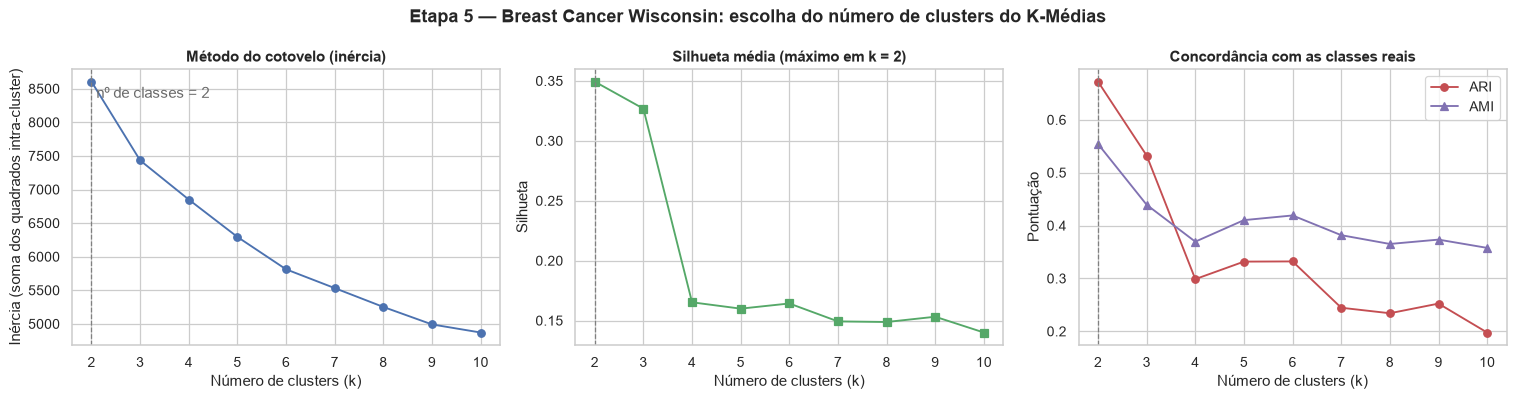

k,2,3,4,5,6,7,8,9,10
Inércia,8605.2369,7433.2620,6850.2968,6294.3242,5812.3513,5532.7218,5252.1873,4992.2849,4871.5379
Silhueta,0.3494,0.3268,0.1653,0.1600,0.1643,0.1493,0.1488,0.1532,0.1400
ARI,0.6721,0.5324,0.2987,0.3318,0.3322,0.2446,0.2342,0.2524,0.1978
AMI,0.5542,0.4393,0.3695,0.4103,0.4191,0.3818,0.3652,0.3734,0.3578


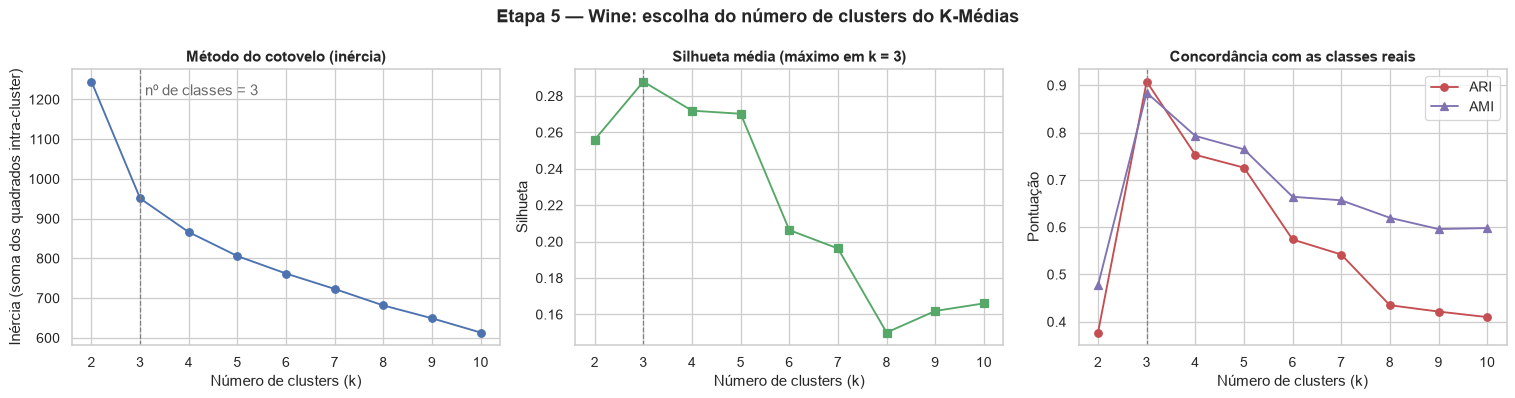

k,2,3,4,5,6,7,8,9,10
Inércia,1244.9077,951.0871,866.1475,805.9938,762.0478,723.2293,681.7465,649.4147,613.5822
Silhueta,0.2560,0.2879,0.2719,0.2702,0.2064,0.1962,0.1501,0.1619,0.1661
ARI,0.3772,0.9079,0.7531,0.7260,0.5740,0.5422,0.4349,0.4215,0.4098
AMI,0.4771,0.8845,0.7931,0.7646,0.6644,0.6569,0.6199,0.5960,0.5981


In [19]:
def varrer_kmeans(X, y, n_init, ks=range(2, 11)):
    registros = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=n_init, random_state=SEED).fit(X)
        registros.append({"k": k, "Inércia": km.inertia_, "Silhueta": silhouette_score(X, km.labels_),
                          "ARI": adjusted_rand_score(y, km.labels_), "AMI": adjusted_mutual_info_score(y, km.labels_)})
    return pd.DataFrame(registros)


for nome, d in DADOS.items():
    C = len(d["classes"])
    df_k = varrer_kmeans(d["X_tr_sc"], d["y_tr"], PROTOCOLO[nome]["kmeans_n_init"])
    df_k.to_csv(PASTA_METRICAS / f"E5_{nome}_kmeans_varredura_k.csv", index=False)
    d["k_silhueta"] = int(df_k.loc[df_k["Silhueta"].idxmax(), "k"])

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    axes[0].plot(df_k["k"], df_k["Inércia"], "o-", color="#4c72b0")
    axes[0].set_title("Método do cotovelo (inércia)")
    axes[0].set_ylabel("Inércia (soma dos quadrados intra-cluster)")
    axes[1].plot(df_k["k"], df_k["Silhueta"], "s-", color="#55a868")
    axes[1].set_title(f"Silhueta média (máximo em k = {d['k_silhueta']})")
    axes[1].set_ylabel("Silhueta")
    axes[2].plot(df_k["k"], df_k["ARI"], "o-", label="ARI", color="#c44e52")
    axes[2].plot(df_k["k"], df_k["AMI"], "^-", label="AMI", color="#8172b2")
    axes[2].set_title("Concordância com as classes reais")
    axes[2].set_ylabel("Pontuação")
    axes[2].legend()
    for ax in axes:
        ax.axvline(C, color="gray", ls="--", lw=1)
        ax.set_xlabel("Número de clusters (k)")
        ax.set_xticks(df_k["k"])
    axes[0].text(C + 0.1, axes[0].get_ylim()[1] * 0.97, f"nº de classes = {C}", color="dimgray", va="top")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: escolha do número de clusters do K-Médias")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_kmeans_escolha_k")
    display(df_k.round(4).set_index("k").T)

#### 5.1.2 K-Médias e DBSCAN com os parâmetros dos scripts

In [20]:
for nome, d in DADOS.items():
    p, C = PROTOCOLO[nome], len(d["classes"])
    d["kmeans"] = KMeans(n_clusters=C, n_init=p["kmeans_n_init"], random_state=SEED).fit(d["X_tr_sc"])
    d["dbscan_rotulos"] = DBSCAN(eps=p["dbscan_eps"], min_samples=p["dbscan_min_samples"]).fit_predict(d["X_tr_sc"])


def avaliar_particao(X, y, rotulos):
    validos = rotulos != -1
    n_clusters = len(set(rotulos[validos]))
    silhueta = np.nan
    if n_clusters >= 2 and validos.sum() > n_clusters:
        silhueta = silhouette_score(X[validos], rotulos[validos])
    return {"Clusters": n_clusters, "Ruído (%)": 100 * np.mean(~validos),
            "ARI": adjusted_rand_score(y, rotulos), "AMI": adjusted_mutual_info_score(y, rotulos),
            "NMI": normalized_mutual_info_score(y, rotulos), "Homogeneidade": homogeneity_score(y, rotulos),
            "Completude": completeness_score(y, rotulos), "V-measure": v_measure_score(y, rotulos),
            "Silhueta (sem ruído)": silhueta}


registros_cluster = []
for nome, d in DADOS.items():
    p, C = PROTOCOLO[nome], len(d["classes"])
    for algoritmo, rot in [(f"K-Médias (k = {C})", d["kmeans"].labels_),
                           (f"DBSCAN (eps = {p['dbscan_eps']}, min_samples = {p['dbscan_min_samples']})",
                            d["dbscan_rotulos"])]:
        registros_cluster.append({"Dataset": d["titulo"], "Algoritmo": algoritmo,
                                  **avaliar_particao(d["X_tr_sc"], d["y_tr"], rot)})
df_cluster = pd.DataFrame(registros_cluster)
df_cluster.to_csv(PASTA_METRICAS / "E5_agrupamento_metricas.csv", index=False)
display(df_cluster.round(4).set_index(["Dataset", "Algoritmo"]))

# Conferência com os CSVs gerados pelos scripts (ARI e NMI)
conferencia = []
for nome, d in DADOS.items():
    csv = pd.read_csv(PROTOCOLO[nome]["csv_cluster"])
    nb = df_cluster[df_cluster["Dataset"] == d["titulo"]].reset_index(drop=True)
    for i in range(2):
        for metrica in ["ARI", "NMI"]:
            conferencia.append({"Dataset": d["titulo"], "Algoritmo": nb.loc[i, "Algoritmo"], "Métrica": metrica,
                                "Notebook": nb.loc[i, metrica], "Script (CSV)": csv.loc[i, metrica],
                                "Confere": bool(np.isclose(nb.loc[i, metrica], csv.loc[i, metrica], atol=1e-4))})
conferencia = pd.DataFrame(conferencia)
display(conferencia.round(4))
assert conferencia["Confere"].all(), "o agrupamento do notebook diverge do script"
print("Agrupamento idêntico ao dos scripts.")

Clusters  \
Dataset                 Algoritmo                                       
Breast Cancer Wisconsin K-Médias (k = 2)                            2   
                        DBSCAN (eps = 4.5, min_samples = 5)         1   
Wine                    K-Médias (k = 3)                            3   
                        DBSCAN (eps = 2.3, min_samples = 4)         4   

                                                             Ruído (%)  \
Dataset                 Algoritmo                                        
Breast Cancer Wisconsin K-Médias (k = 2)                        0.0000   
                        DBSCAN (eps = 4.5, min_samples = 5)     6.1033   
Wine                    K-Médias (k = 3)                        0.0000   
                        DBSCAN (eps = 2.3, min_samples = 4)    22.5564   

                                                                ARI     AMI  \
Dataset                 Algoritmo                                             
Breast Cancer Wisconsin K-Médias (k = 2)                     0.6721  0.5542   
                        DBSCAN (eps = 4.5, min_samples = 5)  0.0254  0.0098   
Wine                    K-Médias (k = 3)                     0.9079  0.8845   
                        DBSCAN (eps = 2.3, min_samples = 4)  0.6022  0.6513   

                                                                NMI  \
Dataset                 Algoritmo                                     
Breast Cancer Wisconsin K-Médias (k = 2)                     0.5551   
                        DBSCAN (eps = 4.5, min_samples = 5)  0.0124   
Wine                    K-Médias (k = 3)                     0.8861   
                        DBSCAN (eps = 2.3, min_samples = 4)  0.6602   

                                                             Homogeneidade  \
Dataset                 Algoritmo                                            
Breast Cancer Wisconsin K-Médias (k = 2)                            0.5456   
                        DBSCAN (eps = 4.5, min_samples = 5)         0.0084   
Wine                    K-Médias (k = 3)                            0.8888   
                        DBSCAN (eps = 2.3, min_samples = 4)         0.7776   

                                                             Completude  \
Dataset                 Algoritmo                                         
Breast Cancer Wisconsin K-Médias (k = 2)                         0.5649   
                        DBSCAN (eps = 4.5, min_samples = 5)      0.0241   
Wine                    K-Médias (k = 3)                         0.8834   
                        DBSCAN (eps = 2.3, min_samples = 4)      0.5736   

                                                             V-measure  \
Dataset                 Algoritmo                                        
Breast Cancer Wisconsin K-Médias (k = 2)                        0.5551   
                        DBSCAN (eps = 4.5, min_samples = 5)     0.0124   
Wine                    K-Médias (k = 3)                        0.8861   
                        DBSCAN (eps = 2.3, min_samples = 4)     0.6602   

                                                             Silhueta (sem ruído)  
Dataset                 Algoritmo                                                  
Breast Cancer Wisconsin K-Médias (k = 2)                                   0.3494  
                        DBSCAN (eps = 4.5, min_samples = 5)                   NaN  
Wine                    K-Médias (k = 3)                                   0.2879  
                        DBSCAN (eps = 2.3, min_samples = 4)                0.2534

,Dataset,Algoritmo,Métrica,Notebook,Script (CSV),Confere
0,Breast Cancer Wisconsin,K-Médias (k = 2),ARI,0.6721,0.6721,True
1,Breast Cancer Wisconsin,K-Médias (k = 2),NMI,0.5551,0.5551,True
2,Breast Cancer Wisconsin,"DBSCAN (eps = 4.5, min_samples = 5)",ARI,0.0254,0.0254,True
3,Breast Cancer Wisconsin,"DBSCAN (eps = 4.5, min_samples = 5)",NMI,0.0124,0.0124,True
4,Wine,K-Médias (k = 3),ARI,0.9079,0.9079,True
5,Wine,K-Médias (k = 3),NMI,0.8861,0.8861,True
6,Wine,"DBSCAN (eps = 2.3, min_samples = 4)",ARI,0.6022,0.6022,True
7,Wine,"DBSCAN (eps = 2.3, min_samples = 4)",NMI,0.6602,0.6602,True


Agrupamento idêntico ao dos scripts.


#### 5.1.3 Diagrama de silhueta: clusters do K-Médias × classes reais

O diagrama da esquerda mostra a silhueta de cada ponto no agrupamento do K-Médias. O da direita calcula a silhueta usando as **classes reais** como se fossem clusters: ele indica o quão "agrupáveis" são as classes verdadeiras no espaço padronizado.

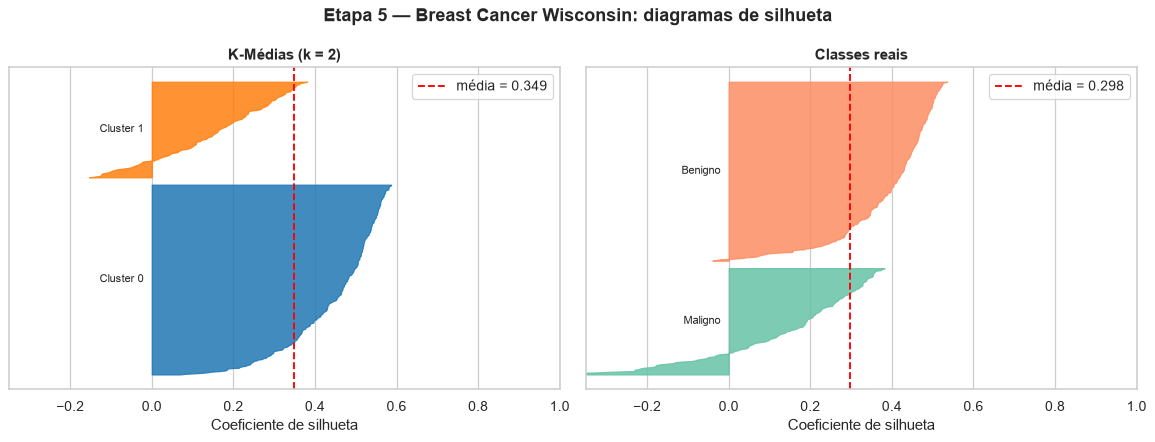

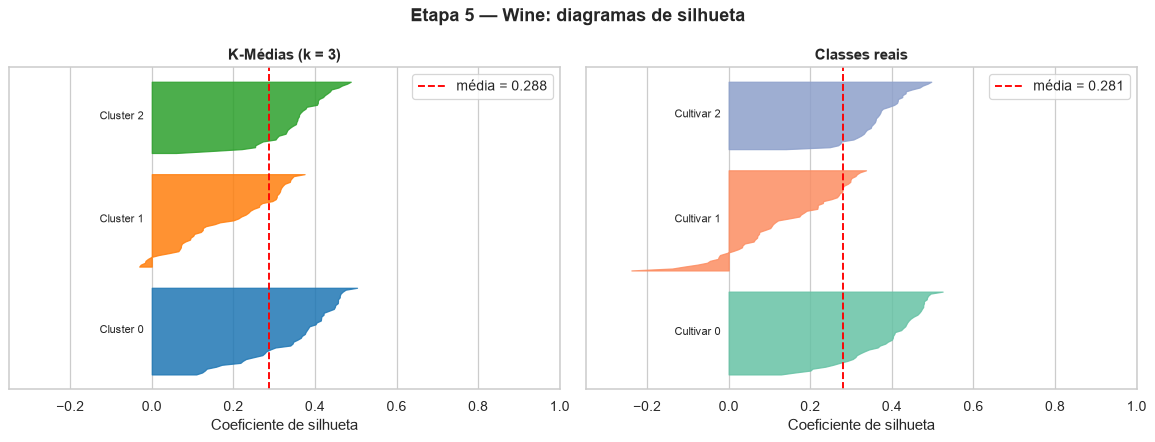

In [21]:
def diagrama_silhueta(ax, X, rotulos, nomes, cores, titulo):
    valores = silhouette_samples(X, rotulos)
    base = 10
    for i, c in enumerate(np.unique(rotulos)):
        v = np.sort(valores[rotulos == c])
        ax.fill_betweenx(np.arange(base, base + len(v)), 0, v, color=cores[i], alpha=0.85)
        ax.text(-0.02, base + len(v) / 2, nomes[i], ha="right", va="center", fontsize=9)
        base += len(v) + 10
    ax.axvline(valores.mean(), color="red", ls="--", label=f"média = {valores.mean():.3f}")
    ax.set_xlabel("Coeficiente de silhueta")
    ax.set_yticks([])
    ax.set_xlim(-0.35, 1)
    ax.set_title(titulo)
    ax.legend(loc="upper right")


for nome, d in DADOS.items():
    C = len(d["classes"])
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    diagrama_silhueta(axes[0], d["X_tr_sc"], d["kmeans"].labels_, [f"Cluster {c}" for c in range(C)],
                      sns.color_palette("tab10", C), f"K-Médias (k = {C})")
    diagrama_silhueta(axes[1], d["X_tr_sc"], d["y_tr"], d["classes"], PALETA_CLASSES, "Classes reais")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: diagramas de silhueta")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_silhueta")

#### 5.1.4 DBSCAN: o `eps` dos scripts no contexto (k-distâncias e grade de hiperparâmetros)

Os scripts fixam `eps` e `min_samples`. Para entender essa escolha, seguimos o procedimento da Aula 7 (`dbscan_eps.py`):

1. O **gráfico de k-distâncias** mostra a distância de cada ponto ao seu `min_samples`-ésimo vizinho, em ordem crescente. O "joelho" da curva é a heurística clássica para `eps`.
2. Uma **varredura em grade** de `eps` × `min_samples` registra número de clusters, % de ruído, ARI e silhueta.

A linha tracejada marca o `eps` usado no script.

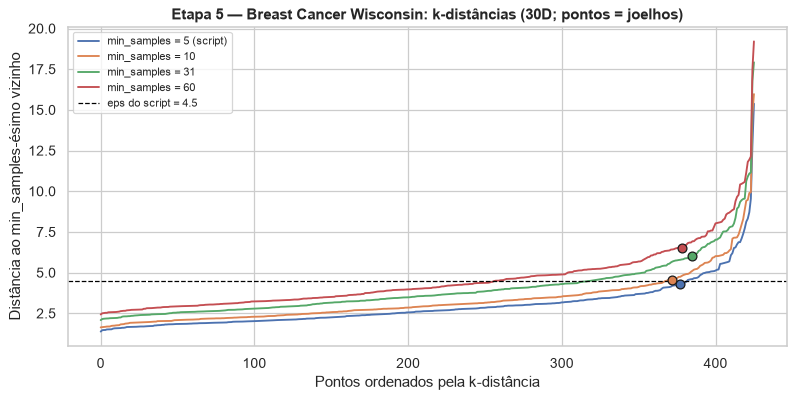

Breast Cancer Wisconsin: joelho da curva com min_samples = 5: eps ≈ 4.29 | eps do script = 4.5


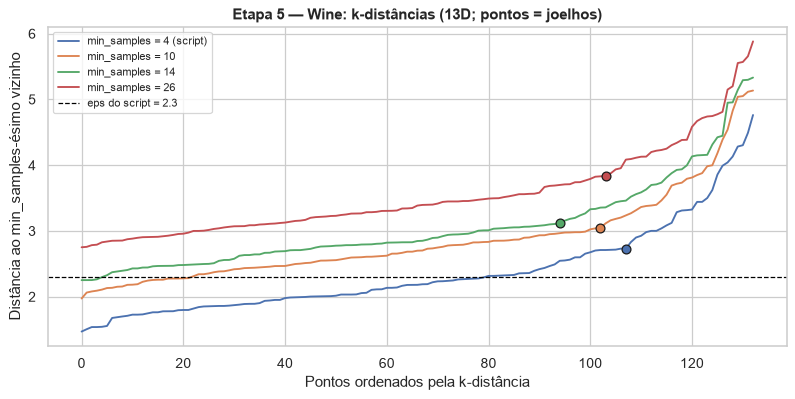

Wine: joelho da curva com min_samples = 4: eps ≈ 2.73 | eps do script = 2.3


In [22]:
def k_distancias(X, min_samples):
    # kneighbors(X) inclui o próprio ponto (distância 0), assim como a definição de min_samples do DBSCAN
    distancias, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
    return np.sort(distancias[:, -1])


def joelho(curva):
    """Ponto de maior distância à reta que liga os extremos da curva normalizada em [0, 1] x [0, 1]."""
    x = np.linspace(0, 1, len(curva))
    yn = (curva - curva.min()) / (curva.max() - curva.min())
    return float(curva[np.argmax(np.abs(yn - x))])


for nome, d in DADOS.items():
    X, p = d["X_tr_sc"], PROTOCOLO[nome]
    dim = X.shape[1]
    lista_ms = sorted({p["dbscan_min_samples"], 10, dim + 1, 2 * dim})
    kd_min, kd_max = k_distancias(X, min(lista_ms)), k_distancias(X, max(lista_ms))
    grade_eps = np.round(np.linspace(np.percentile(kd_min, 5), np.percentile(kd_max, 99), 40), 3)
    registros = []
    for ms in lista_ms:
        for eps in grade_eps:
            r = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
            a = avaliar_particao(X, d["y_tr"], r)
            registros.append({"min_samples": ms, "eps": eps, **{k: a[k] for k in
                              ["Clusters", "Ruído (%)", "ARI", "AMI", "Silhueta (sem ruído)"]}})
    d["dbscan_grade"] = pd.DataFrame(registros)
    d["dbscan_grade"].to_csv(PASTA_METRICAS / f"E5_{nome}_dbscan_grade.csv", index=False)

    fig, ax = plt.subplots(figsize=(9, 4.6))
    for ms in lista_ms:
        kd = k_distancias(X, ms)
        linha, = ax.plot(kd, label=f"min_samples = {ms}" + (" (script)" if ms == p["dbscan_min_samples"] else ""))
        e = joelho(kd)
        ax.scatter(np.searchsorted(kd, e), e, color=linha.get_color(), s=50, zorder=5, edgecolor="k")
    ax.axhline(p["dbscan_eps"], color="black", ls="--", lw=1, label=f"eps do script = {p['dbscan_eps']}")
    ax.set_xlabel("Pontos ordenados pela k-distância")
    ax.set_ylabel("Distância ao min_samples-ésimo vizinho")
    ax.legend(fontsize=8.5)
    ax.set_title(f"Etapa 5 — {d['titulo']}: k-distâncias ({dim}D; pontos = joelhos)")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_dbscan_k_distancias")
    print(f"{d['titulo']}: joelho da curva com min_samples = {p['dbscan_min_samples']}: "
          f"eps ≈ {joelho(k_distancias(X, p['dbscan_min_samples'])):.2f} | eps do script = {p['dbscan_eps']}")

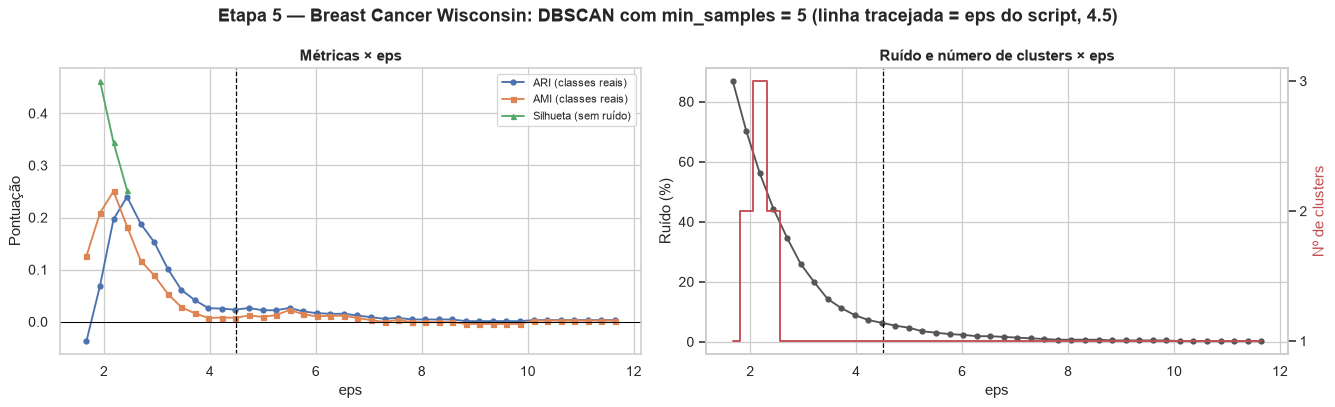

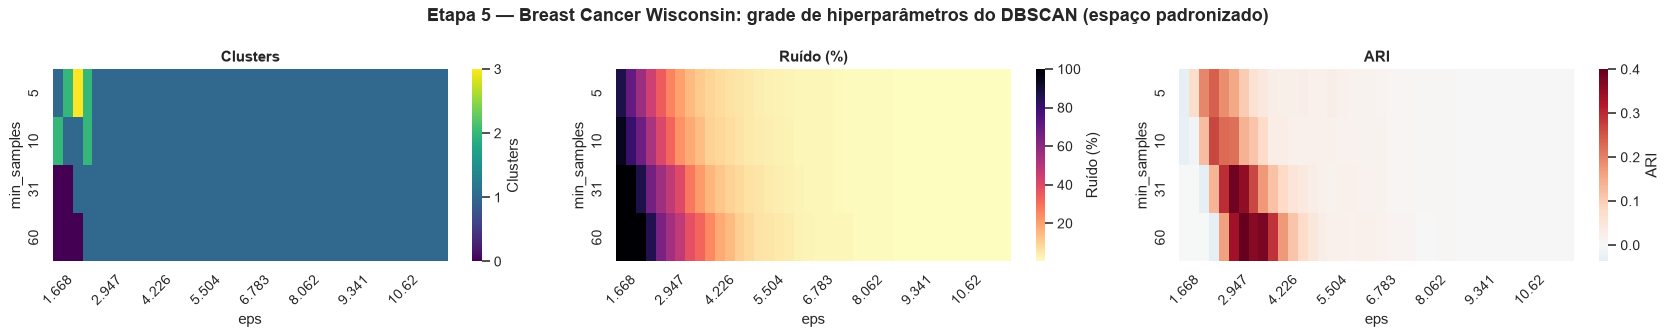

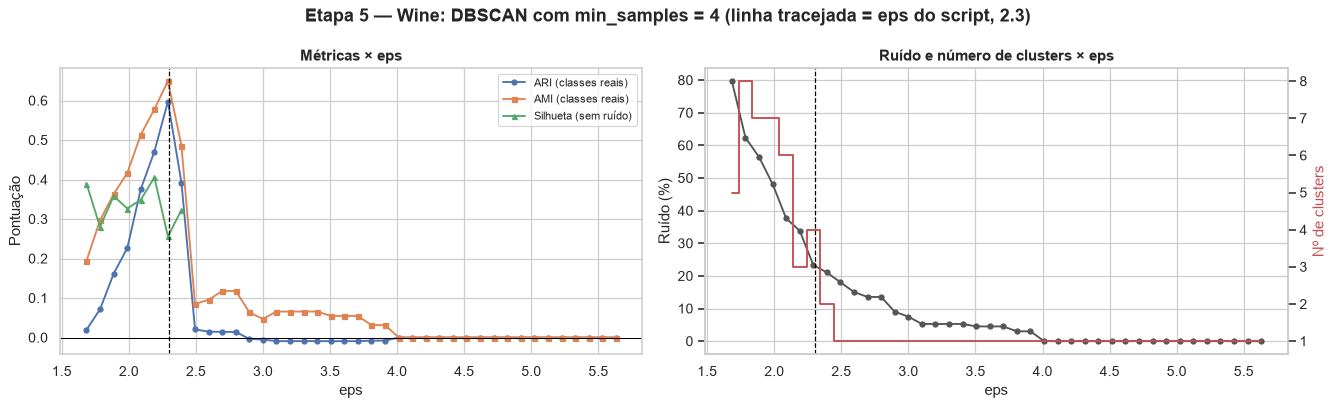

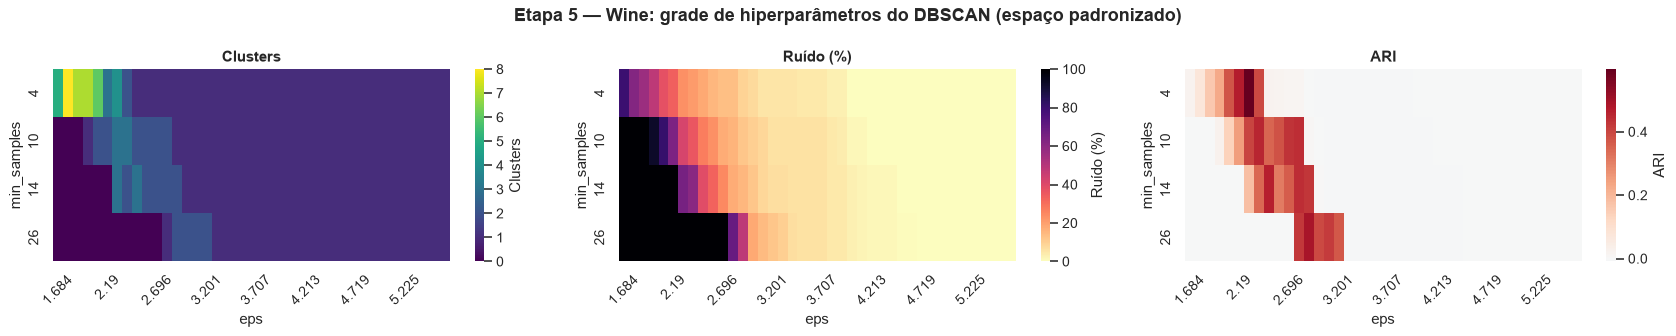

In [23]:
for nome, d in DADOS.items():
    p, grade = PROTOCOLO[nome], d["dbscan_grade"]
    sub = grade[grade["min_samples"] == p["dbscan_min_samples"]]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
    axes[0].plot(sub["eps"], sub["ARI"], "o-", ms=4, label="ARI (classes reais)")
    axes[0].plot(sub["eps"], sub["AMI"], "s-", ms=4, label="AMI (classes reais)")
    axes[0].plot(sub["eps"], sub["Silhueta (sem ruído)"], "^-", ms=4, label="Silhueta (sem ruído)")
    axes[0].axhline(0, color="black", lw=0.8)
    axes[0].set_ylabel("Pontuação")
    axes[0].set_title("Métricas × eps")
    axes[0].legend(fontsize=9)
    axes[1].plot(sub["eps"], sub["Ruído (%)"], "o-", ms=4, color="#555555")
    axes[1].set_ylabel("Ruído (%)")
    ax2 = axes[1].twinx()
    ax2.step(sub["eps"], sub["Clusters"], where="mid", color="#c44e52")
    ax2.set_ylabel("Nº de clusters", color="#c44e52")
    ax2.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax2.grid(False)
    axes[1].set_title("Ruído e número de clusters × eps")
    for ax in axes:
        ax.axvline(p["dbscan_eps"], color="black", ls="--", lw=1)
        ax.set_xlabel("eps")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: DBSCAN com min_samples = {p['dbscan_min_samples']} "
                 f"(linha tracejada = eps do script, {p['dbscan_eps']})")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_dbscan_eps")

    fig, axes = plt.subplots(1, 3, figsize=(19, 3.8))
    for ax, metrica, cmap in [(axes[0], "Clusters", "viridis"), (axes[1], "Ruído (%)", "magma_r"),
                              (axes[2], "ARI", "RdBu_r")]:
        tabela = grade.pivot(index="min_samples", columns="eps", values=metrica)
        kwargs = {"center": 0} if metrica == "ARI" else {}
        sns.heatmap(tabela, cmap=cmap, ax=ax, xticklabels=5, cbar_kws={"label": metrica}, **kwargs)
        if metrica == "Clusters":  # contagem de clusters é inteira
            barra = ax.collections[0].colorbar
            barra.locator = MaxNLocator(integer=True)
            barra.update_ticks()
        ax.set_title(metrica)
        ax.set_xlabel("eps")
        ax.set_ylabel("min_samples")
        ax.tick_params(axis="x", rotation=45)
    fig.suptitle(f"Etapa 5 — {d['titulo']}: grade de hiperparâmetros do DBSCAN (espaço padronizado)")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_dbscan_grade")

#### 5.1.5 Comparação visual dos agrupamentos

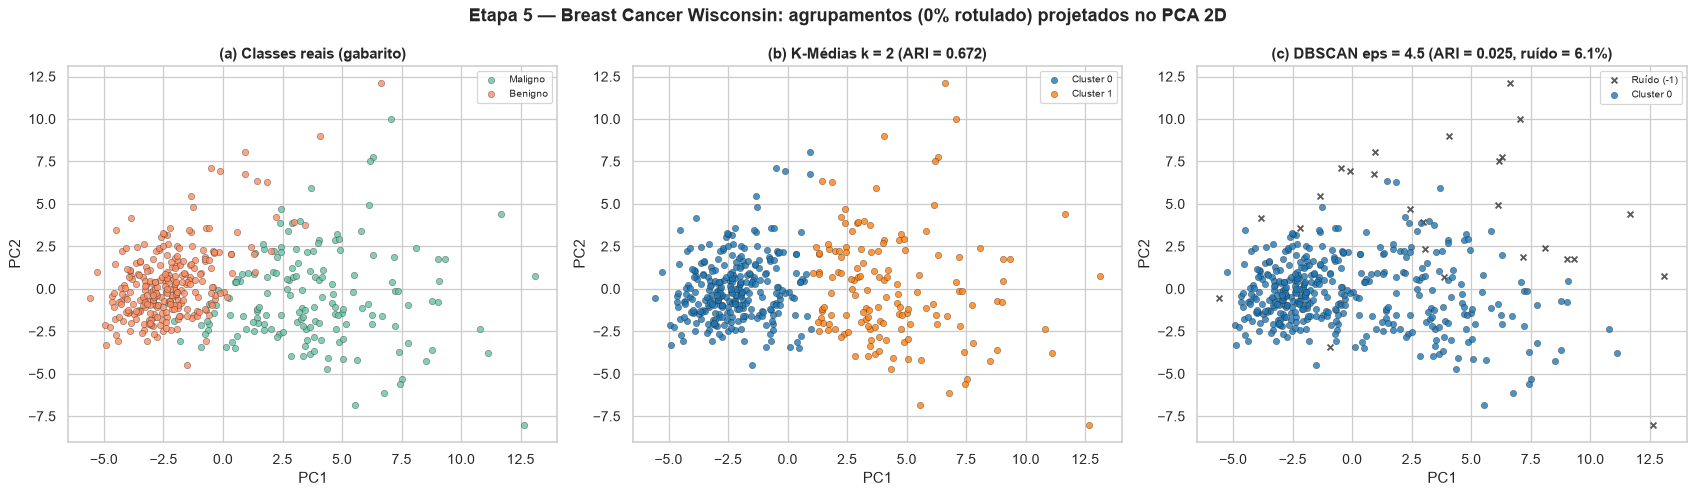

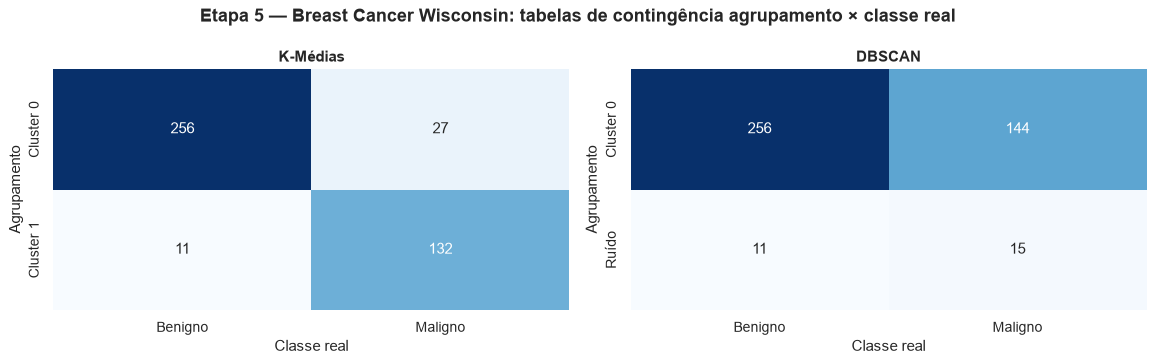

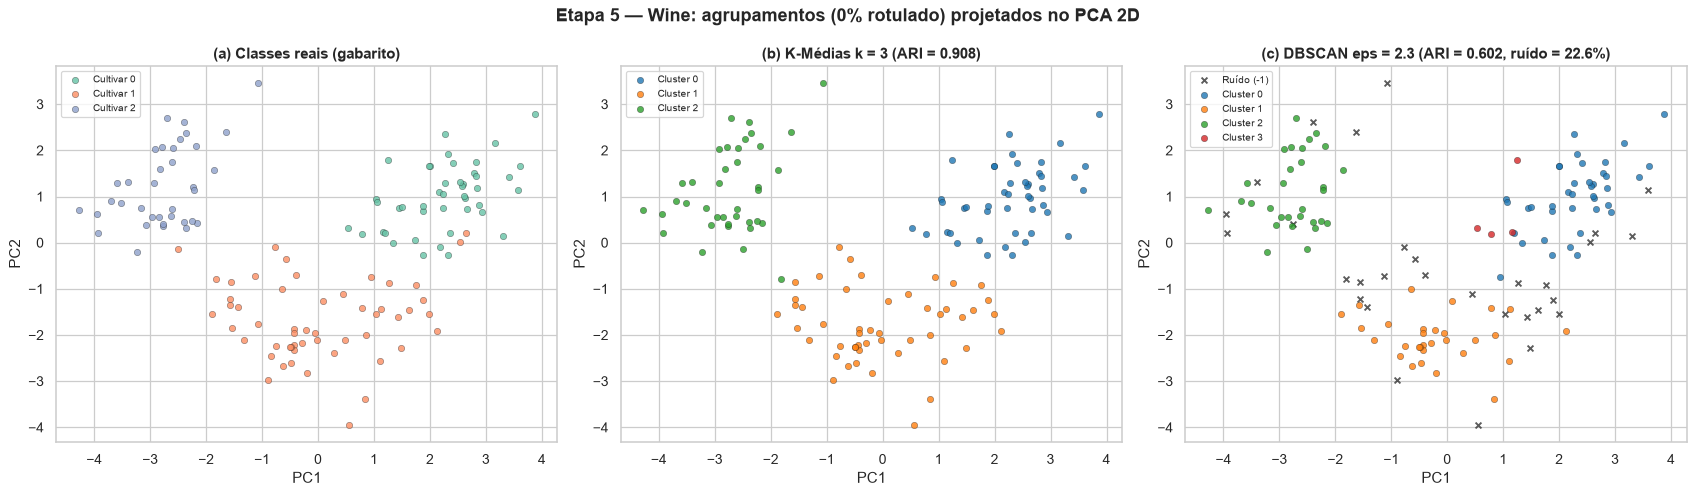

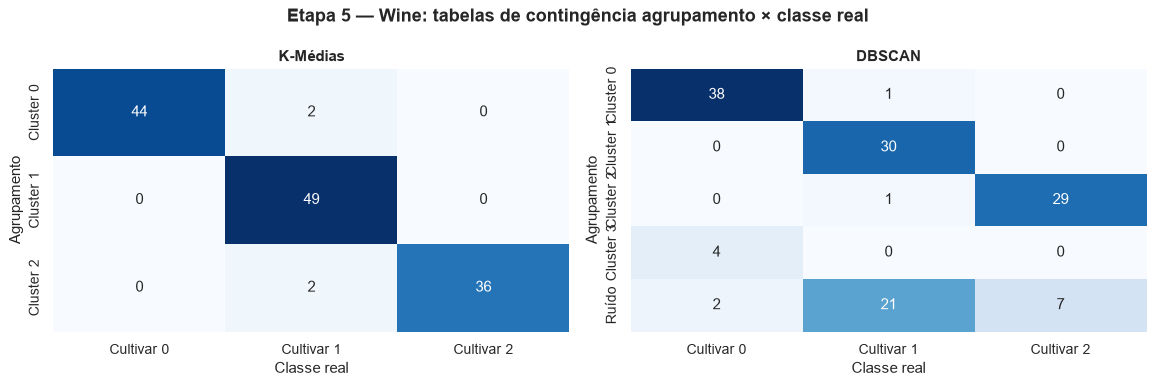

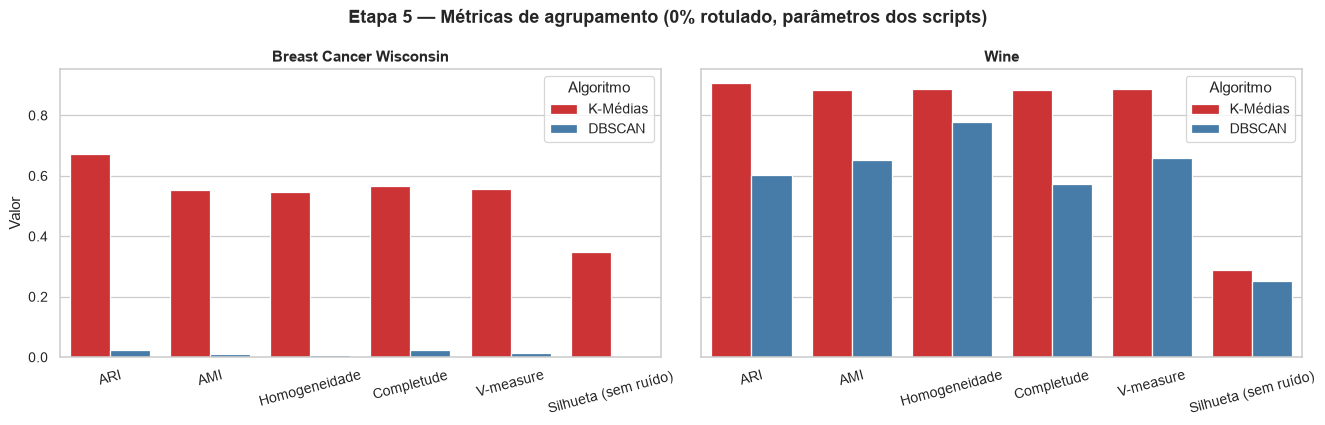

In [24]:
def desenhar_particao(ax, Z, rotulos, titulo, nomes=None):
    cores = sns.color_palette("tab10", 10)
    for c in sorted(set(rotulos)):
        m = rotulos == c
        if c == -1:
            ax.scatter(Z[m, 0], Z[m, 1], s=22, marker="x", color="#333333", alpha=0.8, label="Ruído (-1)")
        else:
            rotulo = nomes[c] if nomes is not None else f"Cluster {c}"
            cor = PALETA_CLASSES[c] if nomes is not None else cores[c % 10]
            ax.scatter(Z[m, 0], Z[m, 1], s=26, color=cor, alpha=0.8, edgecolor="k", lw=0.3, label=rotulo)
    ax.set_title(titulo)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8, loc="best")


for nome, d in DADOS.items():
    y, Z, C, p = d["y_tr"], d["Z_tr"], len(d["classes"]), PROTOCOLO[nome]
    km, db = d["kmeans"].labels_, d["dbscan_rotulos"]
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
    desenhar_particao(axes[0], Z, y, "(a) Classes reais (gabarito)", nomes=d["classes"])
    desenhar_particao(axes[1], Z, km, f"(b) K-Médias k = {C} (ARI = {adjusted_rand_score(y, km):.3f})")
    desenhar_particao(axes[2], Z, db, f"(c) DBSCAN eps = {p['dbscan_eps']} (ARI = {adjusted_rand_score(y, db):.3f}, "
                                      f"ruído = {np.mean(db == -1):.1%})")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: agrupamentos (0% rotulado) projetados no PCA 2D")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_agrupamentos_pca")

    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6 + 0.25 * C))
    for ax, (titulo, rot) in zip(axes, [("K-Médias", km), ("DBSCAN", db)]):
        tab = pd.crosstab(pd.Series(["Ruído" if r == -1 else f"Cluster {r}" for r in rot], name="Agrupamento"),
                          pd.Series([d["classes"][c] for c in y], name="Classe real"))
        sns.heatmap(tab, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set_title(titulo)
    fig.suptitle(f"Etapa 5 — {d['titulo']}: tabelas de contingência agrupamento × classe real")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_contingencia")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
metricas_cl = ["ARI", "AMI", "Homogeneidade", "Completude", "V-measure", "Silhueta (sem ruído)"]
for ax, (titulo, sub) in zip(axes, df_cluster.groupby("Dataset", sort=False)):
    longo = sub.assign(Algoritmo=sub["Algoritmo"].str.split(" \\(").str[0]).melt(
        id_vars="Algoritmo", value_vars=metricas_cl, var_name="Métrica", value_name="Valor")
    sns.barplot(data=longo, x="Métrica", y="Valor", hue="Algoritmo", palette="Set1", ax=ax)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Etapa 5 — Métricas de agrupamento (0% rotulado, parâmetros dos scripts)")
plt.tight_layout()
salvar_figura(fig, "E5_agrupamento_metricas")

#### 5.1.6 Do agrupamento ao classificador: o ponto "0% rotulado"

Para colocar o agrupamento na mesma escala dos classificadores, cada cluster do K-Médias (ajustado no treino) é associado a uma classe pelo **algoritmo húngaro** (a associação um-para-um que maximiza os acertos no treino). Depois, os pontos de **teste** são atribuídos ao centróide mais próximo. Essa referência é **otimista**, porque a associação cluster→classe usa os rótulos do treino. Ainda assim, ela mostra quanto da estrutura das classes o agrupamento captura sem supervisão.

In [25]:
def mapa_hungaro(clusters, y):
    tabela = pd.crosstab(clusters, y)
    linhas, colunas = linear_sum_assignment(-tabela.values)
    mapa = {tabela.index[i]: tabela.columns[j] for i, j in zip(linhas, colunas)}
    for c in tabela.index:  # clusters excedentes (k > nº de classes) recebem a classe majoritária
        mapa.setdefault(c, tabela.loc[c].idxmax())
    return mapa


registros_zero = []
for nome, d in DADOS.items():
    mapa = mapa_hungaro(d["kmeans"].labels_, d["y_tr"])
    y_pred_te = np.array([mapa[c] for c in d["kmeans"].predict(d["X_te_sc"])])
    d["ref_kmeans_0"] = {"Acurácia": accuracy_score(d["y_te"], y_pred_te),
                         "F1": f1_score(d["y_te"], y_pred_te, average="macro")}
    registros_zero.append({"Dataset": d["titulo"], **d["ref_kmeans_0"]})
df_zero = pd.DataFrame(registros_zero).set_index("Dataset")
df_zero.to_csv(PASTA_METRICAS / "E5_kmeans_0pct_teste.csv")
display(df_zero.round(4))

,Acurácia,F1
Dataset,,
Breast Cancer Wisconsin,0.9231,0.9158
Wine,0.9556,0.9563


**Interpretação do agrupamento (0% rotulado).**

- **K-Médias.** A silhueta, que não usa rótulos, atinge o máximo exatamente no número real de classes nos dois datasets (k = 2 no Breast Cancer e k = 3 no Wine). No Wine, o agrupamento praticamente reproduz as cultivares (ARI = 0,908). No Breast Cancer, a concordância é moderada (ARI = 0,672). Levados ao teste pelo mapeamento húngaro, os clusters do K-Médias já classificam corretamente 92,3% (Breast Cancer) e 95,6% (Wine) das amostras, **sem nenhum rótulo para formar os grupos**.
- **DBSCAN no Breast Cancer (eps = 4,5).** O `eps` do script fica perto do joelho da curva de k-distâncias (≈ 4,29) e produz **um único cluster** com 6,1% de ruído (ARI = 0,025). Na grade inteira, só 5 de 160 configurações formam 2 ou mais clusters: não existe um "vale de densidade" entre benignos e malignos. O melhor ARI da grade (0,400) é obtido com 1 cluster e 48% de ruído, ou seja, o DBSCAN só consegue isolar parte da classe maligna como *ruído* em torno de um núcleo denso. Isso é coerente com a Seção 3.2: 53,8% dos tumores malignos têm atributos *outliers*, contra 16,0% dos benignos.
- **DBSCAN no Wine (eps = 2,3; min_samples = 4).** O script obtém 4 clusters com 22,6% de ruído (ARI = 0,602), o melhor ARI da grade. Esse resultado, porém, depende de um ajuste fino: com `min_samples` = 4, só a faixa estreita de eps ≈ 2,2 a 2,4 separa mais de um grupo. Já com eps ≥ 2,5, incluindo o joelho da curva (≈ 2,73), tudo vira um único cluster.
- **Lição para a etapa seguinte:** após a padronização, as classes formam grupos aproximadamente convexos, mas encostados uns nos outros, sem regiões vazias entre elas. Isso favorece o K-Médias e prejudica o DBSCAN. O sucesso do agrupamento no Wine antecipa que os dados não rotulados devem ajudar mais nesse dataset do que no Breast Cancer.

### 5.2 Classificação semi-supervisionada (5% a 70% de rótulos)

Para cada taxa e repetição, uma fração dos pontos de treino mantém o rótulo e os demais recebem `-1` (não rotulado). Todos os modelos de uma repetição recebem **o mesmo** subconjunto rotulado, o que permite comparações pareadas. Os *baselines* são treinados **apenas** com os pontos rotulados, enquanto os semi-supervisionados usam também os não rotulados. A avaliação principal é feita no **conjunto de teste isolado** (acurácia e F1-macro). A avaliação transdutiva, nos pontos não rotulados do treino, é complementar.

In [26]:
from kdd_wine import mascarar_rotulos_estratificado  # função do próprio script: sorteio idêntico


def sortear_rotulados(nome, y, taxa, rep):
    """Devolve (y_semi, índices rotulados, semente) exatamente como o script do dataset."""
    if nome == "breast_cancer":
        semente = PROTOCOLO[nome]["sementes"][rep]
        idx_rot, _ = train_test_split(np.arange(len(y)), train_size=taxa, stratify=y, random_state=semente)
        y_semi = np.full_like(y, -1)
        y_semi[idx_rot] = y[idx_rot]
        return y_semi, idx_rot, semente
    semente = PROTOCOLO[nome]["sementes"][rep]
    y_semi = mascarar_rotulos_estratificado(y, taxa, min_por_classe=2, rng=np.random.default_rng(semente))
    return y_semi, np.where(y_semi != -1)[0], semente


def criar_modelos(nome, semente, n_rotulados, dim, **ajustes):
    """Modelos e hiperparâmetros de cada script. `ajustes` só é usado na análise de sensibilidade."""
    if nome == "breast_cancer":
        return {
            "Label Spreading (Semi)": LabelSpreading(kernel="knn", n_neighbors=ajustes.get("n_neighbors", 7),
                                                     alpha=ajustes.get("alpha", 0.2)),
            "Self-Training LR (Semi)": SelfTrainingClassifier(
                LogisticRegression(max_iter=1000, random_state=semente), threshold=ajustes.get("limiar", 0.75)),
            "KNN (Baseline)": KNeighborsClassifier(n_neighbors=min(ajustes.get("k_knn", 5), n_rotulados)),
            "Regressão Logística (Baseline)": LogisticRegression(max_iter=1000, random_state=semente),
        }
    gamma = ajustes.get("gamma", 1.0 / dim)
    return {
        "KNN (Baseline)": KNeighborsClassifier(
            n_neighbors=min(ajustes["k_knn"], n_rotulados) if "k_knn" in ajustes else min(5, max(1, n_rotulados // 2))),
        "Reg. Logistica (Baseline)": LogisticRegression(max_iter=1000, random_state=42),
        "Label Spreading": LabelSpreading(kernel="rbf", gamma=gamma, alpha=ajustes.get("alpha", 0.2), max_iter=1000),
        "Label Propagation": LabelPropagation(kernel="rbf", gamma=gamma, max_iter=1000),
        "Self-Training (LogReg)": SelfTrainingClassifier(LogisticRegression(max_iter=1000, random_state=42),
                                                         threshold=ajustes.get("limiar", 0.80)),
    }


todas_taxas = sorted({t for p in PROTOCOLO.values() for t in p["taxas"]})
display(pd.DataFrame(
    {f"{t:.0%}": [int((sortear_rotulados(n, d["y_tr"], t, 0)[0] != -1).sum()) if t in PROTOCOLO[n]["taxas"] else "—"
                  for n, d in DADOS.items()] for t in todas_taxas},
    index=[d["titulo"] for d in DADOS.values()]).rename_axis("Pontos rotulados no treino"))

,5%,10%,20%,30%,40%,50%,60%,70%
Pontos rotulados no treino,,,,,,,,
Breast Cancer Wisconsin,21,42,85,127,170,213,255,298
Wine,7,13,27,40,—,66,—,93


In [27]:
registros = []
PREDICOES = {}
t_inicio = time.perf_counter()
for nome, d in DADOS.items():
    X, y, X_te, y_te = d["X_tr_sc"], d["y_tr"], d["X_te_sc"], d["y_te"]
    p = PROTOCOLO[nome]
    for taxa in p["taxas"]:
        for rep in range(p["repeticoes"]):
            y_semi, idx_rot, semente = sortear_rotulados(nome, y, taxa, rep)
            idx_nao_rot = np.where(y_semi == -1)[0]
            for modelo, clf in criar_modelos(nome, semente, len(idx_rot), X.shape[1]).items():
                t0 = time.perf_counter()
                if modelo in BASELINES[nome]:
                    clf.fit(X[idx_rot], y[idx_rot])
                else:
                    clf.fit(X, y_semi)
                tempo = time.perf_counter() - t0
                y_pred = clf.predict(X_te)
                PREDICOES[(nome, modelo, taxa, rep)] = y_pred
                registros.append({
                    "Dataset": nome, "Modelo": modelo, "Taxa": taxa, "Rep": rep, "Rotulados": len(idx_rot),
                    "Acurácia": accuracy_score(y_te, y_pred), "F1": f1_score(y_te, y_pred, average="macro"),
                    "F1 transdutivo": f1_score(y[idx_nao_rot], clf.predict(X[idx_nao_rot]), average="macro"),
                    "Tempo (ms)": tempo * 1000,
                })
RES = pd.DataFrame(registros)
RES.to_csv(PASTA_METRICAS / "E5_semi_supervisionado_execucoes.csv", index=False)
RESUMO = (RES.groupby(["Dataset", "Modelo", "Taxa"], sort=False)
          .agg(Rotulados=("Rotulados", "first"), Acc_media=("Acurácia", "mean"), Acc_dp=("Acurácia", "std"),
               F1_media=("F1", "mean"), F1_dp=("F1", "std"), F1_trans_media=("F1 transdutivo", "mean"),
               Tempo_ms=("Tempo (ms)", "mean"))
          .reset_index())
RESUMO.to_csv(PASTA_METRICAS / "E5_semi_supervisionado_resumo.csv", index=False)
print(f"{len(RES)} treinamentos em {time.perf_counter() - t_inicio:.1f} s")

# Referências com 100% dos rótulos (supervisionado completo)
for nome, d in DADOS.items():
    d["ref_100"] = {}
    for modelo, clf in [("RL 100%", LogisticRegression(max_iter=1000, random_state=42)),
                        ("KNN 100%", KNeighborsClassifier(5))]:
        y_pred = clf.fit(d["X_tr_sc"], d["y_tr"]).predict(d["X_te_sc"])
        d["ref_100"][modelo] = {"Acurácia": accuracy_score(d["y_te"], y_pred),
                                "F1": f1_score(d["y_te"], y_pred, average="macro")}

for nome, d in DADOS.items():
    sub = RESUMO[RESUMO["Dataset"] == nome].copy()
    sub["F1 (média ± dp)"] = sub.apply(lambda r: f"{r['F1_media']:.4f} ± {r['F1_dp']:.4f}", axis=1)
    sub["Acurácia (média ± dp)"] = sub.apply(lambda r: f"{r['Acc_media']:.4f} ± {r['Acc_dp']:.4f}", axis=1)
    print(f"\n{d['titulo']} ({PROTOCOLO[nome]['repeticoes']} repetições) | RL 100%: "
          f"F1 = {d['ref_100']['RL 100%']['F1']:.4f} | K-Médias 0% (húngaro): F1 = {d['ref_kmeans_0']['F1']:.4f}")
    display(sub.pivot(index=["Taxa", "Rotulados"], columns="Modelo", values="F1 (média ± dp)")[PROTOCOLO[nome]["modelos"]])
    display(sub.pivot(index=["Taxa", "Rotulados"], columns="Modelo", values="Acurácia (média ± dp)")[PROTOCOLO[nome]["modelos"]])

460 treinamentos em 5.1 s

Breast Cancer Wisconsin (5 repetições) | RL 100%: F1 = 0.9850 | K-Médias 0% (húngaro): F1 = 0.9158


,Modelo,Label Spreading (Semi),Self-Training LR (Semi),KNN (Baseline),Regressão Logística (Baseline)
Taxa,Rotulados,,,,
0.05,21,0.9359 ± 0.0073,0.9300 ± 0.0210,0.9065 ± 0.0141,0.9255 ± 0.0166
0.10,42,0.9258 ± 0.0108,0.9358 ± 0.0149,0.9247 ± 0.0095,0.9391 ± 0.0113
0.20,85,0.9378 ± 0.0142,0.9480 ± 0.0067,0.9416 ± 0.0067,0.9469 ± 0.0100
0.30,127,0.9438 ± 0.0139,0.9605 ± 0.0083,0.9448 ± 0.0175,0.9619 ± 0.0123
0.40,170,0.9588 ± 0.0119,0.9652 ± 0.0115,0.9513 ± 0.0070,0.9697 ± 0.0097
0.50,213,0.9528 ± 0.0138,0.9744 ± 0.0088,0.9559 ± 0.0085,0.9729 ± 0.0115
0.60,255,0.9558 ± 0.0068,0.9759 ± 0.0099,0.9575 ± 0.0072,0.9759 ± 0.0063
0.70,298,0.9619 ± 0.0095,0.9820 ± 0.0041,0.9636 ± 0.0084,0.9820 ± 0.0041


,Modelo,Label Spreading (Semi),Self-Training LR (Semi),KNN (Baseline),Regressão Logística (Baseline)
Taxa,Rotulados,,,,
0.05,21,0.9413 ± 0.0063,0.9371 ± 0.0178,0.9161 ± 0.0121,0.9329 ± 0.0136
0.10,42,0.9315 ± 0.0104,0.9413 ± 0.0145,0.9315 ± 0.0091,0.9441 ± 0.0111
0.20,85,0.9427 ± 0.0135,0.9524 ± 0.0059,0.9469 ± 0.0063,0.9510 ± 0.0099
0.30,127,0.9483 ± 0.0127,0.9636 ± 0.0077,0.9497 ± 0.0159,0.9650 ± 0.0111
0.40,170,0.9622 ± 0.0106,0.9678 ± 0.0106,0.9552 ± 0.0063,0.9720 ± 0.0086
0.50,213,0.9566 ± 0.0125,0.9762 ± 0.0080,0.9594 ± 0.0077,0.9748 ± 0.0106
0.60,255,0.9594 ± 0.0059,0.9776 ± 0.0091,0.9608 ± 0.0063,0.9776 ± 0.0059
0.70,298,0.9650 ± 0.0086,0.9832 ± 0.0038,0.9664 ± 0.0077,0.9832 ± 0.0038



Wine (10 repetições) | RL 100%: F1 = 1.0000 | K-Médias 0% (húngaro): F1 = 0.9563


,Modelo,KNN (Baseline),Reg. Logistica (Baseline),Label Spreading,Label Propagation,Self-Training (LogReg)
Taxa,Rotulados,,,,,
0.05,7,0.8622 ± 0.0915,0.9296 ± 0.0385,0.8739 ± 0.0767,0.2372 ± 0.0894,0.9798 ± 0.0126
0.10,13,0.9059 ± 0.0399,0.9366 ± 0.0339,0.9308 ± 0.0465,0.6449 ± 0.2266,0.9827 ± 0.0168
0.20,27,0.9400 ± 0.0253,0.9709 ± 0.0154,0.9389 ± 0.0387,0.8720 ± 0.0719,0.9852 ± 0.0103
0.30,40,0.9756 ± 0.0124,0.9692 ± 0.0275,0.9573 ± 0.0200,0.9329 ± 0.0175,0.9819 ± 0.0176
0.50,66,0.9558 ± 0.0180,0.9730 ± 0.0226,0.9464 ± 0.0308,0.9320 ± 0.0279,0.9866 ± 0.0159
0.70,93,0.9554 ± 0.0184,0.9860 ± 0.0121,0.9745 ± 0.0274,0.9705 ± 0.0299,0.9906 ± 0.0121


,Modelo,KNN (Baseline),Reg. Logistica (Baseline),Label Spreading,Label Propagation,Self-Training (LogReg)
Taxa,Rotulados,,,,,
0.05,7,0.8644 ± 0.0847,0.9289 ± 0.0389,0.8800 ± 0.0613,0.4111 ± 0.0567,0.9800 ± 0.0126
0.10,13,0.9044 ± 0.0420,0.9356 ± 0.0354,0.9311 ± 0.0438,0.7133 ± 0.1710,0.9822 ± 0.0175
0.20,27,0.9378 ± 0.0273,0.9711 ± 0.0150,0.9378 ± 0.0403,0.8756 ± 0.0704,0.9844 ± 0.0107
0.30,40,0.9756 ± 0.0126,0.9689 ± 0.0281,0.9578 ± 0.0195,0.9333 ± 0.0181,0.9822 ± 0.0175
0.50,66,0.9556 ± 0.0181,0.9733 ± 0.0230,0.9467 ± 0.0318,0.9311 ± 0.0305,0.9867 ± 0.0155
0.70,93,0.9556 ± 0.0181,0.9867 ± 0.0115,0.9756 ± 0.0266,0.9711 ± 0.0297,0.9911 ± 0.0115


#### 5.2.1 Conferência com os scripts

Médias e desvios padrão de acurácia e F1-macro, comparados linha a linha com os CSVs gerados pelos scripts. Se houver qualquer divergência, a célula interrompe a execução.

In [28]:
conferencia = []
for nome, d in DADOS.items():
    csv = pd.read_csv(PROTOCOLO[nome]["csv_semi"]).rename(columns={
        "Taxa_Rotulados": "Taxa", "Acuracia_Media": "Acc_media", "Acuracia_DP": "Acc_dp",
        "F1_Media": "F1_media", "F1_DP": "F1_dp", "F1_Macro_Media": "F1_media", "F1_Macro_DP": "F1_dp"})
    nb = RESUMO[RESUMO["Dataset"] == nome]
    junto = nb.merge(csv, on=["Taxa", "Modelo"], suffixes=("_nb", "_script"), validate="one_to_one")
    assert len(junto) == len(nb) == len(csv), f"{nome}: combinações taxa × modelo diferentes do script"
    linha = {"Dataset": d["titulo"], "Linhas comparadas": len(junto)}
    for col in ["Acc_media", "Acc_dp", "F1_media", "F1_dp"]:
        linha[f"Maior diferença em {col}"] = float(np.abs(junto[f"{col}_nb"] - junto[f"{col}_script"]).max())
    conferencia.append(linha)
conferencia = pd.DataFrame(conferencia).set_index("Dataset")
display(conferencia)
assert (conferencia.filter(like="Maior diferença") < 1e-9).all().all(), "o notebook diverge dos scripts"
print("Resultados semi-supervisionados idênticos aos dos scripts.")

,Linhas comparadas,Maior diferença em Acc_media,Maior diferença em Acc_dp,Maior diferença em F1_media,Maior diferença em F1_dp
Dataset,,,,,
Breast Cancer Wisconsin,32,1.110223e-16,9.887924e-17,1.110223e-16,9.714451e-17
Wine,30,1.110223e-16,9.367507e-17,1.110223e-16,9.714451e-17


Resultados semi-supervisionados idênticos aos dos scripts.


#### 5.2.2 Curvas de aprendizado: desempenho × taxa de rótulos

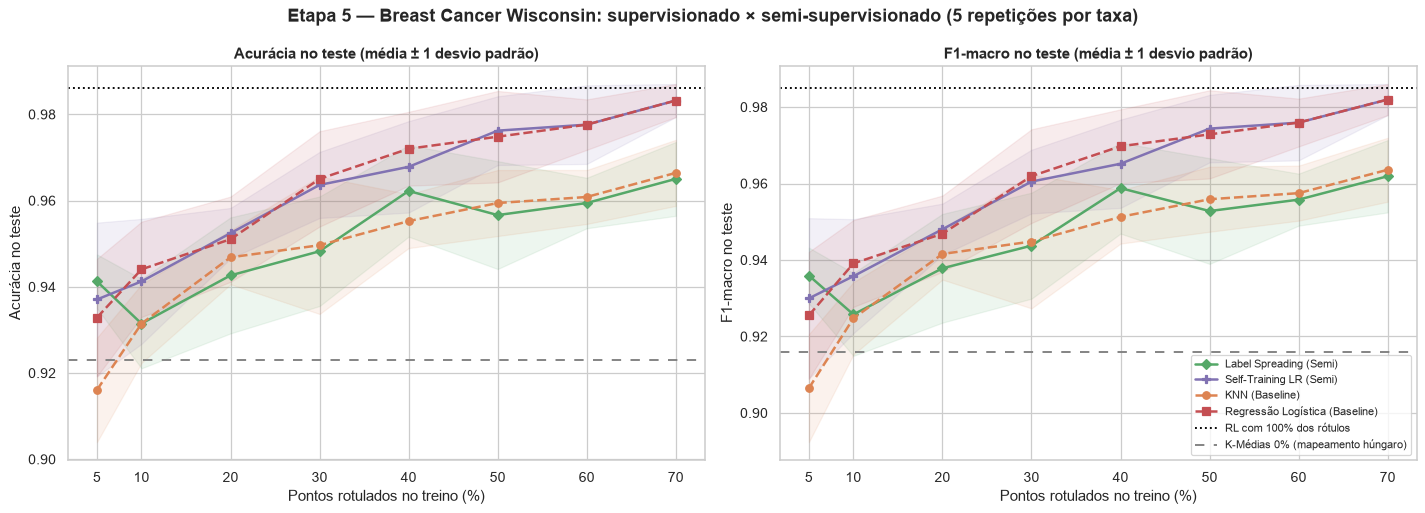

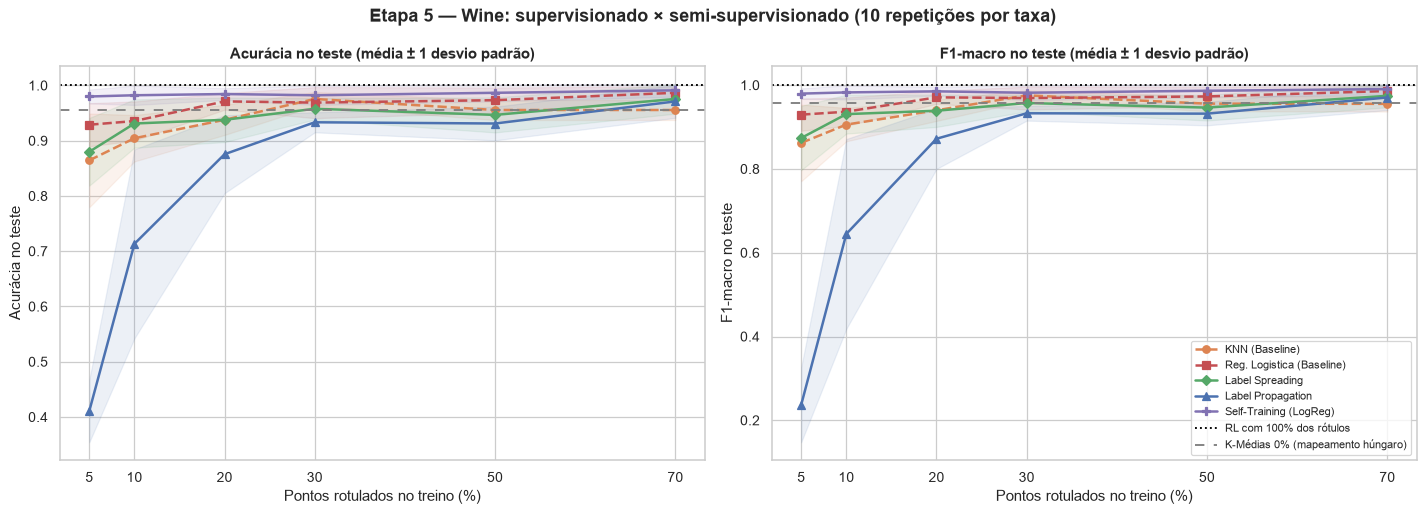

In [29]:
for nome, d in DADOS.items():
    sub = RESUMO[RESUMO["Dataset"] == nome]
    taxas = PROTOCOLO[nome]["taxas"]
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
    for ax, (col_m, col_dp, titulo, chave) in zip(axes, [("Acc_media", "Acc_dp", "Acurácia no teste", "Acurácia"),
                                                         ("F1_media", "F1_dp", "F1-macro no teste", "F1")]):
        for modelo in PROTOCOLO[nome]["modelos"]:
            s = sub[sub["Modelo"] == modelo]
            x = s["Taxa"] * 100
            ax.plot(x, s[col_m], label=modelo, lw=2, ms=6, **ESTILO[modelo])
            ax.fill_between(x, s[col_m] - s[col_dp], s[col_m] + s[col_dp], color=ESTILO[modelo]["color"], alpha=0.10)
        ax.axhline(d["ref_100"]["RL 100%"][chave], color="black", ls=":", lw=1.5, label="RL com 100% dos rótulos")
        ax.axhline(d["ref_kmeans_0"][chave], color="gray", ls=(0, (5, 5)), lw=1.5,
                   label="K-Médias 0% (mapeamento húngaro)")
        ax.set_xticks([t * 100 for t in taxas])
        ax.set_xlabel("Pontos rotulados no treino (%)")
        ax.set_ylabel(titulo)
        ax.set_title(titulo + " (média ± 1 desvio padrão)")
    axes[1].legend(fontsize=8.5, loc="lower right")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: supervisionado × semi-supervisionado "
                 f"({PROTOCOLO[nome]['repeticoes']} repetições por taxa)")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_curva_aprendizado")

#### 5.2.3 Ganho do semi-supervisionado sobre o melhor *baseline*

Para cada taxa calculamos ΔF1 = F1(método) − F1(melhor *baseline* naquela taxa), usando a média das repetições. Valores positivos (azul) indicam que usar os dados não rotulados ajudou.

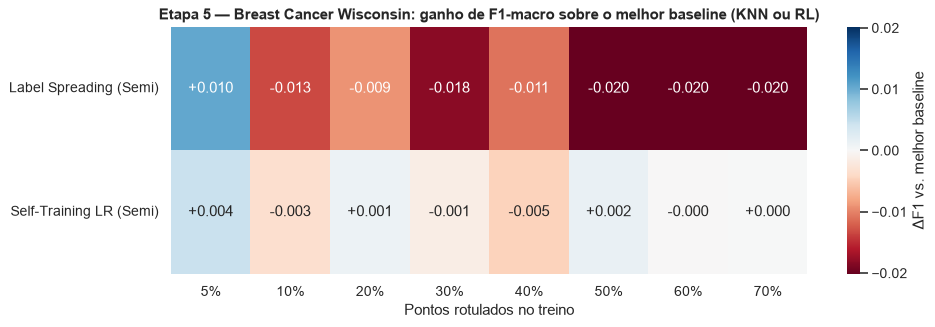

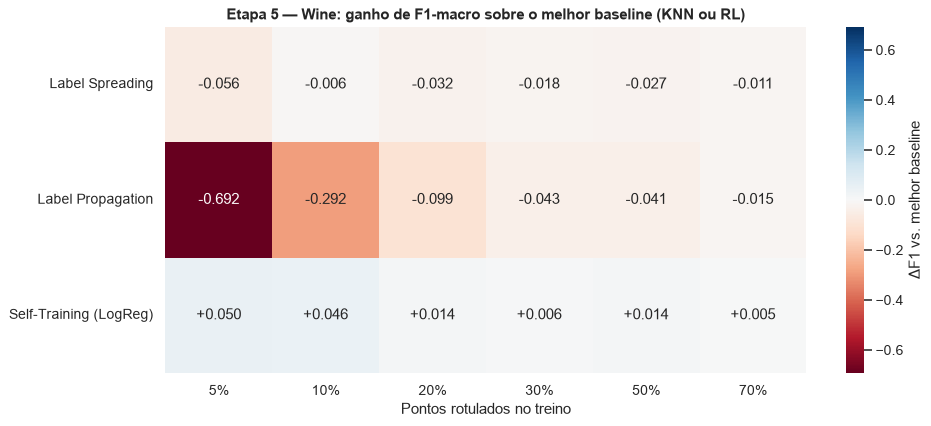

In [30]:
for nome, d in DADOS.items():
    piv = RESUMO[RESUMO["Dataset"] == nome].pivot(index="Modelo", columns="Taxa", values="F1_media")
    delta = piv.loc[SEMI[nome]] - piv.loc[BASELINES[nome]].max(axis=0)
    d["delta_f1"] = delta
    lim = np.abs(delta.values).max()
    fig, ax = plt.subplots(figsize=(11, 1.1 * len(SEMI[nome]) + 1.6))
    sns.heatmap(delta, annot=True, fmt="+.3f", cmap="RdBu", center=0, vmin=-lim, vmax=lim,
                cbar_kws={"label": "ΔF1 vs. melhor baseline"}, ax=ax,
                xticklabels=[f"{t:.0%}" for t in delta.columns])
    ax.set_xlabel("Pontos rotulados no treino")
    ax.set_ylabel("")
    ax.set_title(f"Etapa 5 — {d['titulo']}: ganho de F1-macro sobre o melhor baseline (KNN ou RL)")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_ganho_semi_vs_baseline")

#### 5.2.4 Variabilidade entre repetições

Com poucos rótulos, o resultado depende muito de *quais* pontos foram rotulados. Os *boxplots* mostram a distribuição do F1-macro entre as repetições.

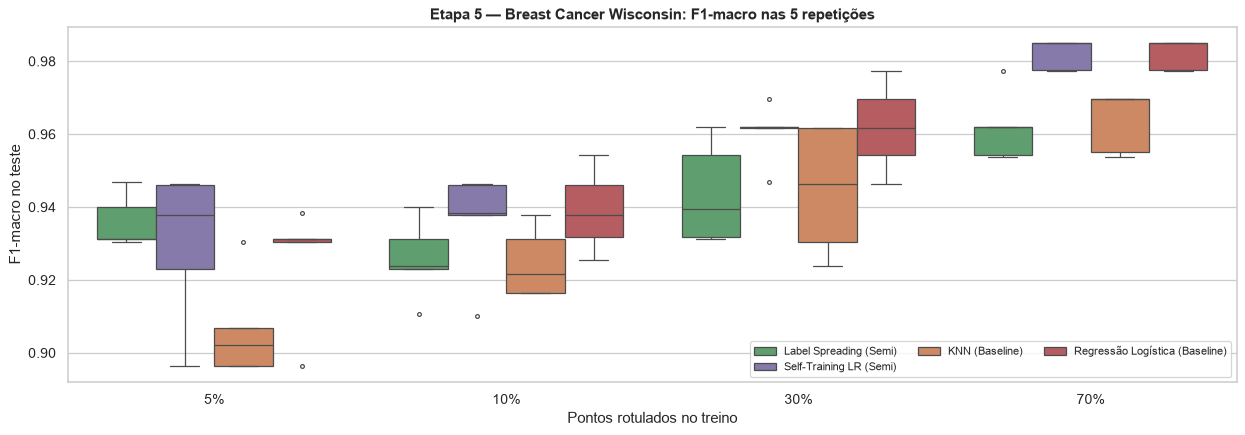

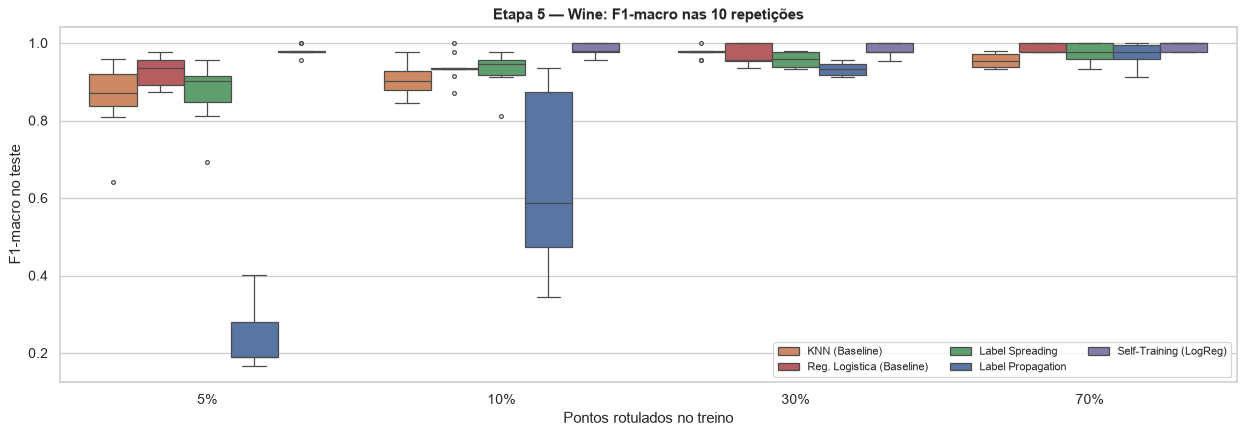

In [31]:
TAXAS_BOX = [0.05, 0.10, 0.30, 0.70]
for nome, d in DADOS.items():
    sub = RES[(RES["Dataset"] == nome) & (RES["Taxa"].isin(TAXAS_BOX))].copy()
    sub["Taxa (%)"] = (sub["Taxa"] * 100).round().astype(int).astype(str) + "%"
    fig, ax = plt.subplots(figsize=(14, 5))
    sns.boxplot(data=sub, x="Taxa (%)", y="F1", hue="Modelo", hue_order=PROTOCOLO[nome]["modelos"],
                palette=[ESTILO[m]["color"] for m in PROTOCOLO[nome]["modelos"]], fliersize=3, ax=ax)
    ax.set_ylabel("F1-macro no teste")
    ax.set_xlabel("Pontos rotulados no treino")
    ax.legend(fontsize=8.5, ncols=3, loc="lower right")
    ax.set_title(f"Etapa 5 — {d['titulo']}: F1-macro nas {PROTOCOLO[nome]['repeticoes']} repetições")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_boxplot_f1_repeticoes")

#### 5.2.5 Avaliação indutiva (teste) × transdutiva (não rotulados do treino)

Os métodos semi-supervisionados veem os pontos não rotulados durante o treino. A avaliação transdutiva mede o acerto justamente nesses pontos, como no código da Aula 6. A avaliação indutiva mede a generalização para dados novos (o conjunto de teste).

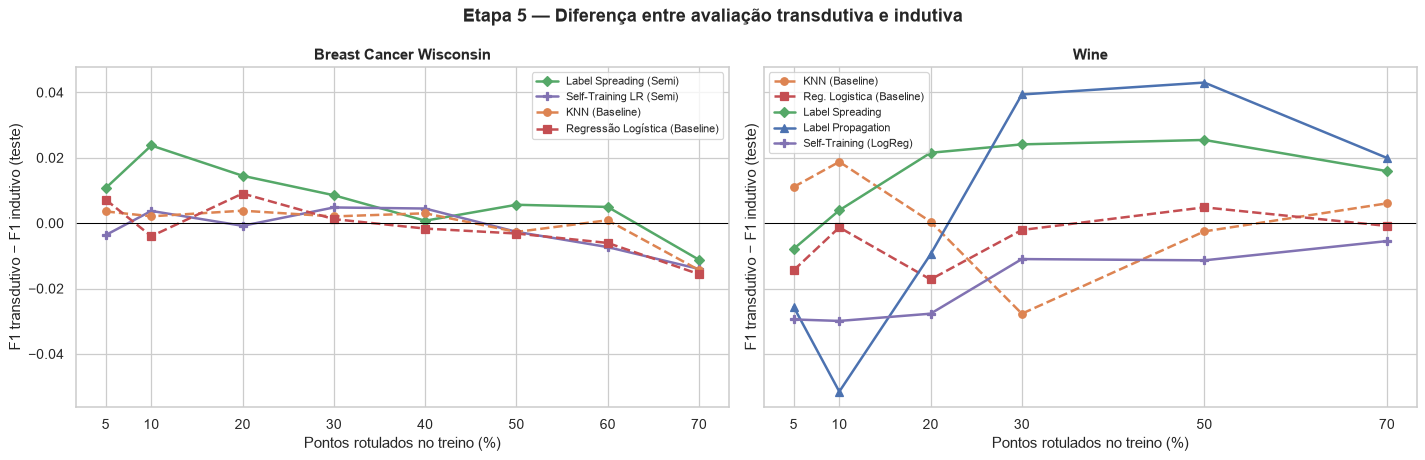

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharey=True)
for ax, (nome, d) in zip(axes, DADOS.items()):
    sub = RESUMO[RESUMO["Dataset"] == nome]
    for modelo in PROTOCOLO[nome]["modelos"]:
        s = sub[sub["Modelo"] == modelo]
        ax.plot(s["Taxa"] * 100, s["F1_trans_media"] - s["F1_media"], lw=2, label=modelo, **ESTILO[modelo])
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks([t * 100 for t in PROTOCOLO[nome]["taxas"]])
    ax.set_xlabel("Pontos rotulados no treino (%)")
    ax.set_ylabel("F1 transdutivo − F1 indutivo (teste)")
    ax.set_title(d["titulo"])
    ax.legend(fontsize=8.5)
fig.suptitle("Etapa 5 — Diferença entre avaliação transdutiva e indutiva")
plt.tight_layout()
salvar_figura(fig, "E5_transdutivo_vs_indutivo")

#### 5.2.6 Matrizes de confusão

Três visões complementares:

1. **Execução representativa do melhor semi-supervisionado** (5% × 70%): o melhor método semi-supervisionado (maior F1 médio entre todas as taxas) e, em cada taxa, a repetição cujo F1 é o mais próximo da média. É o critério do script do Breast Cancer, aplicado aqui aos dois datasets.
2. **Wine: primeira repetição com 5% de rótulos** para quatro modelos, como na figura do script do Wine.
3. **Matrizes acumuladas** em todas as repetições, normalizadas por linha.

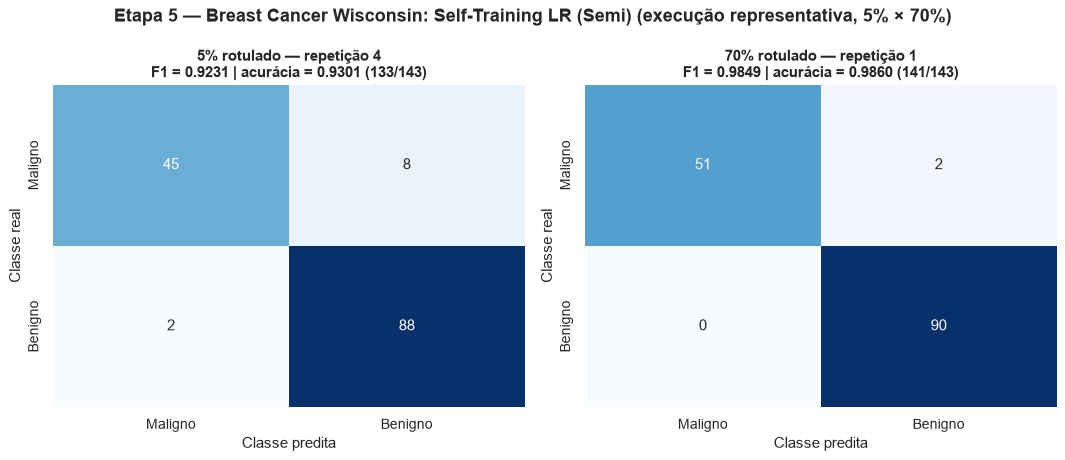

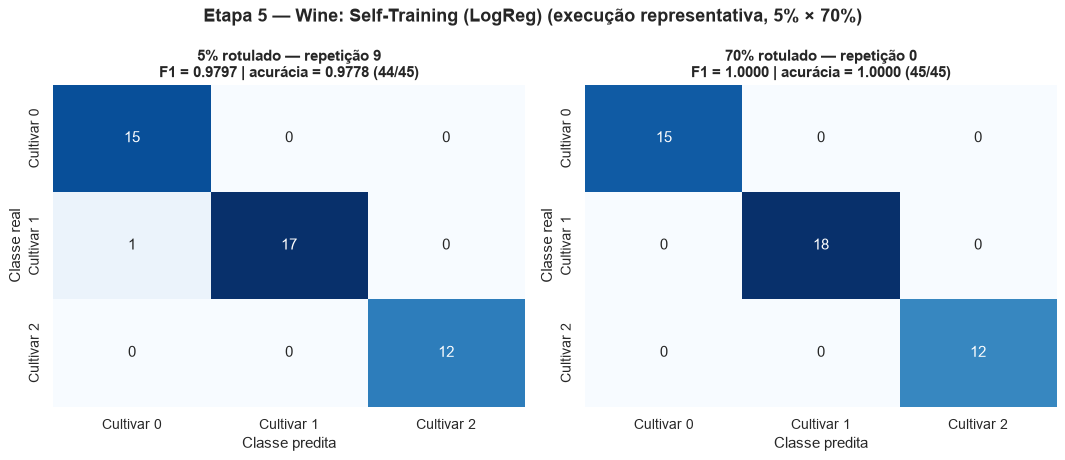

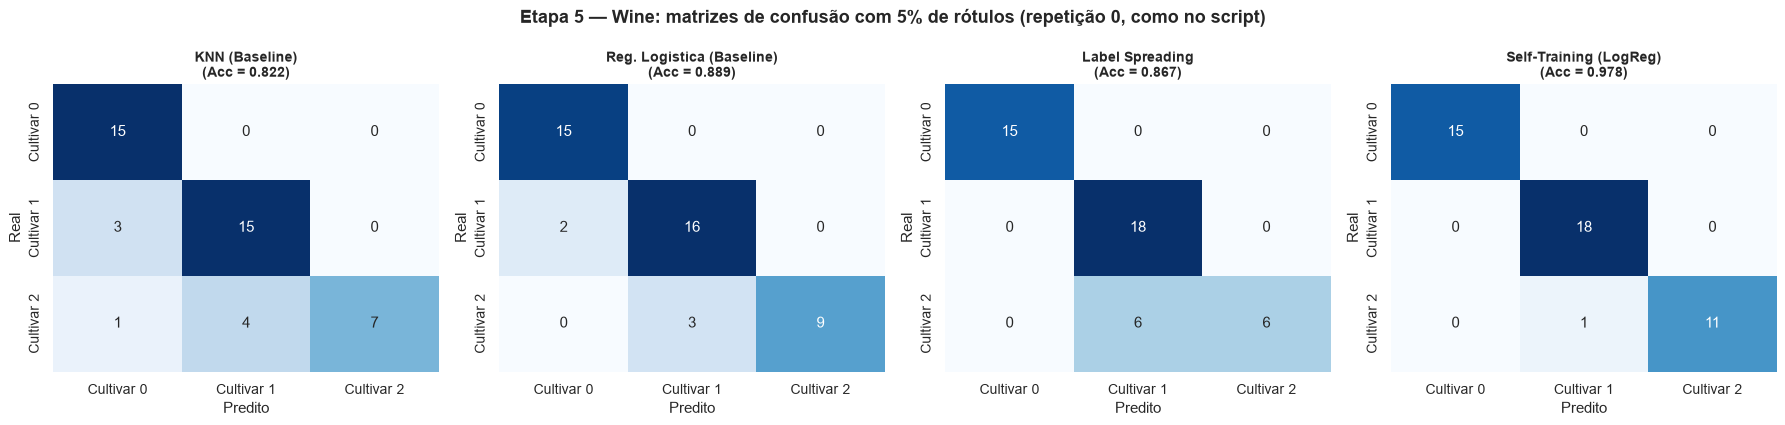

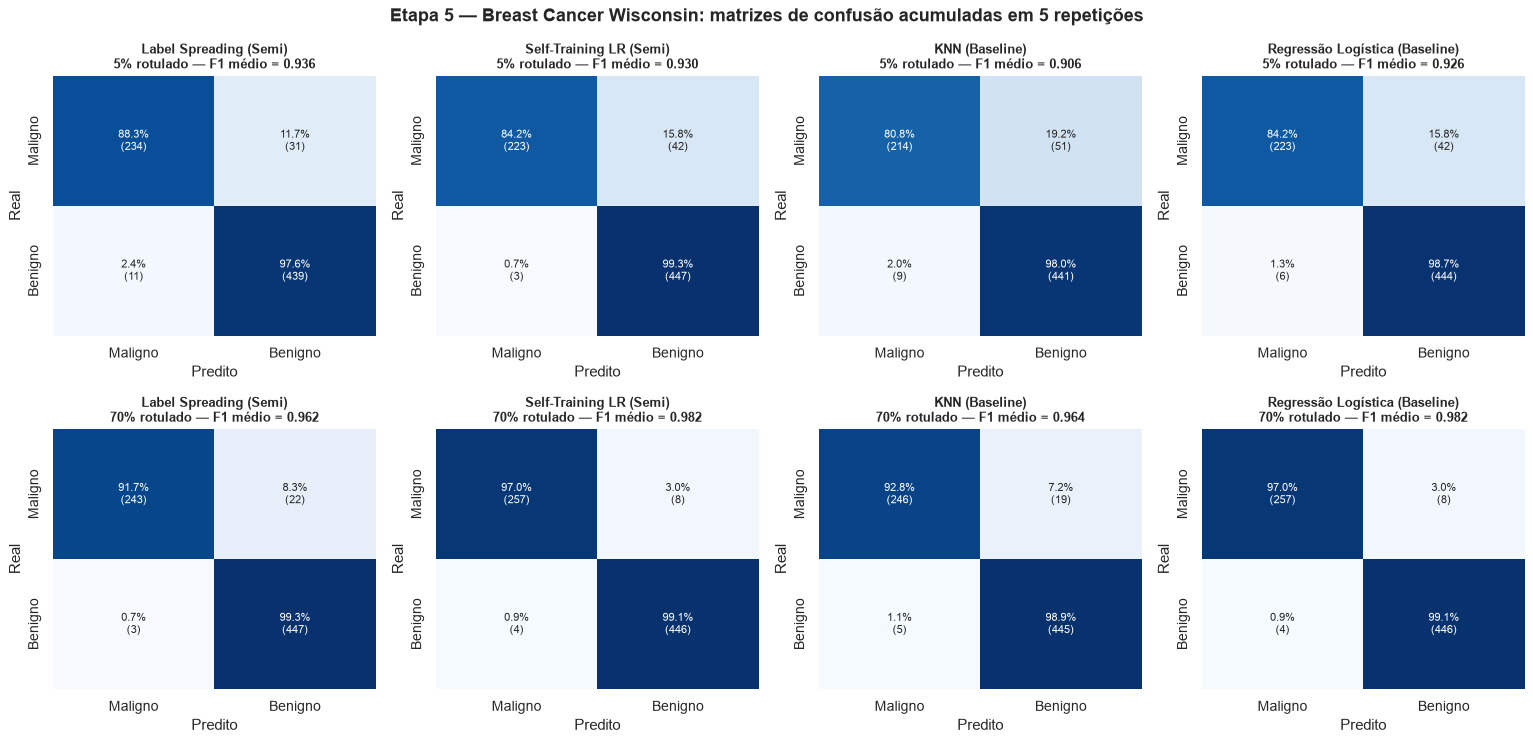

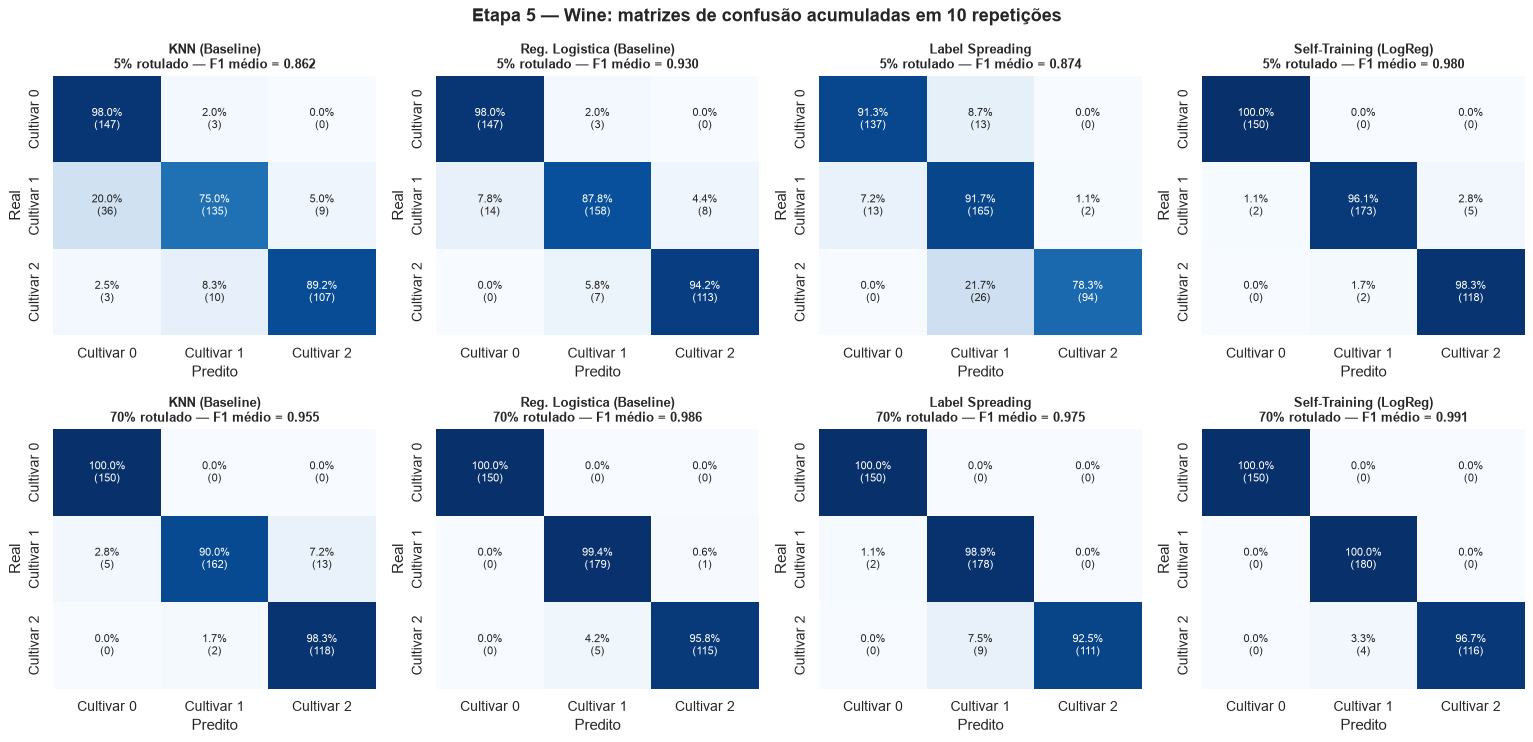

In [33]:
def melhor_semi(nome):
    return RESUMO[(RESUMO["Dataset"] == nome) & (RESUMO["Modelo"].isin(SEMI[nome]))].groupby("Modelo")["F1_media"].mean().idxmax()


def execucao_representativa(nome, modelo, taxa):
    """Repetição com F1 mais próximo do F1 médio (primeira, em caso de empate), como no script do Breast Cancer."""
    s = RES[(RES["Dataset"] == nome) & (RES["Modelo"] == modelo) & (RES["Taxa"] == taxa)].sort_values("Rep")
    rep = int(s.loc[(s["F1"] - s["F1"].mean()).abs().idxmin(), "Rep"])
    return rep, PREDICOES[(nome, modelo, taxa, rep)]


for nome, d in DADOS.items():
    d["melhor_semi"] = melhor_semi(nome)
    C = len(d["classes"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
    for ax, taxa in zip(axes, [0.05, 0.70]):
        rep, y_pred = execucao_representativa(nome, d["melhor_semi"], taxa)
        cm = confusion_matrix(d["y_te"], y_pred, labels=range(C))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=d["classes"],
                    yticklabels=d["classes"], ax=ax, annot_kws={"size": 12})
        ax.set_title(f"{taxa:.0%} rotulado — repetição {rep}\nF1 = {f1_score(d['y_te'], y_pred, average='macro'):.4f} | "
                     f"acurácia = {accuracy_score(d['y_te'], y_pred):.4f} ({int(np.trace(cm))}/{cm.sum()})")
        ax.set_xlabel("Classe predita")
        ax.set_ylabel("Classe real")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: {d['melhor_semi']} (execução representativa, 5% × 70%)")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_matriz_representativa")

nome, d = "wine", DADOS["wine"]
modelos_rep0 = ["KNN (Baseline)", "Reg. Logistica (Baseline)", "Label Spreading", "Self-Training (LogReg)"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, modelo in zip(axes, modelos_rep0):
    y_pred = PREDICOES[(nome, modelo, 0.05, 0)]
    sns.heatmap(confusion_matrix(d["y_te"], y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=d["classes"], yticklabels=d["classes"], ax=ax)
    ax.set_title(f"{modelo}\n(Acc = {accuracy_score(d['y_te'], y_pred):.3f})", fontsize=11)
    ax.set_xlabel("Predito")
    ax.set_ylabel("Real")
fig.suptitle("Etapa 5 — Wine: matrizes de confusão com 5% de rótulos (repetição 0, como no script)")
plt.tight_layout()
salvar_figura(fig, "E5_wine_matrizes_rep0_5pct")

for nome, d in DADOS.items():
    C, modelos = len(d["classes"]), [m for m in PROTOCOLO[nome]["modelos"] if m != "Label Propagation"]
    fig, axes = plt.subplots(2, len(modelos), figsize=(4.3 * len(modelos), 8.4))
    for i, taxa in enumerate([0.05, 0.70]):
        for j, modelo in enumerate(modelos):
            cm = sum(confusion_matrix(d["y_te"], PREDICOES[(nome, modelo, taxa, rep)], labels=range(C))
                     for rep in range(PROTOCOLO[nome]["repeticoes"]))
            cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
            anot = np.array([[f"{p:.1f}%\n({n})" for p, n in zip(lp, ln)] for lp, ln in zip(cm_pct, cm)])
            sns.heatmap(cm_pct, annot=anot, fmt="", cmap="Blues", vmin=0, vmax=100, cbar=False,
                        xticklabels=d["classes"], yticklabels=d["classes"], ax=axes[i, j], annot_kws={"size": 9})
            f1_med = RESUMO.query("Dataset == @nome and Modelo == @modelo and Taxa == @taxa")["F1_media"].iloc[0]
            axes[i, j].set_title(f"{modelo}\n{taxa:.0%} rotulado — F1 médio = {f1_med:.3f}", fontsize=10)
            axes[i, j].set_xlabel("Predito")
            axes[i, j].set_ylabel("Real")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: matrizes de confusão acumuladas em "
                 f"{PROTOCOLO[nome]['repeticoes']} repetições")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_matrizes_acumuladas")

#### 5.2.7 Como a propagação de rótulos funciona (5% rotulado)

Visualização da primeira repetição do Label Spreading com 5% dos rótulos (configuração de cada script), no espaço PCA 2D: (a) os poucos pontos rotulados, (b) os rótulos inferidos para o treino inteiro, (c) os acertos e erros nos pontos não rotulados e (d) a confiança da inferência (maior probabilidade da distribuição de rótulos).

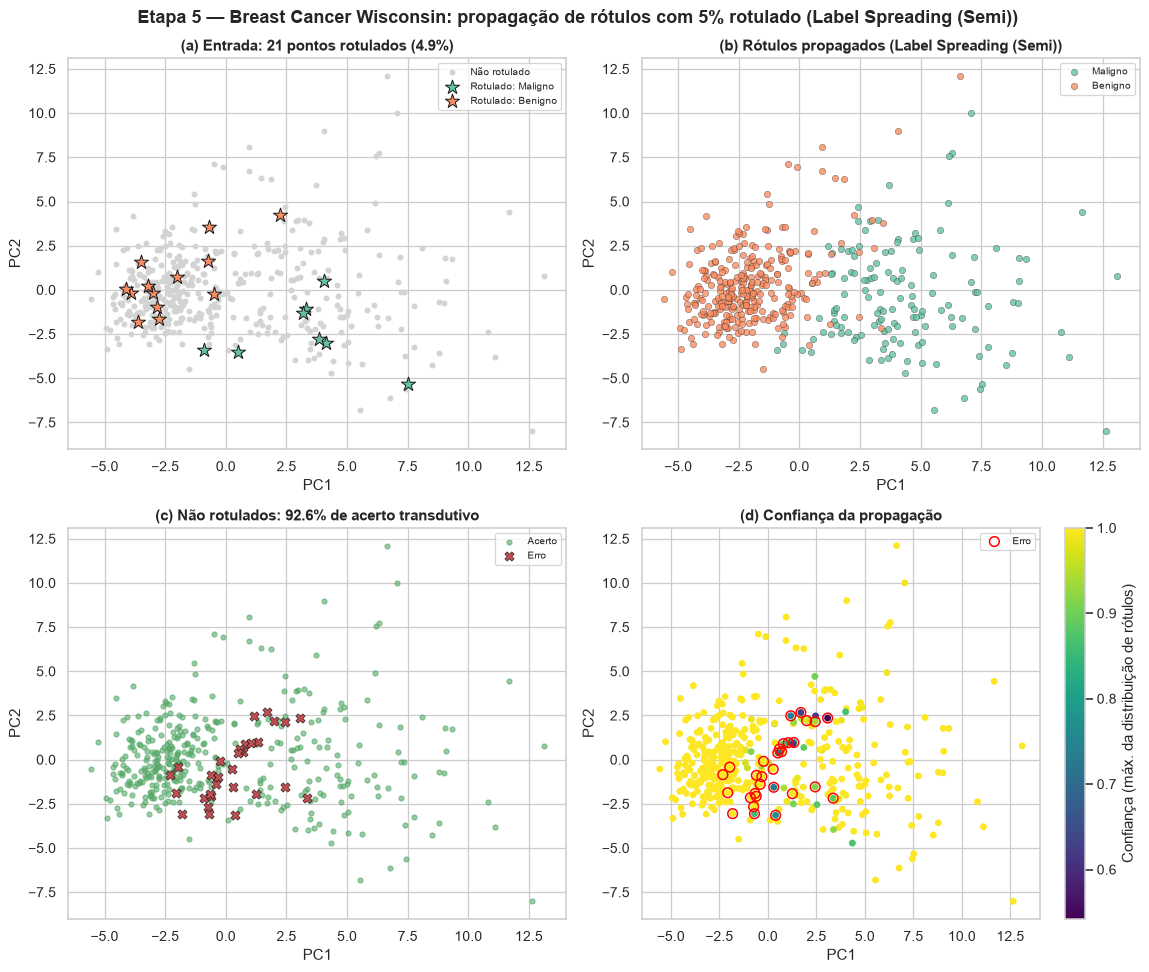

Breast Cancer Wisconsin: confiança média nos acertos = 0.993 | nos erros = 0.914


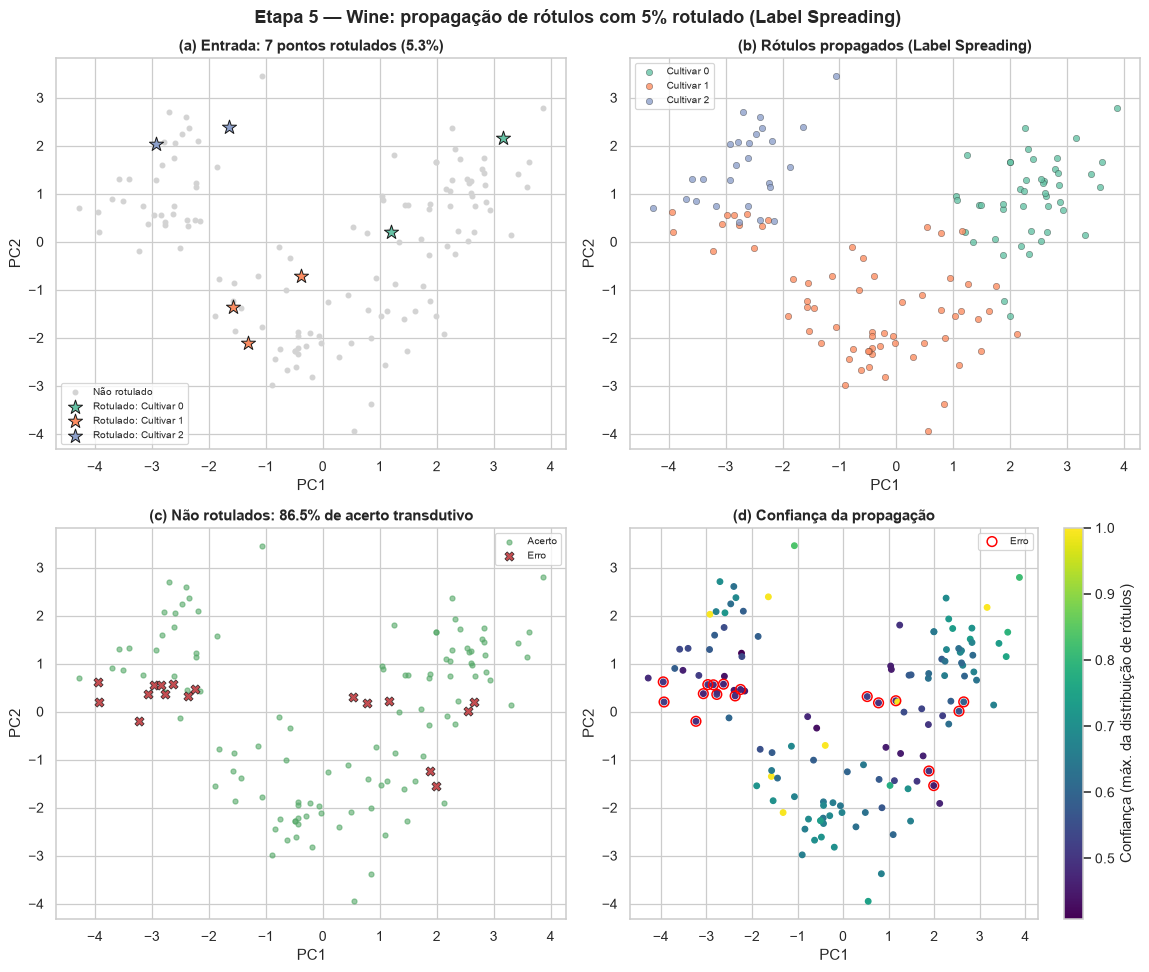

Wine: confiança média nos acertos = 0.617 | nos erros = 0.500


In [34]:
for nome, d in DADOS.items():
    X, y, Z = d["X_tr_sc"], d["y_tr"], d["Z_tr"]
    y_semi, idx_rot, semente = sortear_rotulados(nome, y, 0.05, 0)
    modelo_ls = [m for m in SEMI[nome] if m.startswith("Label Spreading")][0]
    ls = criar_modelos(nome, semente, len(idx_rot), X.shape[1])[modelo_ls].fit(X, y_semi)
    inferido = ls.transduction_
    confianca = ls.label_distributions_.max(axis=1)
    nao_rot = y_semi == -1
    acerto = inferido == y

    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    ax = axes[0, 0]
    ax.scatter(Z[nao_rot, 0], Z[nao_rot, 1], s=14, color="lightgray", label="Não rotulado")
    for c, nome_c in enumerate(d["classes"]):
        m = y_semi == c
        ax.scatter(Z[m, 0], Z[m, 1], s=140, marker="*", color=PALETA_CLASSES[c], edgecolor="k", lw=0.8,
                   label=f"Rotulado: {nome_c}")
    ax.set_title(f"(a) Entrada: {len(idx_rot)} pontos rotulados ({len(idx_rot) / len(y):.1%})")
    ax.legend(fontsize=8)
    desenhar_particao(axes[0, 1], Z, inferido, f"(b) Rótulos propagados ({modelo_ls})", nomes=d["classes"])
    ax = axes[1, 0]
    ax.scatter(Z[nao_rot & acerto, 0], Z[nao_rot & acerto, 1], s=16, color="#55a868", alpha=0.6, label="Acerto")
    ax.scatter(Z[nao_rot & ~acerto, 0], Z[nao_rot & ~acerto, 1], s=55, color="#c44e52", marker="X",
               edgecolor="k", lw=0.5, label="Erro")
    ax.set_title(f"(c) Não rotulados: {acerto[nao_rot].mean():.1%} de acerto transdutivo")
    ax.legend(fontsize=8)
    ax = axes[1, 1]
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=confianca, cmap="viridis", s=20, vmin=confianca.min(), vmax=1)
    ax.scatter(Z[nao_rot & ~acerto, 0], Z[nao_rot & ~acerto, 1], s=60, facecolor="none", edgecolor="red", lw=1.2,
               label="Erro")
    fig.colorbar(sc, ax=ax, label="Confiança (máx. da distribuição de rótulos)")
    ax.set_title("(d) Confiança da propagação")
    ax.legend(fontsize=8)
    for a in axes.ravel():
        a.set_xlabel("PC1")
        a.set_ylabel("PC2")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: propagação de rótulos com 5% rotulado ({modelo_ls})")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_propagacao_rotulos")
    print(f"{d['titulo']}: confiança média nos acertos = {confianca[nao_rot & acerto].mean():.3f} | "
          f"nos erros = {confianca[nao_rot & ~acerto].mean() if (nao_rot & ~acerto).any() else float('nan'):.3f}")

#### 5.2.8 Sensibilidade aos hiperparâmetros

Partindo da configuração de cada script, variamos um hiperparâmetro por vez (com as mesmas repetições do protocolo):

- **Label Spreading:** no Breast Cancer (grafo kNN), o número de vizinhos `n_neighbors`; no Wine (kernel RBF), a largura γ, como múltiplo do γ = 1/13 do script. Em ambos, também o coeficiente de suavização α.
- **Self-Training:** o limiar de confiança para aceitar pseudo-rótulos, junto com a fração de pontos pseudo-rotulados e a acurácia desses pseudo-rótulos.
- **KNN (baseline):** o número de vizinhos k.

Em grafos kNN muito esparsos, o grafo pode se partir em componentes sem nenhum ponto rotulado. Nesses pontos a distribuição de rótulos fica indefinida, e o scikit-learn devolve a classe de índice 0. Por isso medimos também a **% de pontos de teste com rótulo indefinido**.

Configurações do Label Spreading com pontos de teste de rótulo indefinido (média das repetições, %):
Dataset        Teste           Valor  Taxa
breast_cancer  LS alpha        0.01   0.05     0.28
               LS n_neighbors  3.00   0.05    26.57
                                      0.10    10.35
                                      0.20     0.28


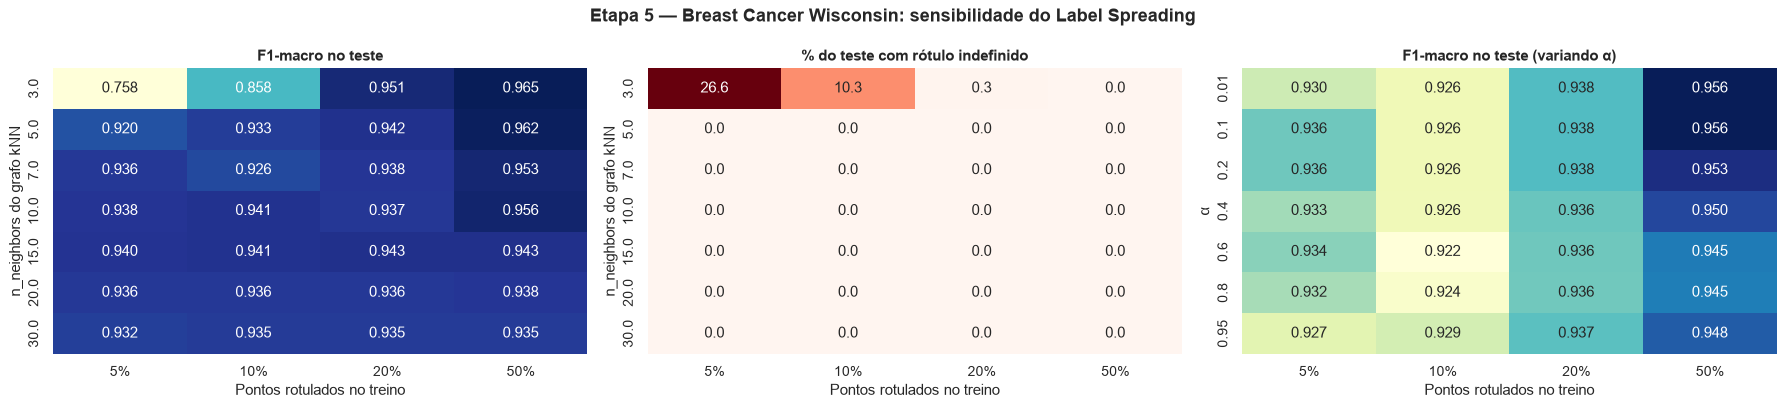

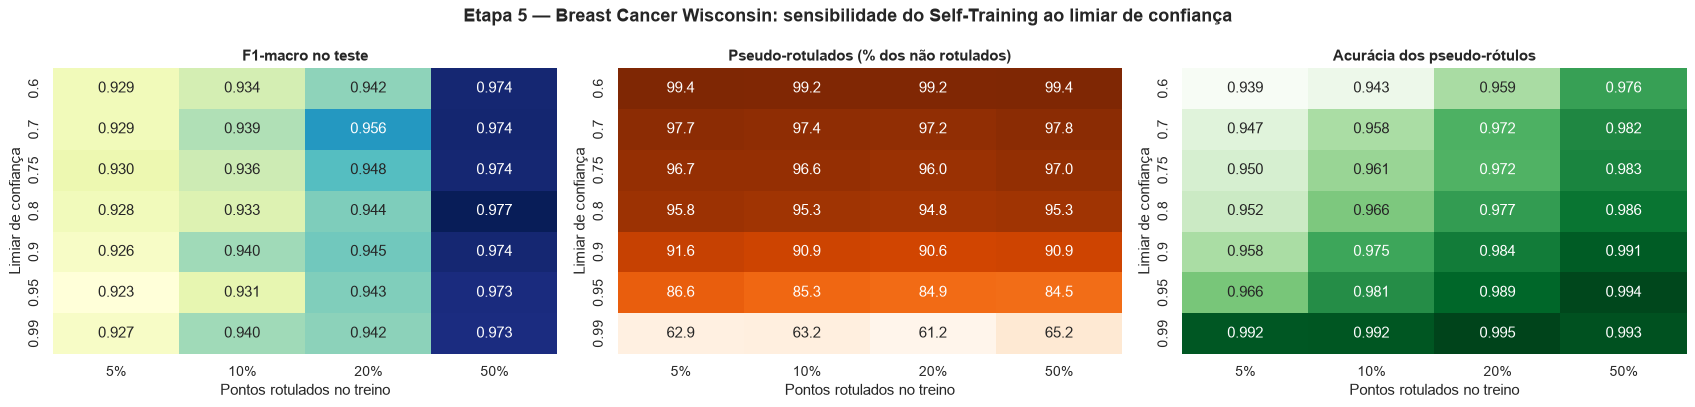

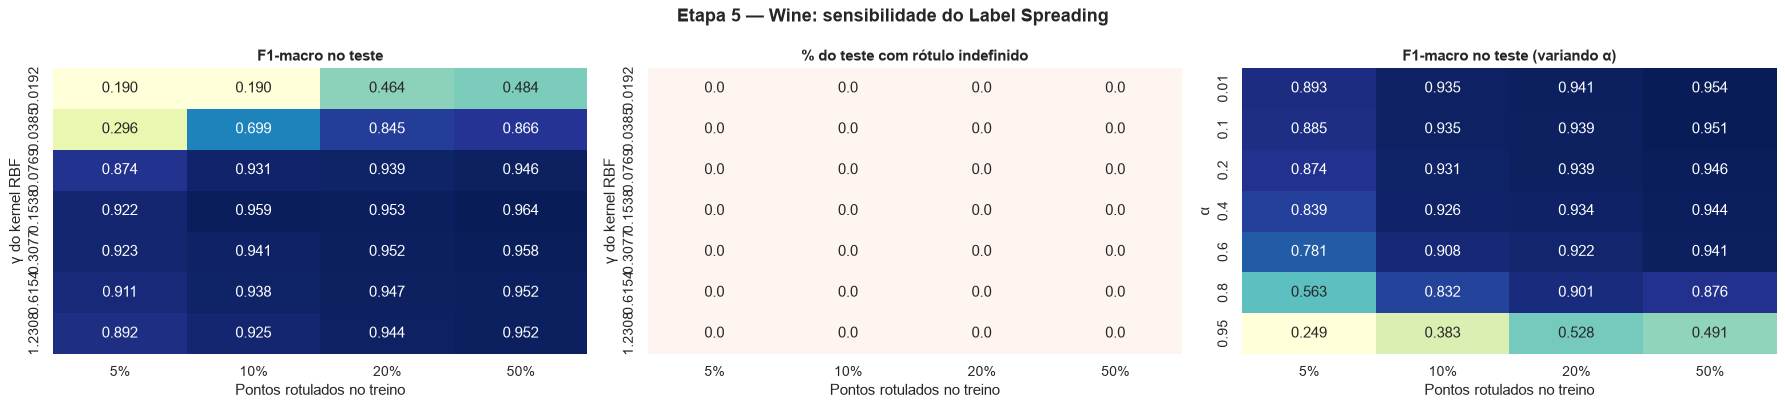

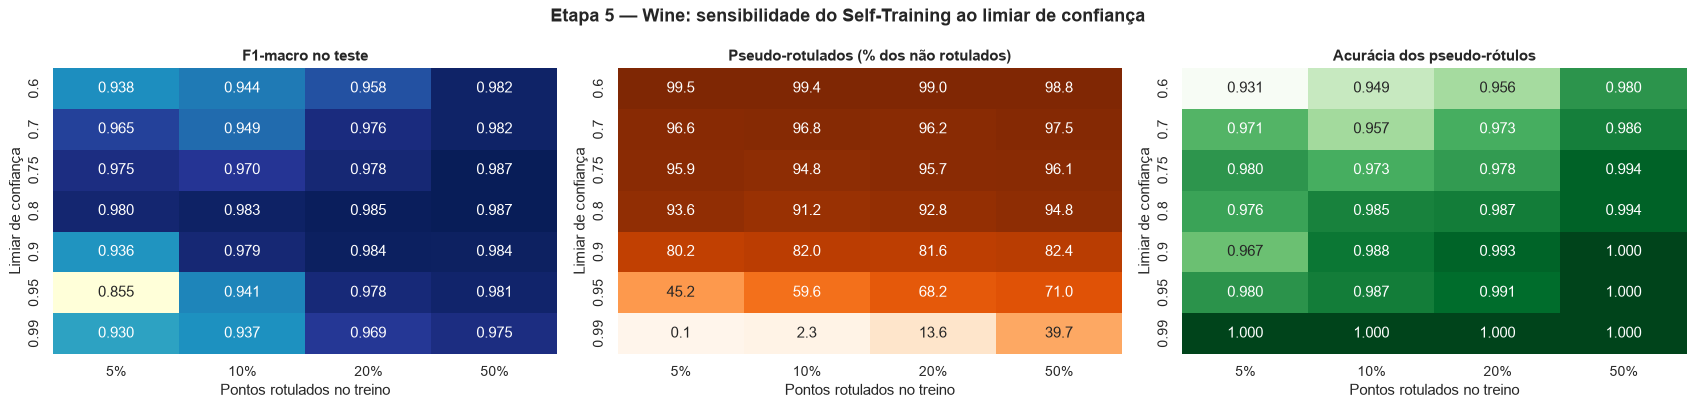

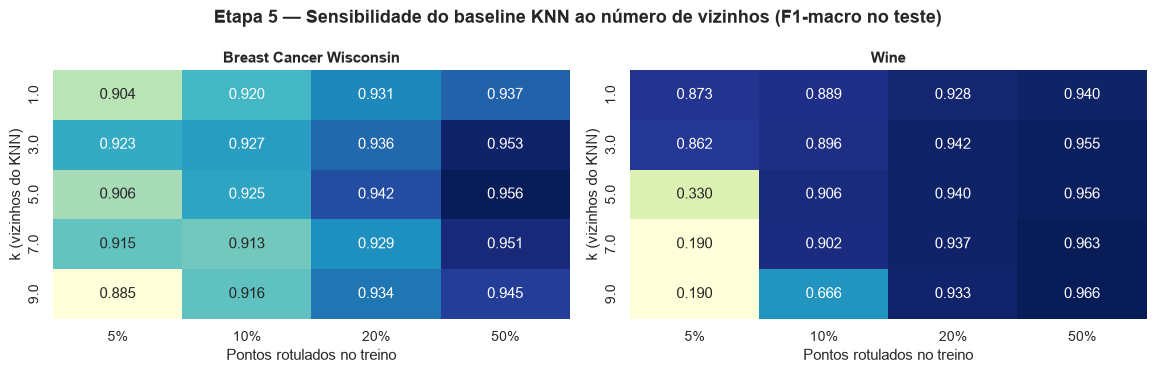

In [35]:
TAXAS_SENS = [0.05, 0.10, 0.20, 0.50]
GRADES = {
    "breast_cancer": {"LS": ("n_neighbors", [3, 5, 7, 10, 15, 20, 30])},
    "wine": {"LS": ("gamma", [m / 13 for m in [0.25, 0.5, 1, 2, 4, 8, 16]])},
}
ALFA_GRADE = [0.01, 0.1, 0.2, 0.4, 0.6, 0.8, 0.95]
LIMIAR_GRADE = [0.6, 0.7, 0.75, 0.8, 0.9, 0.95, 0.99]
K_KNN_GRADE = [1, 3, 5, 7, 9]

registros_sens = []
for nome, d in DADOS.items():
    X, y, X_te, y_te = d["X_tr_sc"], d["y_tr"], d["X_te_sc"], d["y_te"]
    modelo_ls = [m for m in SEMI[nome] if m.startswith("Label Spreading")][0]
    modelo_st = [m for m in SEMI[nome] if m.startswith("Self-Training")][0]
    modelo_knn = "KNN (Baseline)"
    param_ls, valores_ls = GRADES[nome]["LS"]
    for taxa in TAXAS_SENS:
        for rep in range(PROTOCOLO[nome]["repeticoes"]):
            y_semi, idx_rot, semente = sortear_rotulados(nome, y, taxa, rep)
            n_rot = len(idx_rot)
            testes = ([("LS " + param_ls, v, modelo_ls, {param_ls: v}) for v in valores_ls]
                      + [("LS alpha", a, modelo_ls, {"alpha": a}) for a in ALFA_GRADE]
                      + [("ST limiar", l, modelo_st, {"limiar": l}) for l in LIMIAR_GRADE]
                      + [("KNN k", k, modelo_knn, {"k_knn": k}) for k in K_KNN_GRADE])
            for teste, valor, modelo, ajuste in testes:
                clf = criar_modelos(nome, semente, n_rot, X.shape[1], **ajuste)[modelo]
                registro = {"Dataset": nome, "Teste": teste, "Valor": valor, "Taxa": taxa}
                if modelo == modelo_knn:
                    clf.fit(X[idx_rot], y[idx_rot])
                else:
                    clf.fit(X, y_semi)
                with np.errstate(invalid="ignore", divide="ignore"):  # pontos sem rótulo alcançável (contados)
                    if teste.startswith("LS"):
                        registro["Teste com rótulo indefinido (%)"] = 100 * np.isnan(clf.predict_proba(X_te)).any(axis=1).mean()
                    y_pred = clf.predict(X_te)
                registro["F1"] = f1_score(y_te, y_pred, average="macro")
                if teste == "ST limiar":
                    pseudo = clf.labeled_iter_ > 0
                    registro["Pseudo-rotulados (% dos não rotulados)"] = 100 * pseudo.sum() / (y_semi == -1).sum()
                    registro["Acurácia dos pseudo-rótulos"] = (clf.transduction_[pseudo] == y[pseudo]).mean() if pseudo.any() else np.nan
                registros_sens.append(registro)
SENS = pd.DataFrame(registros_sens)
SENS["Valor"] = SENS["Valor"].map(lambda v: int(v) if float(v).is_integer() else round(float(v), 4)).astype(object)
SENS.to_csv(PASTA_METRICAS / "E5_sensibilidade_hiperparametros.csv", index=False)
indef = (SENS.dropna(subset=["Teste com rótulo indefinido (%)"])
         .groupby(["Dataset", "Teste", "Valor", "Taxa"])["Teste com rótulo indefinido (%)"].mean())
indef = indef[indef > 0]
print("Configurações do Label Spreading com pontos de teste de rótulo indefinido (média das repetições, %):")
print(indef.round(2).to_string() if len(indef) else "nenhuma")

for nome, d in DADOS.items():
    sub = SENS[SENS["Dataset"] == nome]
    param_ls = GRADES[nome]["LS"][0]
    rotulo_ls = "n_neighbors do grafo kNN" if param_ls == "n_neighbors" else "γ do kernel RBF"
    fig, axes = plt.subplots(1, 3, figsize=(20, 4.6))
    paineis = [(axes[0], "LS " + param_ls, "F1", rotulo_ls, "YlGnBu", ".3f", "F1-macro no teste"),
               (axes[1], "LS " + param_ls, "Teste com rótulo indefinido (%)", rotulo_ls, "Reds", ".1f",
                "% do teste com rótulo indefinido"),
               (axes[2], "LS alpha", "F1", "α", "YlGnBu", ".3f", "F1-macro no teste (variando α)")]
    for ax, teste, metrica, rotulo, cmap, fmt, titulo in paineis:
        tab = sub[sub["Teste"] == teste].pivot_table(index="Valor", columns="Taxa", values=metrica, aggfunc="mean")
        sns.heatmap(tab, annot=True, fmt=fmt, cmap=cmap, ax=ax, cbar=False, xticklabels=[f"{t:.0%}" for t in tab.columns])
        ax.set_xlabel("Pontos rotulados no treino")
        ax.set_ylabel(rotulo)
        ax.set_title(titulo)
    fig.suptitle(f"Etapa 5 — {d['titulo']}: sensibilidade do Label Spreading")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_sensibilidade_label_spreading")

    st_sub = sub[sub["Teste"] == "ST limiar"]
    fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
    for ax, metrica, cmap, fmt in [(axes[0], "F1", "YlGnBu", ".3f"),
                                   (axes[1], "Pseudo-rotulados (% dos não rotulados)", "Oranges", ".1f"),
                                   (axes[2], "Acurácia dos pseudo-rótulos", "Greens", ".3f")]:
        tab = st_sub.pivot_table(index="Valor", columns="Taxa", values=metrica, aggfunc="mean")
        sns.heatmap(tab, annot=True, fmt=fmt, cmap=cmap, ax=ax, cbar=False, xticklabels=[f"{t:.0%}" for t in tab.columns])
        ax.set_xlabel("Pontos rotulados no treino")
        ax.set_ylabel("Limiar de confiança")
        ax.set_title(metrica if metrica != "F1" else "F1-macro no teste")
    fig.suptitle(f"Etapa 5 — {d['titulo']}: sensibilidade do Self-Training ao limiar de confiança")
    plt.tight_layout()
    salvar_figura(fig, f"E5_{nome}_sensibilidade_self_training")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (nome, d) in zip(axes, DADOS.items()):
    tab = SENS[(SENS["Dataset"] == nome) & (SENS["Teste"] == "KNN k")].pivot_table(
        index="Valor", columns="Taxa", values="F1", aggfunc="mean")
    sns.heatmap(tab, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, cbar=False, xticklabels=[f"{t:.0%}" for t in tab.columns])
    ax.set_xlabel("Pontos rotulados no treino")
    ax.set_ylabel("k (vizinhos do KNN)")
    ax.set_title(d["titulo"])
fig.suptitle("Etapa 5 — Sensibilidade do baseline KNN ao número de vizinhos (F1-macro no teste)")
plt.tight_layout()
salvar_figura(fig, "E5_sensibilidade_knn_baseline")

#### 5.2.9 Teste estatístico pareado (Wilcoxon)

Para cada taxa comparamos o **melhor método semi-supervisionado** do dataset (maior F1 médio entre todas as taxas) com cada *baseline*, usando o teste de postos sinalizados de Wilcoxon sobre as repetições pareadas (mesmos pontos rotulados).

**Atenção ao tamanho da amostra:** com as 5 repetições do Breast Cancer, o menor p-valor bicaudal possível é 2/2⁵ = 0,0625, então **nenhuma** diferença pode ser declarada significativa a 5%. Com as 10 repetições do Wine, o mínimo é 2/2¹⁰ ≈ 0,002. Além disso, todas as repetições usam o mesmo conjunto de teste, então os p-valores são indicativos.

Breast Cancer Wisconsin — melhor semi-supervisionado: Self-Training LR (Semi)


ΔF1 médio Vitórias semi  Empates  \
Taxa Baseline                                                           
0.05 KNN (Baseline)                     0.0235           4/5        1   
     Regressão Logística (Baseline)     0.0044           3/5        1   
0.10 KNN (Baseline)                     0.0110           3/5        1   
     Regressão Logística (Baseline)    -0.0033           1/5        2   
0.20 KNN (Baseline)                     0.0065           4/5        0   
     Regressão Logística (Baseline)     0.0012           2/5        1   
0.30 KNN (Baseline)                     0.0157           5/5        0   
     Regressão Logística (Baseline)    -0.0014           1/5        2   
0.40 KNN (Baseline)                     0.0139           5/5        0   
     Regressão Logística (Baseline)    -0.0046           2/5        0   
0.50 KNN (Baseline)                     0.0185           5/5        0   
     Regressão Logística (Baseline)     0.0015           2/5        1   
0.60 KNN (Baseline)                     0.0184           5/5        0   
     Regressão Logística (Baseline)    -0.0000           1/5        3   
0.70 KNN (Baseline)                     0.0184           5/5        0   
     Regressão Logística (Baseline)     0.0000           0/5        5   

                                     p-valor Significativo (p<0,05)  
Taxa Baseline                                                        
0.05 KNN (Baseline)                   0.1250                    não  
     Regressão Logística (Baseline)   0.6250                    não  
0.10 KNN (Baseline)                   0.2500                    não  
     Regressão Logística (Baseline)   0.5000                    não  
0.20 KNN (Baseline)                   0.1875                    não  
     Regressão Logística (Baseline)   1.0000                    não  
0.30 KNN (Baseline)                   0.0625                    não  
     Regressão Logística (Baseline)   1.0000                    não  
0.40 KNN (Baseline)                   0.0625                    não  
     Regressão Logística (Baseline)   0.6250                    não  
0.50 KNN (Baseline)                   0.0625                    não  
     Regressão Logística (Baseline)   0.8750                    não  
0.60 KNN (Baseline)                   0.0625                    não  
     Regressão Logística (Baseline)   1.0000                    não  
0.70 KNN (Baseline)                   0.0625                    não  
     Regressão Logística (Baseline)   1.0000                    não

Wine — melhor semi-supervisionado: Self-Training (LogReg)


ΔF1 médio Vitórias semi  Empates  p-valor  \
Taxa Baseline                                                               
0.05 KNN (Baseline)                0.1177         10/10        0   0.0020   
     Reg. Logistica (Baseline)     0.0502          8/10        2   0.0078   
0.10 KNN (Baseline)                0.0768         10/10        0   0.0020   
     Reg. Logistica (Baseline)     0.0461          9/10        1   0.0039   
0.20 KNN (Baseline)                0.0452          9/10        1   0.0039   
     Reg. Logistica (Baseline)     0.0143          6/10        3   0.0938   
0.30 KNN (Baseline)                0.0062          6/10        2   0.2969   
     Reg. Logistica (Baseline)     0.0127          5/10        5   0.0625   
0.50 KNN (Baseline)                0.0308          9/10        1   0.0039   
     Reg. Logistica (Baseline)     0.0136          5/10        3   0.1406   
0.70 KNN (Baseline)                0.0352          9/10        0   0.0039   
     Reg. Logistica (Baseline)     0.0046          3/10        6   0.6250   

                               Significativo (p<0,05)  
Taxa Baseline                                          
0.05 KNN (Baseline)                               sim  
     Reg. Logistica (Baseline)                    sim  
0.10 KNN (Baseline)                               sim  
     Reg. Logistica (Baseline)                    sim  
0.20 KNN (Baseline)                               sim  
     Reg. Logistica (Baseline)                    não  
0.30 KNN (Baseline)                               não  
     Reg. Logistica (Baseline)                    não  
0.50 KNN (Baseline)                               sim  
     Reg. Logistica (Baseline)                    não  
0.70 KNN (Baseline)                               sim  
     Reg. Logistica (Baseline)                    não

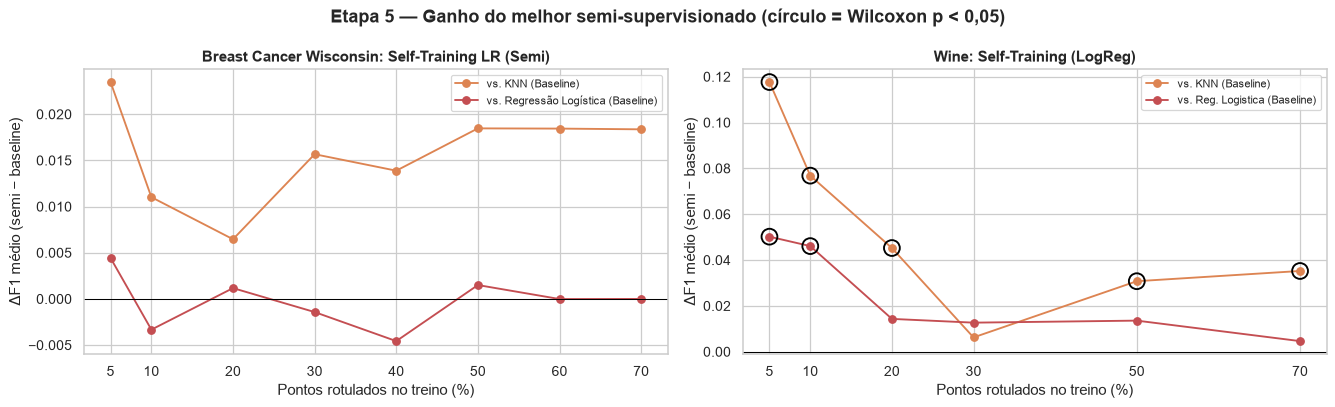

In [36]:
def p_wilcoxon(a, b):
    a, b = np.asarray(a), np.asarray(b)
    if np.allclose(a - b, 0):
        return 1.0
    return float(stats.wilcoxon(a, b).pvalue)


def f1_por_rep(nome, modelo, taxa):
    return RES[(RES["Dataset"] == nome) & (RES["Modelo"] == modelo) & (RES["Taxa"] == taxa)].sort_values("Rep")["F1"].values


registros_w = []
for nome, d in DADOS.items():
    for taxa in PROTOCOLO[nome]["taxas"]:
        f1_semi = f1_por_rep(nome, d["melhor_semi"], taxa)
        for base in BASELINES[nome]:
            f1_base = f1_por_rep(nome, base, taxa)
            p = p_wilcoxon(f1_semi, f1_base)
            registros_w.append({"Dataset": d["titulo"], "Taxa": taxa, "Semi-supervisionado": d["melhor_semi"],
                                "Baseline": base, "ΔF1 médio": (f1_semi - f1_base).mean(),
                                "Vitórias semi": f"{int((f1_semi > f1_base).sum())}/{len(f1_semi)}",
                                "Empates": int(np.isclose(f1_semi, f1_base).sum()), "p-valor": p,
                                "Significativo (p<0,05)": "sim" if p < 0.05 else "não"})
WILCOXON = pd.DataFrame(registros_w)
WILCOXON.to_csv(PASTA_METRICAS / "E5_wilcoxon_semi_vs_baselines.csv", index=False)
for titulo, sub in WILCOXON.groupby("Dataset", sort=False):
    print(f"{titulo} — melhor semi-supervisionado: {sub['Semi-supervisionado'].iloc[0]}")
    display(sub.drop(columns=["Dataset", "Semi-supervisionado"]).round(4).set_index(["Taxa", "Baseline"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, (titulo, sub) in zip(axes, WILCOXON.groupby("Dataset", sort=False)):
    for base, cor in zip(sub["Baseline"].unique(), ["#dd8452", "#c44e52"]):
        s = sub[sub["Baseline"] == base]
        ax.plot(s["Taxa"] * 100, s["ΔF1 médio"], "o-", color=cor, label=f"vs. {base}")
        sig = s["p-valor"] < 0.05
        ax.scatter(s.loc[sig, "Taxa"] * 100, s.loc[sig, "ΔF1 médio"], s=160, facecolor="none", edgecolor="black",
                   lw=1.5, zorder=5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(sorted(sub["Taxa"].unique() * 100))
    ax.set_xlabel("Pontos rotulados no treino (%)")
    ax.set_ylabel("ΔF1 médio (semi − baseline)")
    ax.set_title(f"{titulo}: {sub['Semi-supervisionado'].iloc[0]}")
    ax.legend(fontsize=9)
fig.suptitle("Etapa 5 — Ganho do melhor semi-supervisionado (círculo = Wilcoxon p < 0,05)")
plt.tight_layout()
salvar_figura(fig, "E5_wilcoxon_ganho")

## 6. Avaliação e interpretação (Etapa 6)

Esta etapa sintetiza o que os modelos revelaram sobre os dados. Como lembra a proposta, *os dados são compreendidos através dos modelos*.

### 6.1 Espectro completo de supervisão: de 0% a 100% de rótulos

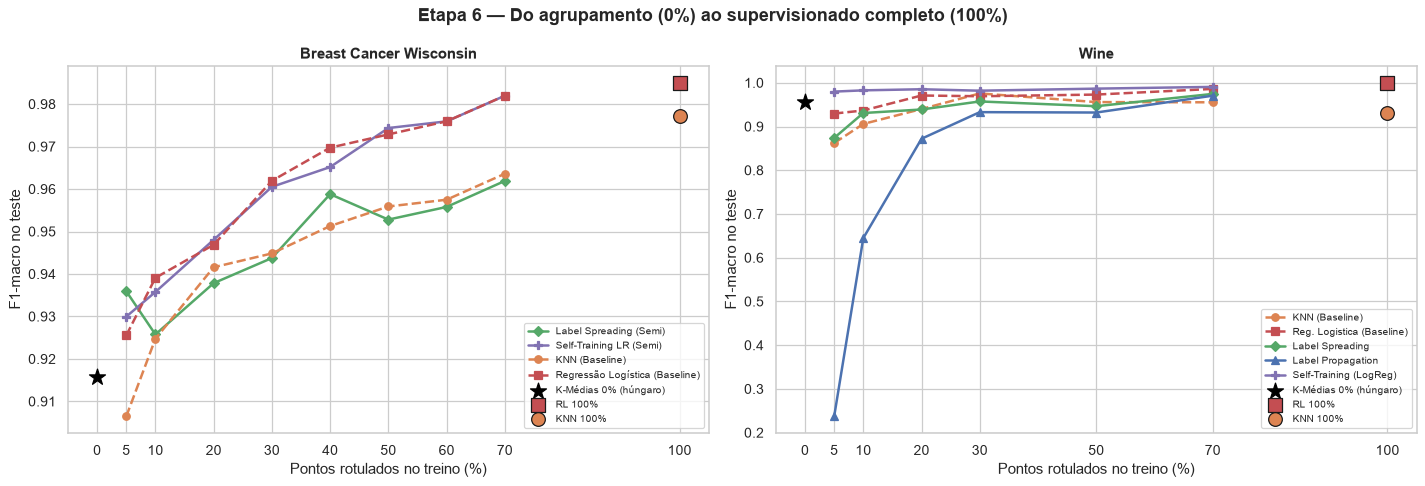

Dataset,Breast Cancer Wisconsin,Wine
K-Médias 0% (húngaro),0.9158,0.9563
Melhor baseline 5%,0.9255,0.9296
Melhor semi 5%,0.9359,0.9798
Melhor baseline 10%,0.9391,0.9366
Melhor semi 10%,0.9358,0.9827
Melhor baseline 30%,0.9619,0.9756
Melhor semi 30%,0.9605,0.9819
Melhor baseline 70%,0.9820,0.9860
Melhor semi 70%,0.9820,0.9906
RL 100%,0.9850,1.0000


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (nome, d) in zip(axes, DADOS.items()):
    sub = RESUMO[RESUMO["Dataset"] == nome]
    for modelo in PROTOCOLO[nome]["modelos"]:
        s = sub[sub["Modelo"] == modelo]
        ax.plot(s["Taxa"] * 100, s["F1_media"], lw=2, label=modelo, **ESTILO[modelo])
    ax.scatter([0], [d["ref_kmeans_0"]["F1"]], s=180, marker="*", color="black", zorder=6,
               label="K-Médias 0% (húngaro)")
    ax.scatter([100], [d["ref_100"]["RL 100%"]["F1"]], s=120, marker="s", color="#c44e52", edgecolor="k", zorder=6,
               label="RL 100%")
    ax.scatter([100], [d["ref_100"]["KNN 100%"]["F1"]], s=120, marker="o", color="#dd8452", edgecolor="k", zorder=6,
               label="KNN 100%")
    ax.set_xticks([0] + [t * 100 for t in PROTOCOLO[nome]["taxas"]] + [100])
    ax.set_xlabel("Pontos rotulados no treino (%)")
    ax.set_ylabel("F1-macro no teste")
    ax.set_title(d["titulo"])
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Etapa 6 — Do agrupamento (0%) ao supervisionado completo (100%)")
plt.tight_layout()
salvar_figura(fig, "E6_espectro_supervisao")

tabela_espectro = []
for nome, d in DADOS.items():
    linha = {"Dataset": d["titulo"], "K-Médias 0% (húngaro)": d["ref_kmeans_0"]["F1"]}
    for taxa in [0.05, 0.10, 0.30, 0.70]:
        s = RESUMO[(RESUMO["Dataset"] == nome) & (RESUMO["Taxa"] == taxa)].set_index("Modelo")["F1_media"]
        linha[f"Melhor baseline {taxa:.0%}"] = s[BASELINES[nome]].max()
        linha[f"Melhor semi {taxa:.0%}"] = s[SEMI[nome]].max()
    linha["RL 100%"] = d["ref_100"]["RL 100%"]["F1"]
    linha["KNN 100%"] = d["ref_100"]["KNN 100%"]["F1"]
    tabela_espectro.append(linha)
df_espectro = pd.DataFrame(tabela_espectro).set_index("Dataset")
df_espectro.to_csv(PASTA_METRICAS / "E6_espectro_supervisao.csv")
display(df_espectro.T.round(4))

### 6.2 O que a Regressão Logística revela sobre os atributos

Treinada com 100% dos rótulos no espaço padronizado, a Regressão Logística tem coeficientes comparáveis entre si: o sinal indica a direção do efeito e a magnitude indica a importância *condicional* (dados os demais atributos). Comparamos esses coeficientes com a relevância univariada da Seção 3.4.

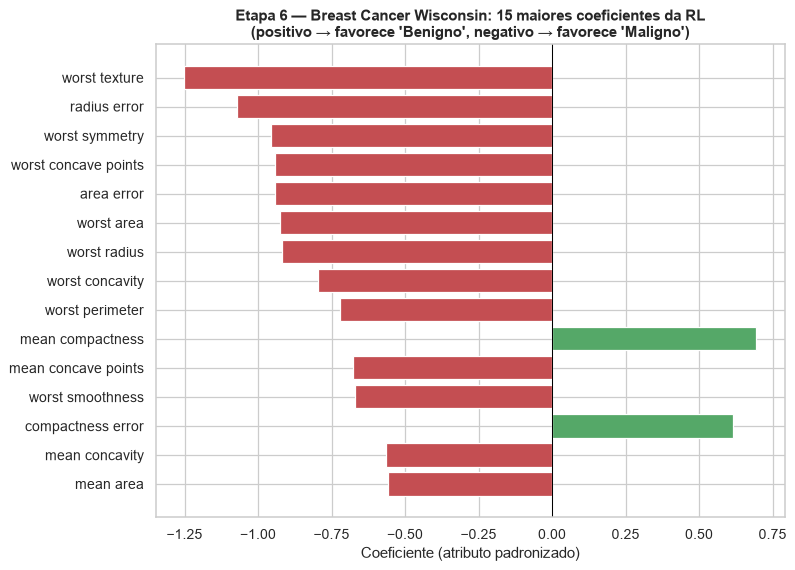

Breast Cancer Wisconsin: correlação de Spearman entre |coeficiente| da RL e F da ANOVA = 0.589
  5 atributos mais importantes na RL: ['worst texture', 'radius error', 'worst symmetry', 'worst concave points', 'area error']
  5 atributos mais relevantes na ANOVA: ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter'] 



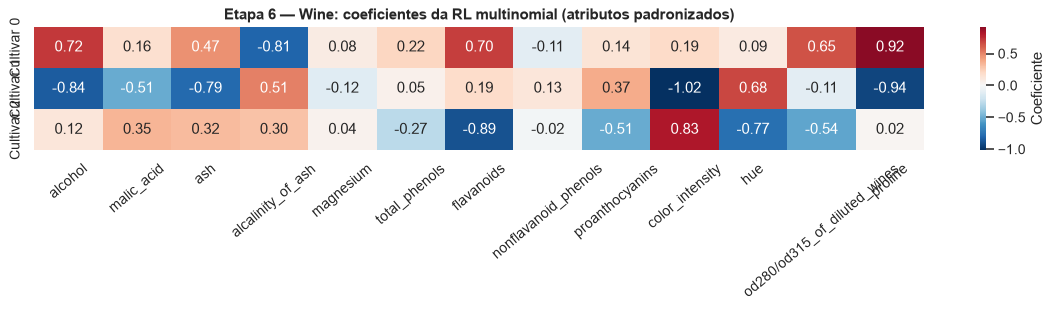

Wine: correlação de Spearman entre |coeficiente| da RL e F da ANOVA = 0.670
  5 atributos mais importantes na RL: ['color_intensity', 'proline', 'flavanoids', 'alcohol', 'alcalinity_of_ash']
  5 atributos mais relevantes na ANOVA: ['flavanoids', 'proline', 'od280/od315_of_diluted_wines', 'alcohol', 'color_intensity'] 



In [38]:
for nome, d in DADOS.items():
    rl = LogisticRegression(max_iter=1000, random_state=42).fit(d["X_tr_sc"], d["y_tr"])
    atributos = d["X"].columns
    if rl.coef_.shape[0] == 1:
        coef = pd.Series(rl.coef_[0], index=atributos)
        importancia = coef.abs()
        top = importancia.sort_values(ascending=False).index[:15][::-1]
        fig, ax = plt.subplots(figsize=(9, 6.5))
        ax.barh(top, coef[top], color=["#55a868" if v > 0 else "#c44e52" for v in coef[top]])
        ax.axvline(0, color="black", lw=0.8)
        ax.set_xlabel("Coeficiente (atributo padronizado)")
        ax.set_title(f"Etapa 6 — {d['titulo']}: 15 maiores coeficientes da RL\n"
                     f"(positivo → favorece '{d['classes'][1]}', negativo → favorece '{d['classes'][0]}')")
    else:
        coef = pd.DataFrame(rl.coef_, index=d["classes"], columns=atributos)
        importancia = coef.abs().mean(axis=0)
        fig, ax = plt.subplots(figsize=(13, 3.6))
        sns.heatmap(coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Coeficiente"})
        ax.set_title(f"Etapa 6 — {d['titulo']}: coeficientes da RL multinomial (atributos padronizados)")
        ax.tick_params(axis="x", rotation=40)
    plt.tight_layout()
    salvar_figura(fig, f"E6_{nome}_coeficientes_rl")
    rho = stats.spearmanr(importancia[d["relevancia"].index], d["relevancia"]["F_ANOVA"]).statistic
    print(f"{d['titulo']}: correlação de Spearman entre |coeficiente| da RL e F da ANOVA = {rho:.3f}")
    print("  5 atributos mais importantes na RL:", list(importancia.sort_values(ascending=False).index[:5]))
    print("  5 atributos mais relevantes na ANOVA:", list(d["relevancia"].index[:5]), "\n")

### 6.3 Análise de erros: quais amostras são difíceis?

Para cada amostra de teste calculamos a **taxa de erro** considerando todos os modelos, taxas e repetições do experimento da Seção 5.2. Amostras com taxa de erro alta são "difíceis" para qualquer modelo. Elas são comparadas com a probabilidade atribuída pela Regressão Logística treinada com 100% dos rótulos.

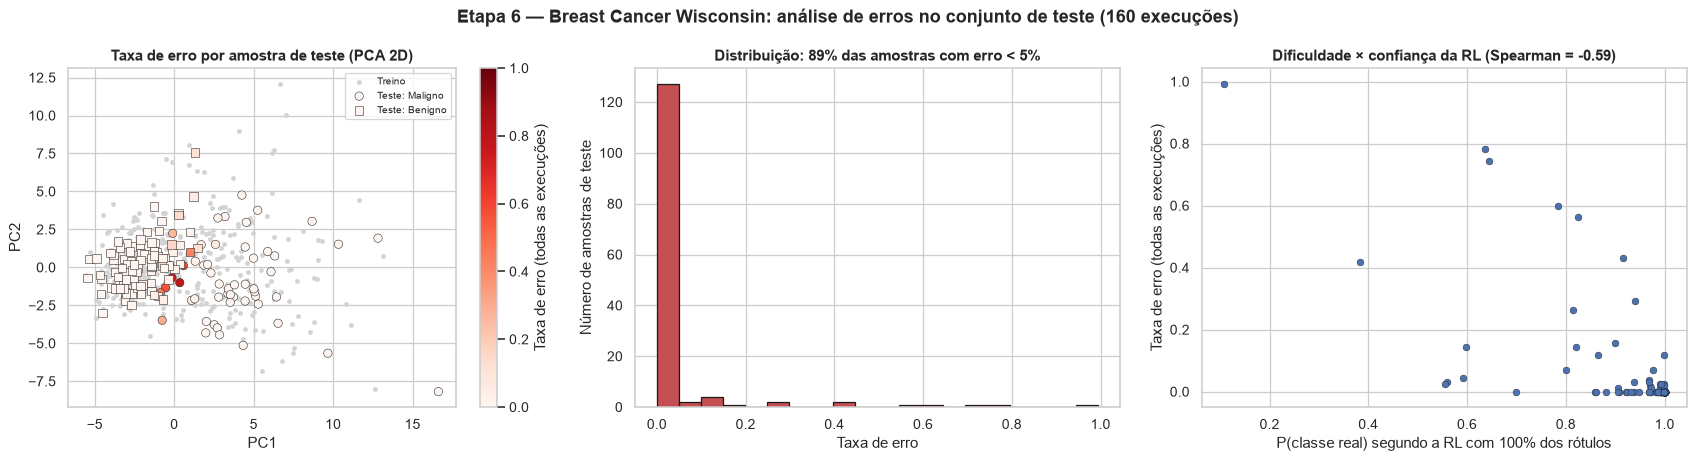

Breast Cancer Wisconsin: 88.8% das amostras com taxa de erro < 5%; 6 amostras mais difíceis:


,Classe real,Taxa de erro,P(classe real) RL 100%,worst concave points,worst perimeter,mean concave points,worst radius
0,Maligno,0.994,0.107,0.138,110.3,0.051,16.57
1,Maligno,0.781,0.637,0.112,112.0,0.054,16.84
2,Maligno,0.744,0.645,0.125,117.7,0.041,17.77
3,Maligno,0.600,0.784,0.122,108.4,0.049,16.21
4,Maligno,0.562,0.825,0.136,102.2,0.053,15.79
5,Maligno,0.431,0.917,0.116,116.6,0.034,17.98


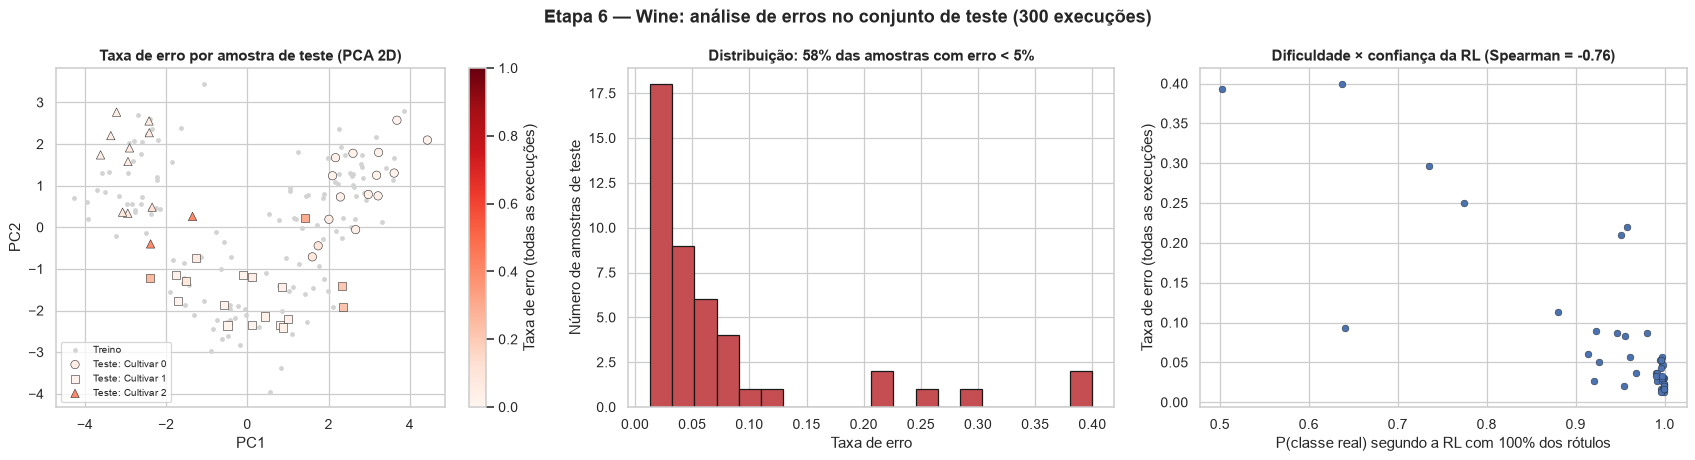

Wine: 57.8% das amostras com taxa de erro < 5%; 6 amostras mais difíceis:


,Classe real,Taxa de erro,P(classe real) RL 100%,flavanoids,proline,od280/od315_of_diluted_wines,alcohol
0,Cultivar 2,0.400,0.637,1.25,630.0,1.29,12.86
1,Cultivar 2,0.393,0.503,0.58,650.0,1.51,12.51
2,Cultivar 1,0.297,0.735,5.08,465.0,3.69,11.56
3,Cultivar 1,0.250,0.774,1.25,372.0,2.12,12.77
4,Cultivar 1,0.220,0.958,3.18,502.0,3.18,13.11
5,Cultivar 1,0.210,0.951,3.75,660.0,2.77,12.37


In [39]:
for nome, d in DADOS.items():
    chaves = [k for k in PREDICOES if k[0] == nome]
    taxa_erro = np.array([PREDICOES[k] != d["y_te"] for k in chaves]).mean(axis=0)
    Z_te = d["Z_te"]
    prob_rl = LogisticRegression(max_iter=1000, random_state=42).fit(d["X_tr_sc"], d["y_tr"]).predict_proba(d["X_te_sc"])
    prob_classe_real = prob_rl[np.arange(len(d["y_te"])), d["y_te"]]

    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
    ax = axes[0]
    ax.scatter(d["Z_tr"][:, 0], d["Z_tr"][:, 1], s=8, color="lightgray", label="Treino")
    for c, nome_c in enumerate(d["classes"]):
        m = d["y_te"] == c
        sc = ax.scatter(Z_te[m, 0], Z_te[m, 1], c=taxa_erro[m], cmap="Reds", vmin=0, vmax=1, s=45,
                        marker=["o", "s", "^"][c], edgecolor="k", lw=0.4, label=f"Teste: {nome_c}")
    fig.colorbar(sc, ax=ax, label="Taxa de erro (todas as execuções)")
    ax.set_title("Taxa de erro por amostra de teste (PCA 2D)")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.legend(fontsize=8)
    axes[1].hist(taxa_erro, bins=20, color="#c44e52", edgecolor="k")
    axes[1].set_xlabel("Taxa de erro")
    axes[1].set_ylabel("Número de amostras de teste")
    axes[1].set_title(f"Distribuição: {np.mean(taxa_erro < 0.05):.0%} das amostras com erro < 5%")
    axes[2].scatter(prob_classe_real, taxa_erro, s=30, color="#4c72b0", edgecolor="k", lw=0.3)
    axes[2].set_xlabel("P(classe real) segundo a RL com 100% dos rótulos")
    axes[2].set_ylabel("Taxa de erro (todas as execuções)")
    rho = stats.spearmanr(prob_classe_real, taxa_erro).statistic
    axes[2].set_title(f"Dificuldade × confiança da RL (Spearman = {rho:.2f})")
    fig.suptitle(f"Etapa 6 — {d['titulo']}: análise de erros no conjunto de teste ({len(chaves)} execuções)")
    plt.tight_layout()
    salvar_figura(fig, f"E6_{nome}_analise_erros")

    ordem = np.argsort(-taxa_erro)[:6]
    print(f"{d['titulo']}: {np.mean(taxa_erro < 0.05):.1%} das amostras com taxa de erro < 5%; 6 amostras mais difíceis:")
    display(pd.DataFrame({
        "Classe real": [d["classes"][c] for c in d["y_te"][ordem]],
        "Taxa de erro": taxa_erro[ordem].round(3),
        "P(classe real) RL 100%": prob_classe_real[ordem].round(3),
        **{a: d["X_te"][ordem, list(d["X"].columns).index(a)].round(3) for a in d["top_atributos"]},
    }))

### 6.4 Custo computacional

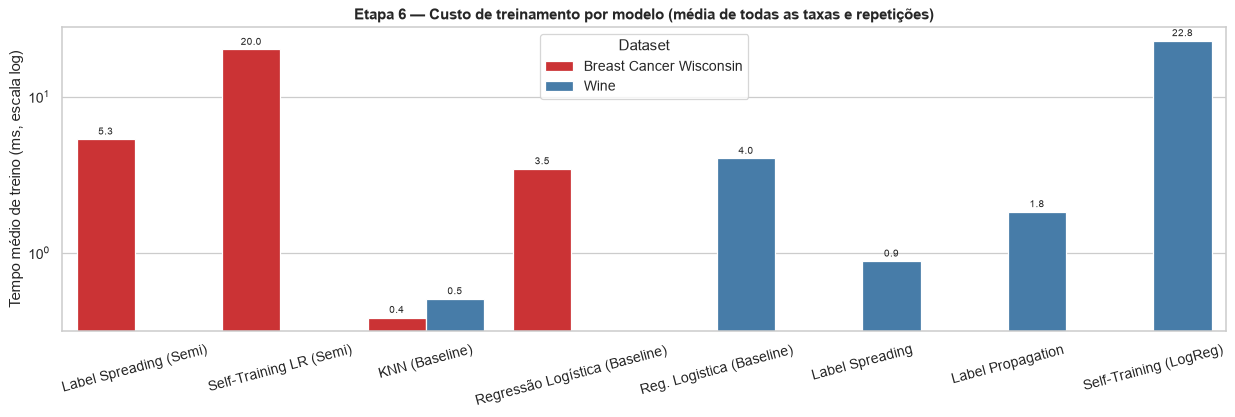

In [40]:
custo = RES.groupby(["Dataset", "Modelo"], sort=False)["Tempo (ms)"].mean().reset_index()
custo["Dataset"] = custo["Dataset"].map({k: v["titulo"] for k, v in DADOS.items()})
fig, ax = plt.subplots(figsize=(14, 4.8))
sns.barplot(data=custo, x="Modelo", y="Tempo (ms)", hue="Dataset", palette="Set1", ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=8, padding=2)
ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("Tempo médio de treino (ms, escala log)")
ax.tick_params(axis="x", rotation=15)
ax.set_title("Etapa 6 — Custo de treinamento por modelo (média de todas as taxas e repetições)")
plt.tight_layout()
salvar_figura(fig, "E6_custo_computacional")

### 6.5 Revisão das hipóteses da Etapa 1

Como a proposta observa, o KDD não é linear: a mineração pode contradizer as hipóteses iniciais. A tabela abaixo aplica os critérios objetivos definidos na Seção 1.

In [41]:
def melhor_semi_vs_baseline(nome, taxa):
    """Melhor semi e melhor baseline (F1 médio) numa taxa, com ΔF1 e p-valor de Wilcoxon pareado."""
    medias = RESUMO.query("Dataset == @nome and Taxa == @taxa").set_index("Modelo")["F1_media"]
    semi, base = medias[SEMI[nome]].idxmax(), medias[BASELINES[nome]].idxmax()
    a, b = f1_por_rep(nome, semi, taxa), f1_por_rep(nome, base, taxa)
    return semi, base, a.mean() - b.mean(), p_wilcoxon(a, b), int((a > b).sum()), len(a)


def f1_rep(titulo, representacao):
    return float(df_rep[(df_rep["Dataset"] == titulo) & (df_rep["Representação"] == representacao)]["F1 KNN (CV)"].iloc[0])


veredito = []
bc, wn = DADOS["breast_cancer"], DADOS["wine"]
f1_rl100 = bc["ref_100"]["RL 100%"]["F1"]
veredito.append({"Hipótese": "H1", "Dataset": bc["titulo"], "Evidência": f"F1 RL 100% = {f1_rl100:.3f}",
                 "Resultado": "confirmada" if f1_rl100 >= 0.95 else "refutada"})
for nome, d in DADOS.items():
    estados, textos = [], []
    for taxa in [0.05, 0.10]:
        semi, base, delta, p, vit, n = melhor_semi_vs_baseline(nome, taxa)
        estados.append("refutada" if delta <= 0 else ("confirmada" if p < 0.05 else "inconclusiva"))
        textos.append(f"{taxa:.0%}: {semi} − {base} = {delta:+.4f} (vence {vit}/{n}; p = {p:.4f})")
    resultado = (estados[0] if estados[0] == estados[1]
                 else f"5%: {estados[0]}; 10%: {estados[1]}")
    veredito.append({"Hipótese": "H2", "Dataset": d["titulo"], "Evidência": "; ".join(textos), "Resultado": resultado})
    d5, d70 = melhor_semi_vs_baseline(nome, 0.05)[2], melhor_semi_vs_baseline(nome, 0.70)[2]
    veredito.append({"Hipótese": "H3", "Dataset": d["titulo"],
                     "Evidência": f"ΔF1 (melhor semi − melhor baseline): 5% = {d5:+.4f}, 70% = {d70:+.4f}",
                     "Resultado": "confirmada" if d70 < d5 else "refutada"})

ari = {d["titulo"]: df_cluster[df_cluster["Dataset"] == d["titulo"]].set_index("Algoritmo")["ARI"] for d in DADOS.values()}
ari_km = {t: s[s.index.str.startswith("K-Médias")].iloc[0] for t, s in ari.items()}
ari_db = {t: s[s.index.str.startswith("DBSCAN")].iloc[0] for t, s in ari.items()}
veredito.append({"Hipótese": "H4", "Dataset": "ambos",
                 "Evidência": f"ARI K-Médias: Wine = {ari_km[wn['titulo']]:.3f}, Breast Cancer = {ari_km[bc['titulo']]:.3f}",
                 "Resultado": "confirmada" if ari_km[wn["titulo"]] > ari_km[bc["titulo"]] else "refutada"})
for nome, d in DADOS.items():
    t = d["titulo"]
    veredito.append({"Hipótese": "H5", "Dataset": t,
                     "Evidência": f"ARI: DBSCAN = {ari_db[t]:.3f}, K-Médias = {ari_km[t]:.3f}",
                     "Resultado": "confirmada" if ari_db[t] < ari_km[t] else "refutada"})
    f_full, f_2d = f1_rep(t, "Padronizado completo"), f1_rep(t, "PCA 2D")
    veredito.append({"Hipótese": "H6", "Dataset": t,
                     "Evidência": f"F1 KNN (CV): completo = {f_full:.3f}, PCA 2D = {f_2d:.3f} ({f_2d / f_full:.1%})",
                     "Resultado": "confirmada" if f_2d >= 0.9 * f_full else "refutada"})

VEREDITO = pd.DataFrame(veredito)
VEREDITO.to_csv(PASTA_METRICAS / "E6_veredito_hipoteses.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(VEREDITO.set_index(["Hipótese", "Dataset"]))

,,Evidência,Resultado
Hipótese,Dataset,,
H1,Breast Cancer Wisconsin,F1 RL 100% = 0.985,confirmada
H2,Breast Cancer Wisconsin,5%: Label Spreading (Semi) − Regressão Logística (Baseline) = +0.0104 (vence 4/5; p = 0.1250); 10%: Self-Training LR (Semi) − Regressão Logística (Baseline) = -0.0033 (vence 1/5; p = 0.5000),5%: inconclusiva; 10%: refutada
H3,Breast Cancer Wisconsin,"ΔF1 (melhor semi − melhor baseline): 5% = +0.0104, 70% = +0.0000",confirmada
H2,Wine,5%: Self-Training (LogReg) − Reg. Logistica (Baseline) = +0.0502 (vence 8/10; p = 0.0078); 10%: Self-Training (LogReg) − Reg. Logistica (Baseline) = +0.0461 (vence 9/10; p = 0.0039),confirmada
H3,Wine,"ΔF1 (melhor semi − melhor baseline): 5% = +0.0502, 70% = +0.0046",confirmada
H4,ambos,"ARI K-Médias: Wine = 0.908, Breast Cancer = 0.672",confirmada
H5,Breast Cancer Wisconsin,"ARI: DBSCAN = 0.025, K-Médias = 0.672",confirmada
H6,Breast Cancer Wisconsin,"F1 KNN (CV): completo = 0.962, PCA 2D = 0.932 (96.9%)",confirmada
H5,Wine,"ARI: DBSCAN = 0.602, K-Médias = 0.908",confirmada


### 6.6 Síntese: o que os modelos revelam sobre os dados

**1. O benefício do semi-supervisionado depende da estrutura dos dados, não só da escassez de rótulos.**

- **Wine (H2 e H3 confirmadas).** As cultivares formam grupos compactos (ARI do K-Médias = 0,908), então a *hipótese de cluster* vale e os pontos não rotulados ajudam muito. Com 5% de rótulos (7 amostras), o **Self-Training** atinge F1 = 0,980, contra 0,930 da Regressão Logística (+0,050; vence em 8 de 10 repetições; p = 0,008). Com 10%, o ganho é de +0,046 (p = 0,004). A partir de 20%, a vantagem deixa de ser significativa e cai para +0,005 a 70%.
- **Breast Cancer (H2: inconclusiva a 5%, refutada a 10%).** A fronteira é essencialmente linear (H1: RL com 100% dos rótulos tem F1 = 0,985, como afirma a documentação original). Com 5% de rótulos (21 amostras), o Label Spreading tem o maior F1 médio (0,936, contra 0,926 da RL; +0,010; vence em 4 de 5 repetições). Mas com apenas 5 repetições nenhum teste pode chegar a p < 0,05 (o mínimo é 0,0625), e o p obtido foi 0,125. A 10%, a RL já supera todos os semi-supervisionados. A 70%, Self-Training e RL produzem **exatamente** o mesmo F1 nas 5 repetições (0,982). A vantagem a 5% diminui com mais rótulos (H3 confirmada no sentido descritivo), mas ela própria não é estatisticamente sustentada.
- **O agrupamento como diagnóstico.** O caso 0% rotulado antecipou onde o semi-supervisionado ajudaria: quando o K-Médias já recupera as classes (Wine), os dados não rotulados agregam informação; quando não recupera (Breast Cancer), um modelo supervisionado simples com o viés indutivo certo (linear) é tão bom quanto as alternativas.

**2. Sobre os modelos.**

- **Self-Training com RL** foi o melhor semi-supervisionado em média nos dois datasets, porque herda o viés linear da RL e acrescenta pseudo-rótulos de boa qualidade. Com o limiar do script do Wine (0,80) e 5% de rótulos, 93,6% dos pontos não rotulados recebem pseudo-rótulo, com 97,6% de acerto. O limiar importa: no Wine a 5%, 0,80 dá F1 = 0,980, mas 0,95 cai para 0,855. Com limiares altos, quase nada é pseudo-rotulado e o método volta a ser a própria RL.
- **Label Propagation (Wine, kernel RBF com γ = 1/13)** colapsa com poucos rótulos (F1 = 0,237 a 5% e 0,645 a 10%) e só se recupera a partir de 30%. O **Label Spreading** com o mesmo γ não colapsa (0,874 a 5%), mas o teste de sensibilidade mostra o mesmo problema quando o kernel fica largo demais (γ = 0,25/13 → F1 = 0,19) ou a suavização forte demais (α = 0,95 → 0,25). Já com γ = 2/13, o Label Spreading chegaria a 0,922 a 5%. Os hiperparâmetros dos métodos de grafo são decisivos e foram fixados *a priori*: ajustá-los exigiria dados rotulados de validação, justamente o recurso escasso nesse cenário.
- **Label Spreading no Breast Cancer (grafo kNN, k = 7)** fica abaixo da RL a partir de 10%. Com `n_neighbors` = 3, o grafo se fragmenta e 26,6% dos pontos de teste ficam sem rótulo alcançável a 5% (o scikit-learn atribui a eles a classe 0), o que derruba o F1 para 0,758.
- **Baseline KNN.** No Wine a 5%, o script usa k = mín(5, 7 ÷ 2) = 3 (F1 = 0,862). Com k = 5 e apenas 7 rótulos, o KNN cairia para 0,330, e com k = 1 subiria para 0,873. Como as hipóteses comparam sempre com o **melhor** *baseline* de cada taxa (a RL, nesse caso), a escolha de k não infla os ganhos reportados.
- **Indutivo × transdutivo.** As diferenças são pequenas (no máximo ≈ 0,05 em F1, no Label Propagation do Wine a 10%) e mudam de sinal entre datasets e modelos, sem indicar sobreajuste sistemático aos pontos não rotulados.
- **Custo.** Todos os modelos treinam em milissegundos nesses conjuntos. O Self-Training é o mais caro (da ordem de 20 ms, porque retreina a RL a cada iteração), e o KNN o mais barato (menos de 1 ms). Os tempos absolutos variam entre máquinas e execuções.

**3. Sobre os atributos.**

- **Breast Cancer.** Os atributos mais importantes na RL (`worst texture`, `radius error`, `worst symmetry`, `worst concave points`, `area error`) diferem do ranking univariado da ANOVA (Spearman = 0,589). É consequência da forte multicolinearidade (21 pares com |r| > 0,9): a RL distribui o peso entre variáveis redundantes de tamanho, e por isso a importância *condicional* difere da *marginal*. Os **pontos côncavos** aparecem nos dois rankings e são o marcador mais robusto de malignidade. Os três atributos dos boxplots dos scripts (`mean radius`, `mean concave points`, `mean perimeter`) são fortemente discriminativos (7º, 3º e 5º lugar na ANOVA entre 30), mas não os três primeiros.
- **Wine.** Há maior concordância (Spearman = 0,670): `proline`, `flavanoids`, `alcohol` e `color_intensity` estão entre os 5 primeiros nos dois rankings. Dos atributos dos boxplots, `flavanoids` é o 1º colocado e `alcohol` e `color_intensity` ficam em 4º e 5º. `proline` (2º) e `od280/od315` (3º) não aparecem nos boxplots.

**4. Sobre os erros.** No Breast Cancer, 88,8% das amostras de teste quase nunca são erradas (taxa de erro < 5%). As 6 mais difíceis são todas **malignas** classificadas como benignas, ou seja, *falsos negativos*, o erro mais grave num contexto de triagem. Elas ficam na fronteira entre as classes no PCA. Uma delas é errada em 99,4% das execuções, e até a RL com 100% dos rótulos lhe atribui P(maligno) = 0,107. É um caso atípico, possivelmente com rótulo ruidoso, o que não é possível verificar com os dados disponíveis. No Wine, a proporção de amostras "fáceis" é menor (57,8%) porque o colapso do Label Propagation com poucos rótulos erra muitas amostras em várias execuções.

**5. Revisão do processo (o KDD não é linear).** O resultado inconclusivo no Breast Cancer leva de volta à Etapa 1. A hipótese "o semi-supervisionado ajuda quando há poucos rótulos" precisa ser condicionada à estrutura de agrupamento dos dados, verificável já na Etapa 5.1, e testada com repetições suficientes: com 5 repetições, nenhum teste pareado pode ser significativo a 5%. Uma nova iteração poderia (a) aumentar o número de repetições no Breast Cancer, (b) ajustar γ e α dos métodos de grafo com validação cruzada sobre os poucos rótulos disponíveis e (c) ajustar o limiar de decisão para reduzir falsos negativos.

**Limitações.** Há uma única partição treino/teste. No Wine, o teste tem 45 amostras, então um erro equivale a 2,2 pontos de acurácia. Os p-valores de Wilcoxon são indicativos, porque todas as repetições usam o mesmo conjunto de teste. Os protocolos dos dois scripts diferem entre si (taxas, repetições, modelos e hiperparâmetros), por isso as comparações entre os datasets são qualitativas.

## 7. Pós-processamento (Etapa 7, opcional)

Todos os resultados ficam exportados para uso no relatório e na apresentação:

- `results_notebook/figures/`: todas as figuras em PNG (200 DPI), nomeadas por etapa (`E2_…` a `E6_…`) e por dataset.
- `results_notebook/metrics/`: tabelas CSV com as métricas de cada etapa (inclusive todas as execuções individuais do experimento semi-supervisionado).

**Recomendações práticas a partir dos resultados:**

- **Breast Cancer:** num cenário com poucos laudos, uma Regressão Logística sobre atributos padronizados, treinada apenas com os casos rotulados, é a opção mais simples e mais fácil de auditar, e as alternativas semi-supervisionadas não mostraram vantagem estatisticamente sustentada sobre ela. Como os erros residuais são falsos negativos, o limiar de decisão deve ser escolhido priorizando a sensibilidade para a classe maligna. O modelo é um apoio à triagem e não substitui o diagnóstico do patologista.
- **Wine:** com apenas 7 vinhos rotulados (5%), o Self-Training com RL já atinge F1 = 0,98 usando os demais vinhos sem rótulo, o que reduz o custo de rotulagem por análise de especialista. O limiar de confiança deve ser escolhido com cuidado, porque limiares altos anulam o ganho.
- **Reprodutibilidade:** sementes fixas, versões das bibliotecas impressas na Seção 0 e todas as métricas exportadas em CSV.

In [42]:
indice = pd.DataFrame({"Figura": FIGURAS_GERADAS})
indice["Etapa"] = indice["Figura"].str.extract(r"^(E\d)")[0]
print(f"{len(indice)} figuras salvas em '{PASTA_FIGURAS}':")
print(indice.groupby("Etapa").size().rename("Quantidade").to_string(), "\n")
with pd.option_context("display.max_rows", None):
    display(indice)
print(f"Tabelas em '{PASTA_METRICAS}':", sorted(p.name for p in PASTA_METRICAS.glob("*.csv")))

66 figuras salvas em 'results_notebook\figures':
Etapa
E2     1
E3    15
E4     9
E5    35
E6     6 



,Figura,Etapa
0,E2_distribuicao_classes.png,E2
1,E3_breast_cancer_outliers_iqr.png,E3
2,E3_wine_outliers_iqr.png,E3
3,E3_breast_cancer_boxplot_padronizado.png,E3
4,E3_wine_boxplot_padronizado.png,E3
5,E3_breast_cancer_relevancia_atributos.png,E3
6,E3_wine_relevancia_atributos.png,E3
7,E3_breast_cancer_distribuicao_top_atributos.png,E3
8,E3_wine_distribuicao_top_atributos.png,E3
9,E3_breast_cancer_atributos_scripts.png,E3


Tabelas em 'results_notebook\metrics': ['E3_breast_cancer_relevancia_atributos.csv', 'E3_efeito_padronizacao.csv', 'E3_wine_relevancia_atributos.csv', 'E4_pca_variancia.csv', 'E4_separabilidade_representacoes.csv', 'E5_agrupamento_metricas.csv', 'E5_breast_cancer_dbscan_grade.csv', 'E5_breast_cancer_kmeans_varredura_k.csv', 'E5_kmeans_0pct_teste.csv', 'E5_semi_supervisionado_execucoes.csv', 'E5_semi_supervisionado_resumo.csv', 'E5_sensibilidade_hiperparametros.csv', 'E5_wilcoxon_semi_vs_baselines.csv', 'E5_wine_dbscan_grade.csv', 'E5_wine_kmeans_varredura_k.csv', 'E6_espectro_supervisao.csv', 'E6_veredito_hipoteses.csv']
